# Análisis de videos en tendencia de YouTube (Estados Unidos)
## Estrategia de posicionamiento de un canal corporativo y selección de *sponsors*

**Prueba técnica — Científico de Datos** · Mateo Felipe Fandiño Suárez · Noviembre de 2026

**Objetivo de negocio.** La empresa quiere posicionar su propio canal de YouTube para llevar tráfico a su sitio web y aumentar la probabilidad de abrir negocios. Para eso necesita (1) entender cómo se comportan los videos que llegan a tendencia en EE. UU. y (2) contar con una métrica que, en el futuro, permita decidir si usar *sponsors* y elegir los de mayor potencial de retorno.

**Metodología: CRISP-DM.** El cuaderno sigue sus seis fases. Cada sección indica la fase y justifica las decisiones.

| Fase CRISP-DM | Sección del cuaderno | Pregunta o tarea |
|---|---|---|
| 1. Comprensión del negocio | 0 | Objetivo, preguntas y criterio de éxito |
| 2. Comprensión de los datos | 1 | Lectura del CSV (estructurado) y del JSON (semiestructurado); verificación de calidad |
| 3. Preparación de los datos | 2 | Limpieza, normalización con *regex*, transformación a una fila por video y carga en SQLite |
| 4. Modelado | 3 a 8 | P1 descriptiva · P2 agrupaciones · P3 atributos de tendencia · P4 efecto temporal · P5 predicción · índice de *sponsors* |
| 5. Evaluación | dentro de cada modelo | Validación con datos de prueba, métricas y comparación con un modelo base |
| 6. Despliegue | 9 | Conclusiones, recomendaciones y tabla de *sponsors* priorizados |

**Preguntas guía**
1. ¿Qué categorías reciben más vistas y *likes*?
2. ¿Es posible encontrar agrupaciones de videos?
3. ¿Qué combinación de atributos hace que un video sea tendencia (y que se mantenga)?
4. ¿Influye la fecha u hora de publicación?
5. ¿Es posible predecir cuántas vistas o *likes* tendrá un video?
6. (Adicional) ¿Qué canales tienen mayor potencial de retorno como *sponsors*?

### 0. Configuración del entorno

Se usan paquetes de R para manipulación (`tidyverse`, `lubridate`, `jsonlite`), carga (`DBI`, `RSQLite`), estadística multivariada (`FactoMineR`, `cluster`, `mclust`), texto (`tidytext`), series de tiempo y estadística circular (`forecast`, `circular`) y aprendizaje automático (`ranger`, `glmnet`, `xgboost`, `nnet`). La semilla fija hace reproducibles todos los resultados.

In [1]:
suppressPackageStartupMessages({
  library(tidyverse); library(lubridate); library(jsonlite)
  library(DBI); library(RSQLite)
  library(scales); library(patchwork); library(ggrepel)
  library(FactoMineR); library(cluster); library(mclust)
  library(tidytext); library(forecast); library(circular)
  library(ranger); library(glmnet); library(nnet); library(xgboost)
})
invisible(Sys.setlocale("LC_ALL", "C.UTF-8"))
options(cli.num_colors = 1, crayon.enabled = FALSE, repr.plot.width = 11, repr.plot.height = 5.5, repr.plot.res = 110,
        dplyr.summarise.inform = FALSE, width = 140, scipen = 999)
SEMILLA <- 2026
set.seed(SEMILLA)
dir.create("fig", showWarnings = FALSE); dir.create("out", showWarnings = FALSE)

# Paleta de colores y tema gráfico
AZUL <- "#2a78d6"; NARANJA <- "#eb6834"; AQUA <- "#1baf7a"; MORADO <- "#8e5fc2"
GRIS <- "#8a8984"; GRIS_CLARO <- "#d9d8d3"; TINTA <- "#52514e"
PALETA <- c(AZUL, NARANJA, AQUA, MORADO)
theme_set(
  theme_minimal(base_size = 12) +
    theme(plot.title = element_text(face = "bold", size = 13, colour = "#191919"),
          plot.subtitle = element_text(colour = TINTA, size = 10.5),
          plot.caption = element_text(colour = GRIS, size = 9, hjust = 0),
          axis.text = element_text(colour = TINTA), axis.title = element_text(colour = TINTA),
          panel.grid.major = element_line(colour = "#ecebe6", linewidth = 0.5),
          panel.grid.minor = element_blank(), legend.position = "top",
          legend.title = element_text(size = 10), strip.text = element_text(face = "bold"))
)
# Formato numérico en español
num  <- function(x, d = 0) {
  d <- rep_len(d, length(x)); out <- character(length(x))
  for (u in unique(d[!is.na(d)])) { i <- !is.na(x) & !is.na(d) & d == u; out[i] <- formatC(x[i], format = "f", digits = u, big.mark = ".", decimal.mark = ",") }
  out[is.na(x)] <- NA_character_
  out
}
pct  <- function(x, d = 1) paste0(num(100 * x, d), " %")
lab_num <- label_number(big.mark = ".", decimal.mark = ",")
lab_mill <- label_number(scale = 1e-6, suffix = " M", big.mark = ".", decimal.mark = ",", accuracy = 0.1)
pval <- function(p) ifelse(p < 0.001, "< 0,001", num(p, 3))
p_txt <- function(p) ifelse(p < 0.001, "p < 0,001", paste("p =", num(p, 3)))
lab_corta <- function(x) ifelse(is.na(x), NA, ifelse(abs(x) >= 1e6, paste0(num(x / 1e6, ifelse(abs(x) >= 1e7, 0, 1)), " M"),
                                   ifelse(abs(x) >= 1e3, paste0(num(x / 1e3, 0), " mil"), num(x, 0))))
meses_es <- c("ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic")
fecha_es <- function(d) paste0(format(d, "%d"), "-", meses_es[month(d)])
guardar <- function(p, nombre, w = 10, h = 5.5) ggsave(file.path("fig", paste0(nombre, ".png")), p, width = w, height = h, dpi = 200, bg = "white")
cat("R", R.version$major, ".", R.version$minor, " | xgboost ", as.character(packageVersion("xgboost")), "\n", sep = "")

R4.3.3 | xgboost 3.2.1.1


## 1. Comprensión de los datos (CRISP-DM fase 2)

### 1.1 Fuentes: datos estructurados y semiestructurados

* **`USvideos.csv` — estructurado.** Tabla plana en la que cada fila es una *captura diaria* de un video que apareció en la lista de tendencias de EE. UU. (un mismo video aparece varios días). Tiene 16 columnas con conteos (vistas, *likes*, *dislikes*, comentarios), fechas, textos libres (título, etiquetas, descripción) y banderas.
* **`US_category_id.json` — semiestructurado.** Respuesta de la API de YouTube con estructura anidada (`items → snippet → title`). No tiene forma de tabla: hay que recorrer la jerarquía y *aplanarla* para obtener el diccionario `id → nombre de categoría`, que luego se une con el CSV.

Primero se lee todo el CSV como texto, sin convertir tipos, para poder verificar los formatos antes de transformarlos.

In [2]:
crudo <- read_csv("data/USvideos.csv", col_types = cols(.default = col_character()),
                  na = c("", "NA"), locale = locale(encoding = "UTF-8"))
cat("Filas:", num(nrow(crudo)), "| Columnas:", ncol(crudo), "| Videos únicos:", num(n_distinct(crudo$video_id)), "\n")
glimpse(crudo, width = 120)

Filas: 40.949 | Columnas: 16 | Videos únicos: 6.351 


Rows: 40,949
Columns: 16
$ video_id               <chr> "2kyS6SvSYSE", "1ZAPwfrtAFY", "5qpjK5DgCt4", "puqaWrEC7tY", "d380meD0W0M", "gHZ1Qz0KiKM…
$ trending_date          <chr> "17.14.11", "17.14.11", "17.14.11", "17.14.11", "17.14.11", "17.14.11", "17.14.11", "17…
$ title                  <chr> "WE WANT TO TALK ABOUT OUR MARRIAGE", "The Trump Presidency: Last Week Tonight with Joh…
$ channel_title          <chr> "CaseyNeistat", "LastWeekTonight", "Rudy Mancuso", "Good Mythical Morning", "nigahiga",…
$ category_id            <chr> "22", "24", "23", "24", "24", "28", "24", "28", "1", "25", "17", "24", "10", "25", "15"…
$ publish_time           <chr> "2017-11-13T17:13:01.000Z", "2017-11-13T07:30:00.000Z", "2017-11-12T19:05:24.000Z", "20…
$ tags                   <chr> "SHANtell martin", "last week tonight trump presidency|last week tonight donald trump|j…
$ views                  <chr> "748374", "2418783", "3191434", "343168", "2095731", "119180", "2103417", "817732", "82…
$ likes        

In [3]:
# Lectura y aplanamiento del JSON
json_cat <- fromJSON("data/US_category_id.json", simplifyVector = FALSE)
cat("Nivel raíz:", paste(names(json_cat), collapse = ", "), "\n")
cat("Estructura de un elemento:\n"); str(json_cat$items[[1]], max.level = 2)

categorias <- map_dfr(json_cat$items, ~ tibble(
  category_id = as.integer(.x$id),
  categoria   = .x$snippet$title,
  asignable   = .x$snippet$assignable))
# Tabla de categorías: id, nombre y asignable
categorias %>% print(n = Inf)

Nivel raíz: kind, etag, items 


Estructura de un elemento:


List of 4
 $ kind   : chr "youtube#videoCategory"
 $ etag   : chr "\"m2yskBQFythfE4irbTIeOgYYfBU/Xy1mB4_yLrHy_BmKmPBggty2mZQ\""
 $ id     : chr "1"
 $ snippet:List of 3
  ..$ channelId : chr "UCBR8-60-B28hp2BmDPdntcQ"
  ..$ title     : chr "Film & Animation"
  ..$ assignable: logi TRUE


# A tibble: 32 × 3
   category_id categoria             asignable
         <int> <chr>                 <lgl>    
 1           1 Film & Animation      TRUE     
 2           2 Autos & Vehicles      TRUE     
 3          10 Music                 TRUE     
 4          15 Pets & Animals        TRUE     
 5          17 Sports                TRUE     
 6          18 Short Movies          FALSE    
 7          19 Travel & Events       TRUE     
 8          20 Gaming                TRUE     
 9          21 Videoblogging         FALSE    
10          22 People & Blogs        TRUE     
11          23 Comedy                TRUE     
12          24 Entertainment         TRUE     
13          25 News & Politics       TRUE     
14          26 Howto & Style         TRUE     
15          27 Education             TRUE     
16          28 Science & Technology  TRUE     
17          29 Nonprofits & Activism TRUE     
18          30 Movies                FALSE    
19          31 Anime/Animation       FALS

### 1.2 Verificación inicial de calidad

Se revisan los problemas típicos de una base obtenida por *scraping* diario: faltantes, duplicados, formatos de fecha no estándar, valores centinela (como `[none]`), banderas que invalidan métricas, días sin captura e inconsistencias de un mismo video entre días.

In [4]:
fechas_tend <- as.Date(crudo$trending_date, format = "%y.%d.%m")   # formato aa.dd.mm
dias_todos  <- seq(min(fechas_tend), max(fechas_tend), by = "day")
consistencia <- crudo %>% group_by(video_id) %>%
  summarise(canal = n_distinct(channel_title), cat = n_distinct(category_id), titulo = n_distinct(title))

calidad <- tribble(
  ~Verificación, ~Resultado,
  "Filas (capturas diarias)", num(nrow(crudo)),
  "Videos únicos", num(n_distinct(crudo$video_id)),
  "Canales únicos", num(n_distinct(crudo$channel_title)),
  "Descripción faltante", num(sum(is.na(crudo$description))),
  "Etiquetas con valor centinela '[none]'", num(sum(crudo$tags == "[none]")),
  "Filas duplicadas exactas", num(sum(duplicated(crudo))),
  "Duplicados video + fecha de tendencia", num(sum(duplicated(crudo[, c("video_id", "trending_date")]))),
  "Formato de trending_date", "aa.dd.mm (p. ej. 17.14.11 = 14-nov-2017)",
  "Formato de publish_time", "ISO 8601 en UTC",
  "Periodo de tendencia", paste(format(min(fechas_tend)), "a", format(max(fechas_tend))),
  "Días sin captura en el periodo", paste0(length(setdiff(dias_todos, fechas_tend)), " (", paste(fecha_es(as.Date(setdiff(dias_todos, fechas_tend), origin = "1970-01-01")), collapse = ", "), ")"),
  "Filas con comentarios deshabilitados", num(sum(crudo$comments_disabled == "True")),
  "Filas con calificaciones deshabilitadas", num(sum(crudo$ratings_disabled == "True")),
  "Filas con video eliminado o con error", num(sum(crudo$video_error_or_removed == "True")),
  "Videos con más de un título entre días", num(sum(consistencia$titulo > 1)),
  "Videos con más de un nombre de canal", num(sum(consistencia$canal > 1)),
  "Videos con más de una categoría", num(sum(consistencia$cat > 1)),
  "category_id sin nombre en el JSON", num(sum(!unique(as.integer(crudo$category_id)) %in% categorias$category_id)),
  "Títulos con caracteres no ASCII (emojis, comillas tipográficas)", num(sum(grepl("[^\\x01-\\x7F]", crudo$title, perl = TRUE)))
)
calidad

Verificación,Resultado
<chr>,<chr>
Filas (capturas diarias),40.949
Videos únicos,6.351
Canales únicos,2.207
Descripción faltante,578
Etiquetas con valor centinela '[none]',1.535
Filas duplicadas exactas,48
Duplicados video + fecha de tendencia,50
Formato de trending_date,aa.dd.mm (p. ej. 17.14.11 = 14-nov-2017)
Formato de publish_time,ISO 8601 en UTC


**Lectura de la verificación.** La base no tiene faltantes en las variables numéricas, pero sí cinco problemas que, sin tratarlos, sesgarían los análisis:

1. **Unidad de análisis repetida.** Cada video aparece en promedio 6,4 días. Si se promedia sobre las filas, los videos que duran más en tendencia pesan más. Por eso se construye una tabla con **una fila por video**.
2. **Duplicados.** Hay 48 filas idénticas y 50 capturas repetidas del mismo video en la misma fecha (todas del 15-may-2018, una captura doble del *scraper*).
3. **Banderas que invalidan métricas.** Si las calificaciones están deshabilitadas, *likes* = *dislikes* = 0 no significa "cero *likes*" sino "dato no disponible"; lo mismo ocurre con los comentarios. Dejar esos ceros como valores reales subestimaría el *engagement*.
4. **Formatos y texto.** La fecha de tendencia está en formato aa.dd.mm; la descripción trae saltos de línea escritos como el texto literal `\n`; las etiquetas vienen separadas por `|` y entre comillas, y hay títulos con emojis y comillas tipográficas.
5. **Huecos temporales.** Faltan 8 días de captura (10–11 de enero y 8–13 de abril de 2018), lo que hay que tener en cuenta en la serie de tiempo.

## 2. Preparación de los datos: limpieza, transformación y carga (CRISP-DM fase 3)

### 2.1 Limpieza y normalización del texto con expresiones regulares

In [5]:
# Funciones de normalización (regex)
limpiar_texto <- function(x) {
  x %>%
    str_replace_all("\\\\n", " ") %>%                       # '\n' literal -> espacio
    str_replace_all("&amp;", "&") %>% str_replace_all("&quot;", '"') %>% str_replace_all("&#39;", "'") %>%
    str_replace_all("[‘’‛]", "'") %>%        # comillas tipográficas simples
    str_replace_all("[“”]", '"') %>%               # comillas tipográficas dobles
    str_replace_all("[–—]", "-") %>%               # guiones largos
    str_squish()                                             # espacios repetidos y bordes
}
normalizar <- function(x) {                                   # versión para análisis de texto
  x %>% limpiar_texto() %>% str_to_lower() %>%
    str_replace_all("https?://\\S+", " ") %>%                 # URLs
    str_replace_all("[^a-z0-9' ]", " ") %>%                   # emojis, símbolos y puntuación
    str_squish()
}
# Ejemplos antes / después
ej <- crudo$title[c(grep("’", crudo$title)[1], grep("\U0001F987", crudo$title)[1], grep("\u201C", crudo$title)[1], grep("  ", crudo$title)[1])]
tibble(original = ej, limpio = limpiar_texto(ej), normalizado = normalizar(ej))

original,limpio,normalizado
<chr>,<chr>,<chr>
Why the rise of the robots won’t mean the end of work,Why the rise of the robots won't mean the end of work,why the rise of the robots won't mean the end of work
I Trained To Become Batman 🦇 (Justice League),I Trained To Become Batman 🦇 (Justice League),i trained to become batman justice league
Taylor Swift - “New Year’s Day” Fan Performance,"Taylor Swift - ""New Year's Day"" Fan Performance",taylor swift new year's day fan performance
"O.T. Genasis Talks About His Come Up, Opens Up About His Son's Autism + More","O.T. Genasis Talks About His Come Up, Opens Up About His Son's Autism + More",o t genasis talks about his come up opens up about his son's autism more


In [6]:
# Limpieza de filas y tipado
limpio <- crudo %>%
  distinct() %>%                                                        # 1) duplicados exactos
  mutate(across(c(views, likes, dislikes, comment_count, category_id), as.numeric),
         across(c(comments_disabled, ratings_disabled, video_error_or_removed), ~ .x == "True"),
         fecha_tendencia = as.Date(trending_date, format = "%y.%d.%m"),
         publicacion_utc = ymd_hms(publish_time, tz = "UTC"),
         publicacion_et  = with_tz(publicacion_utc, "America/New_York")) %>% # hora del Este de EE. UU.
  group_by(video_id, fecha_tendencia) %>% slice_max(views, n = 1, with_ties = FALSE) %>% ungroup() %>%  # 2) capturas repetidas
  filter(!video_error_or_removed) %>%                                   # 3) videos eliminados
  mutate(likes    = if_else(ratings_disabled, NA_real_, likes),          # 4) likes, dislikes y comentarios deshabilitados como NA
         dislikes = if_else(ratings_disabled, NA_real_, dislikes),
         comment_count = if_else(comments_disabled, NA_real_, comment_count),
         titulo   = limpiar_texto(title),
         etiquetas = if_else(tags == "[none]", NA_character_,
                             tags %>% str_remove_all('"') %>% str_replace_all("\\|", ", ") %>% str_to_lower() %>% str_squish()),
         descripcion = limpiar_texto(coalesce(description, ""))) %>%
  left_join(categorias %>% select(category_id, categoria), by = "category_id")

paso1 <- distinct(crudo); paso2 <- distinct(paso1, video_id, trending_date, .keep_all = TRUE)
traza <- tibble(Paso = c("Filas originales", "Sin duplicados exactos", "Sin capturas repetidas (video + fecha)", "Sin videos eliminados o con error"),
                Filas = c(nrow(crudo), nrow(paso1), nrow(paso2), nrow(limpio)))
traza %>% mutate(Filas = num(Filas))

Paso,Filas
<chr>,<chr>
Filas originales,40.949
Sin duplicados exactos,40.901
Sin capturas repetidas (video + fecha),40.899
Sin videos eliminados o con error,40.876


### 2.2 Transformación: de capturas diarias a una fila por video

Para cada video se toma la **última captura** (el valor acumulado más alto de vistas, *likes* y comentarios mientras estuvo en tendencia) y la **primera captura** (señal temprana). Se derivan variables de cuatro tipos:

* **Desempeño:** vistas, *likes*, *dislikes* y comentarios finales; días en tendencia; días desde la publicación hasta entrar a tendencia.
* **Engagement (relativo al alcance):** tasa de *likes* por vista, tasa de comentarios por vista, aprobación = *likes* / (*likes* + *dislikes*).
* **Contenido (título, etiquetas, descripción):** longitud, proporción de mayúsculas, signos de exclamación o pregunta, números, palabras como *official*, *trailer* o *vs*, número de etiquetas, número de enlaces y **menciones de patrocinio o afiliados** (por ejemplo, *sponsored*, *promo code* o enlaces amzn.to), relevantes para la pregunta de *sponsors*.
* **Tiempo:** hora, día de la semana y mes de publicación en hora del Este de EE. UU.

Las variables de categoría y canal se toman de la captura más reciente, porque algunos canales cambiaron de nombre durante el periodo.

In [7]:
patron_sponsor <- regex("sponsor|patrocin|promo code|use code|discount code|affiliate|amzn\\.to|\\bpaid promotion\\b|#ad\\b|partnered with", ignore_case = TRUE)
dias_es <- c("lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo")

videos <- limpio %>% arrange(video_id, fecha_tendencia) %>% group_by(video_id) %>%
  summarise(
    titulo = last(titulo), canal = last(channel_title), category_id = last(category_id), categoria = last(categoria),
    etiquetas = last(etiquetas), descripcion = last(descripcion),
    publicacion_et = first(publicacion_et),
    primera_tendencia = min(fecha_tendencia), ultima_tendencia = max(fecha_tendencia), dias_tendencia = n(),
    # Valores de la primera captura (señal temprana)
    vistas_ini = first(views), likes_ini = first(likes), dislikes_ini = first(dislikes), comentarios_ini = first(comment_count),
    # Valores finales
    vistas = max(views), likes = max(likes), dislikes = max(dislikes), comentarios = max(comment_count),
    comentarios_off = any(comments_disabled), calificaciones_off = any(ratings_disabled), .groups = "drop") %>%
  mutate(
    dias_a_tendencia = as.numeric(primera_tendencia - as.Date(publicacion_et)),
    horas_a_tendencia = pmax(as.numeric(difftime(as.POSIXct(paste(primera_tendencia, "23:59:59"), tz = "America/New_York"), publicacion_et, units = "hours")), 1),
    resurgido = dias_a_tendencia > 30,                    # más de 30 días entre publicación y tendencia
    tasa_likes = likes / vistas, tasa_coment = comentarios / vistas, aprobacion = likes / (likes + dislikes),
    crec_vistas = vistas / vistas_ini,                    # vistas finales / vistas iniciales
    hora_pub = hour(publicacion_et) + minute(publicacion_et) / 60,
    dia_pub = factor(dias_es[wday(publicacion_et, week_start = 1)], levels = dias_es),
    fin_semana = dia_pub %in% c("sábado", "domingo"),
    mes_pub = floor_date(as.Date(publicacion_et), "month"),
    franja = cut(hour(publicacion_et), c(-1, 5, 11, 17, 23), labels = c("Madrugada (0-5 h)", "Mañana (6-11 h)", "Tarde (12-17 h)", "Noche (18-23 h)")),
    # Variables del título
    largo_titulo = nchar(titulo),
    palabras_titulo = str_count(titulo, "\\S+"),
    prop_mayus = str_count(titulo, "[A-Z]") / pmax(str_count(titulo, "[A-Za-z]"), 1),
    tiene_exclam = str_detect(titulo, "!"), tiene_pregunta = str_detect(titulo, "\\?"),
    tiene_numero = str_detect(titulo, "[0-9]"),
    tiene_emoji = str_detect(titulo, "[\U0001F300-\U0001FAFF☀-➿]"),
    palabra_oficial = str_detect(titulo, regex("official|oficial", ignore_case = TRUE)),
    palabra_trailer = str_detect(titulo, regex("trailer|teaser", ignore_case = TRUE)),
    palabra_vs = str_detect(titulo, regex("\\bvs\\.?\\b|versus", ignore_case = TRUE)),
    palabra_reaccion = str_detect(titulo, regex("react|challenge|prank|tried|try", ignore_case = TRUE)),
    # Etiquetas y descripción
    n_etiquetas = if_else(is.na(etiquetas), 0L, str_count(etiquetas, ",") + 1L),
    largo_desc = nchar(descripcion),
    n_enlaces = str_count(descripcion, "https?://"),
    menciona_sponsor = str_detect(descripcion, patron_sponsor),
    enlaces_redes = str_count(descripcion, regex("instagram\\.com|twitter\\.com|facebook\\.com", ignore_case = TRUE)))

cat("Tabla de videos:", num(nrow(videos)), "filas x", ncol(videos), "columnas\n")
videos %>% select(titulo, canal, categoria, vistas, likes, dias_tendencia, dias_a_tendencia, tasa_likes, menciona_sponsor) %>% head(5)

Tabla de videos: 6.348 filas x 49 columnas


titulo,canal,categoria,vistas,likes,dias_tendencia,dias_a_tendencia,tasa_likes,menciona_sponsor
<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<lgl>
Mindy Kaling's Daughter Had the Perfect Reaction to Entering Oprah's House,TheEllenShow,Entertainment,800359,9773,6,2,0.012210770,FALSE
Megan Mullally Didn't Notice the Interesting Pattern with Ellen's Roommates,TheEllenShow,Entertainment,563746,4429,1,3,0.007856375,FALSE
Cast of Avengers: Infinity War Draws Their Characters,Jimmy Kimmel Live,Comedy,2058516,41248,3,2,0.020037736,FALSE
YOUTUBER QUIZ + TRUTH OR DARE W/ THE MERRELL TWINS!,Molly Burke,People & Blogs,231341,7734,4,1,0.033431169,FALSE
2017 Champions Showdown: Day 3,Saint Louis Chess Club,Education,71089,460,3,2,0.006470762,FALSE


In [8]:
# Conteos de control de la tabla de videos
tibble(
  Verificación = c("Videos", "Videos con categoría asignada", "Videos con calificaciones deshabilitadas (likes = NA)",
                   "Videos con comentarios deshabilitados (comentarios = NA)", "Videos publicados antes de 2017",
                   "Videos 'resurgidos' (> 30 días entre publicación y tendencia)", "Videos sin etiquetas",
                   "Videos con mención de patrocinio o afiliados en la descripción"),
  Valor = c(nrow(videos), sum(!is.na(videos$categoria)), sum(videos$calificaciones_off), sum(videos$comentarios_off),
            sum(year(videos$publicacion_et) < 2017), sum(videos$resurgido), sum(videos$n_etiquetas == 0), sum(videos$menciona_sponsor))
) %>% mutate(`%` = pct(Valor / nrow(videos)), Valor = num(Valor))

Verificación,Valor,%
<chr>,<chr>,<chr>
Videos,6.348,"100,0 %"
Videos con categoría asignada,6.348,"100,0 %"
Videos con calificaciones deshabilitadas (likes = NA),32,"0,5 %"
Videos con comentarios deshabilitados (comentarios = NA),107,"1,7 %"
Videos publicados antes de 2017,70,"1,1 %"
Videos 'resurgidos' (> 30 días entre publicación y tendencia),101,"1,6 %"
Videos sin etiquetas,256,"4,0 %"
Videos con mención de patrocinio o afiliados en la descripción,677,"10,7 %"


### 2.3 Carga de los datos limpios

Los datos limpios se cargan en una base **SQLite** con tres tablas relacionadas (`categorias`, `capturas` y `videos`). Así quedan disponibles para el equipo de datos y para herramientas de BI sin repetir la limpieza. Se comprueba la carga con una consulta SQL que une el JSON aplanado con la tabla de videos.

In [9]:
con <- dbConnect(SQLite(), "out/youtube_us_limpio.sqlite")
dbWriteTable(con, "categorias", categorias, overwrite = TRUE)
dbWriteTable(con, "capturas", limpio %>% transmute(video_id, fecha_tendencia = as.character(fecha_tendencia), views, likes, dislikes,
                                                   comment_count, category_id, channel_title), overwrite = TRUE)
dbWriteTable(con, "videos", videos %>% mutate(across(where(is.Date), as.character), across(where(is.POSIXct), ~ format(.x, "%Y-%m-%d %H:%M:%S")),
                                              across(where(is.factor), as.character)), overwrite = TRUE)
cat("Tablas cargadas:", paste(dbListTables(con), collapse = ", "), "\n")
dbGetQuery(con, "
  SELECT c.categoria, COUNT(*) AS videos, ROUND(AVG(v.vistas)) AS vistas_promedio, SUM(v.vistas) AS vistas_totales
  FROM videos v JOIN categorias c ON v.category_id = c.category_id
  GROUP BY c.categoria ORDER BY vistas_totales DESC LIMIT 5")
dbDisconnect(con)
saveRDS(videos, "out/videos_limpios.rds"); saveRDS(limpio, "out/capturas_limpias.rds")

Tablas cargadas: capturas, categorias, videos 


categoria,videos,vistas_promedio,vistas_totales
<chr>,<int>,<dbl>,<dbl>
Music,801,6027699,4828186880
Entertainment,1619,1744772,2824785504
Film & Animation,319,2549498,813289844
Comedy,544,1422561,773873112
People & Blogs,495,1348810,667660862


## 3. P1 — ¿Qué categorías reciben más vistas y *likes*? (estadística descriptiva)

### 3.1 Panorama general

La unidad de análisis es el video (n = 6.348). Las métricas de conteo tienen asimetría positiva extrema: pocos videos concentran gran parte de las vistas. Por eso se reportan medianas y percentiles además de medias, y los gráficos usan escala logarítmica.

In [10]:
resumen_var <- function(x) tibble(n = sum(!is.na(x)), media = mean(x, na.rm = TRUE), mediana = median(x, na.rm = TRUE),
                                  p10 = quantile(x, .1, na.rm = TRUE), p90 = quantile(x, .9, na.rm = TRUE),
                                  max = max(x, na.rm = TRUE), asimetria = mean(((x - mean(x, na.rm = TRUE)) / sd(x, na.rm = TRUE))^3, na.rm = TRUE))
desc <- bind_rows(
  resumen_var(videos$vistas) %>% mutate(Variable = "Vistas finales"),
  resumen_var(videos$likes) %>% mutate(Variable = "Likes"),
  resumen_var(videos$dislikes) %>% mutate(Variable = "Dislikes"),
  resumen_var(videos$comentarios) %>% mutate(Variable = "Comentarios"),
  resumen_var(videos$dias_tendencia) %>% mutate(Variable = "Días en tendencia"),
  resumen_var(videos$dias_a_tendencia) %>% mutate(Variable = "Días hasta entrar a tendencia"),
  resumen_var(100 * videos$tasa_likes) %>% mutate(Variable = "Likes por cada 100 vistas"),
  resumen_var(100 * videos$tasa_coment) %>% mutate(Variable = "Comentarios por cada 100 vistas"),
  resumen_var(100 * videos$aprobacion) %>% mutate(Variable = "Aprobación (% likes sobre likes + dislikes)")) %>%
  relocate(Variable)
desc %>% mutate(across(c(media, mediana, p10, p90, max), ~ num(.x, ifelse(abs(.x) < 100, 2, 0))), asimetria = num(asimetria, 1))

Variable,n,media,mediana,p10,p90,max,asimetria
<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Vistas finales,6348,1.962.313,516.214,38.469,3.689.829,225.211.923,"14,1"
Likes,6316,55.860,12.036,462,118.973,5.613.827,"12,5"
Dislikes,6316,3.082,448,"29,00",4.514,1.674.420,"44,8"
Comentarios,6241,6.626,1.344,"96,00",12.047,1.361.580,"23,8"
Días en tendencia,6348,"6,44","6,00","1,00","13,00","29,00","1,5"
Días hasta entrar a tendencia,6348,"22,53","2,00","1,00","4,00",4.215,"12,1"
Likes por cada 100 vistas,6316,"2,98","2,42","0,55","6,06","22,00","1,7"
Comentarios por cada 100 vistas,6241,"0,42","0,28","0,08","0,87","9,41","5,3"
Aprobación (% likes sobre likes + dislikes),6315,"92,46","96,46","82,46","98,99",100,"-3,5"


**Lectura.** El video típico de la lista de tendencias termina con **516.214 vistas** (mediana), mientras que la media es casi cuatro veces mayor (1,96 millones). La asimetría de 14,1 confirma que unos pocos videos virales inflan el promedio, por lo que en adelante se usan medianas y escalas logarítmicas. Por cada 100 vistas, un video típico recibe 2,4 *likes* y 0,3 comentarios, con 96,5 % de aprobación. Los videos entran a tendencia rápido (mediana de 2 días después de publicarse) y permanecen una semana o menos (mediana de 6 días).

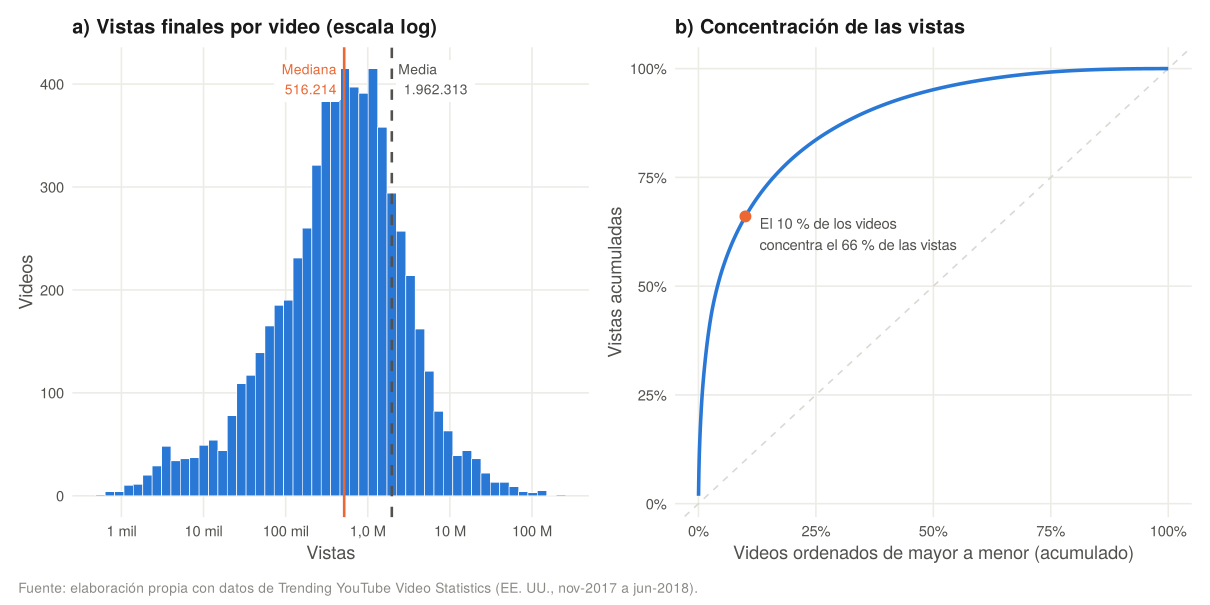

In [11]:
p_hist <- ggplot(videos, aes(vistas)) +
  geom_histogram(bins = 50, fill = AZUL, colour = "white", linewidth = 0.2) +
  geom_vline(xintercept = median(videos$vistas), colour = NARANJA, linewidth = 0.8) +
  geom_vline(xintercept = mean(videos$vistas), colour = TINTA, linewidth = 0.8, linetype = "dashed") +
  annotate("label", x = median(videos$vistas), y = Inf, vjust = 1.3, hjust = 1.05, label = paste("Mediana\n", num(median(videos$vistas))), size = 3.2, colour = NARANJA, label.size = 0) +
  annotate("label", x = mean(videos$vistas), y = Inf, vjust = 1.3, hjust = -0.05, label = paste("Media\n", num(mean(videos$vistas))), size = 3.2, colour = TINTA, label.size = 0) +
  scale_x_log10(labels = lab_corta, breaks = 10^(3:8)) +
  labs(title = "a) Vistas finales por video (escala log)", x = "Vistas", y = "Videos")
lorenz <- videos %>% arrange(desc(vistas)) %>% mutate(prop_videos = row_number() / n(), prop_vistas = cumsum(vistas) / sum(vistas))
top10 <- lorenz$prop_vistas[which.min(abs(lorenz$prop_videos - 0.10))]
p_lorenz <- ggplot(lorenz, aes(prop_videos, prop_vistas)) +
  geom_abline(colour = GRIS_CLARO, linetype = "dashed") + geom_line(colour = AZUL, linewidth = 1.1) +
  annotate("point", x = 0.10, y = top10, colour = NARANJA, size = 3) +
  annotate("text", x = 0.13, y = top10 - 0.04, hjust = 0, label = paste0("El 10 % de los videos\nconcentra el ", pct(top10, 0), " de las vistas"), size = 3.4, colour = TINTA) +
  scale_x_continuous(labels = label_percent()) + scale_y_continuous(labels = label_percent()) +
  labs(title = "b) Concentración de las vistas", x = "Videos ordenados de mayor a menor (acumulado)", y = "Vistas acumuladas")
p_hist + p_lorenz + plot_annotation(caption = "Fuente: elaboración propia con datos de Trending YouTube Video Statistics (EE. UU., nov-2017 a jun-2018).")
guardar(p_hist + p_lorenz, "01_distribucion_vistas", 11, 4.8)

**Lectura.** La distribución de las vistas es aproximadamente log-normal y está muy concentrada: **el 10 % de los videos reúne el 66 % de todas las vistas**. Para la estrategia esto significa que entrar a tendencia no garantiza un gran alcance; la mayoría de los videos en tendencia obtiene entre 100.000 y 2 millones de vistas.

### 3.2 Categorías: alcance, *likes* y *engagement*

Se comparan tres perspectivas, porque responden preguntas distintas. El **total de vistas** mide qué categoría domina la plataforma. La **mediana de vistas por video** mide qué tan probable es que un video típico de esa categoría tenga gran alcance. La **tasa de *likes* por vista** mide qué tan comprometida está la audiencia, independientemente del alcance.

In [12]:
por_cat <- videos %>% group_by(categoria) %>%
  summarise(videos = n(), canales = n_distinct(canal), vistas_tot = sum(vistas), likes_tot = sum(likes, na.rm = TRUE),
            med_vistas = median(vistas), med_likes = median(likes, na.rm = TRUE),
            tasa_likes = median(tasa_likes, na.rm = TRUE), tasa_coment = median(tasa_coment, na.rm = TRUE),
            aprobacion = median(aprobacion, na.rm = TRUE), dias_tend = mean(dias_tendencia)) %>%
  mutate(pct_videos = videos / sum(videos), pct_vistas = vistas_tot / sum(vistas_tot), pct_likes = likes_tot / sum(likes_tot)) %>%
  arrange(desc(vistas_tot))
por_cat %>% transmute(Categoría = categoria, Videos = num(videos), `% videos` = pct(pct_videos), `% vistas` = pct(pct_vistas), `% likes` = pct(pct_likes),
                      `Mediana vistas` = num(med_vistas), `Mediana likes` = num(med_likes),
                      `Likes / 100 vistas` = num(100 * tasa_likes, 2), `Coment. / 100 vistas` = num(100 * tasa_coment, 2),
                      `Aprobación` = pct(aprobacion), `Días en tendencia (media)` = num(dias_tend, 1))

Categoría,Videos,% videos,% vistas,% likes,Mediana vistas,Mediana likes,Likes / 100 vistas,Coment. / 100 vistas,Aprobación,Días en tendencia (media)
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Music,801,"12,6 %","38,8 %","42,7 %",1.096.158,40.554,"3,51","0,24","97,7 %","8,1"
Entertainment,1.619,"25,5 %","22,7 %","19,1 %",602.853,11.770,"1,99","0,22","96,0 %","6,1"
Film & Animation,319,"5,0 %","6,5 %","4,7 %",910.966,12.317,"2,06","0,24","95,7 %","7,3"
Comedy,544,"8,6 %","6,2 %","8,5 %",790.546,22.900,"3,14","0,24","96,8 %","6,3"
People & Blogs,495,"7,8 %","5,4 %","6,5 %",403.844,13.681,"3,17","0,30","97,5 %","6,5"
Sports,449,"7,1 %","5,1 %","3,6 %",405.781,4.330,"0,96","0,20","94,7 %","4,8"
Howto & Style,594,"9,4 %","4,5 %","5,9 %",426.985,15.926,"3,99","0,36","97,6 %","7,0"
Science & Technology,381,"6,0 %","3,4 %","2,9 %",429.830,11.443,"2,49","0,30","96,5 %","6,3"
Gaming,103,"1,6 %","1,9 %","2,0 %",1.316.002,36.922,"2,79","0,54","96,3 %","7,9"


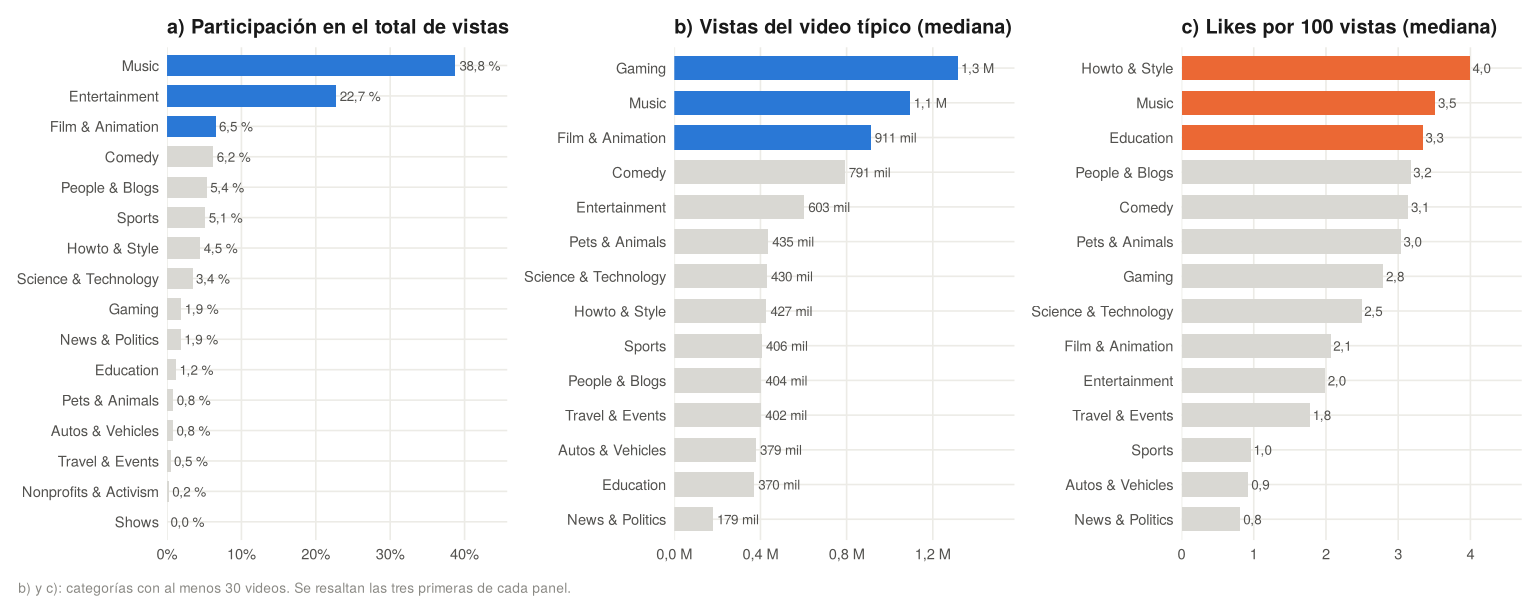

In [13]:
cats_min <- por_cat %>% filter(videos >= 30)            # categorías con al menos 30 videos
destacar <- function(df, var, n = 3) df %>% mutate(top = rank(-{{ var }}) <= n)
g1 <- por_cat %>% mutate(categoria = fct_reorder(categoria, pct_vistas)) %>% destacar(pct_vistas) %>%
  ggplot(aes(pct_vistas, categoria, fill = top)) + geom_col(width = 0.7) +
  geom_text(aes(label = pct(pct_vistas, 1)), hjust = -0.1, size = 3.1, colour = TINTA) +
  scale_fill_manual(values = c(`TRUE` = AZUL, `FALSE` = GRIS_CLARO), guide = "none") +
  scale_x_continuous(labels = label_percent(), expand = expansion(mult = c(0, .18))) +
  labs(title = "a) Participación en el total de vistas", x = NULL, y = NULL)
g2 <- cats_min %>% mutate(categoria = fct_reorder(categoria, med_vistas)) %>% destacar(med_vistas) %>%
  ggplot(aes(med_vistas, categoria, fill = top)) + geom_col(width = 0.7) +
  geom_text(aes(label = lab_corta(med_vistas)), hjust = -0.1, size = 3.1, colour = TINTA) +
  scale_fill_manual(values = c(`TRUE` = AZUL, `FALSE` = GRIS_CLARO), guide = "none") +
  scale_x_continuous(labels = lab_mill, expand = expansion(mult = c(0, .2))) +
  labs(title = "b) Vistas del video típico (mediana)", x = NULL, y = NULL)
g3 <- cats_min %>% mutate(categoria = fct_reorder(categoria, tasa_likes)) %>% destacar(tasa_likes) %>%
  ggplot(aes(100 * tasa_likes, categoria, fill = top)) + geom_col(width = 0.7) +
  geom_text(aes(label = num(100 * tasa_likes, 1)), hjust = -0.15, size = 3.1, colour = TINTA) +
  scale_fill_manual(values = c(`TRUE` = NARANJA, `FALSE` = GRIS_CLARO), guide = "none") +
  scale_x_continuous(expand = expansion(mult = c(0, .18))) +
  labs(title = "c) Likes por 100 vistas (mediana)", x = NULL, y = NULL)
fig_cat <- g1 + g2 + g3 + plot_annotation(caption = "b) y c): categorías con al menos 30 videos. Se resaltan las tres primeras de cada panel.")
options(repr.plot.width = 14, repr.plot.height = 5.5); fig_cat
guardar(fig_cat, "02_categorias_vistas_likes", 14, 5.5)

**Respuesta a P1.** Las tres perspectivas dan rankings distintos y la decisión depende del objetivo:

* **Volumen total:** *Music* domina, con solo el 12,6 % de los videos pero el **38,8 % de las vistas y el 42,7 % de los *likes***. *Entertainment* es la categoría con más videos en tendencia (25,5 %) y aporta el 22,7 % de las vistas.
* **Alcance del video típico:** *Gaming* (1,3 M de vistas de mediana, aunque con solo 103 videos), *Music* (1,1 M) y *Film & Animation* (0,9 M). *News & Politics* tiene el video típico de menor alcance (0,18 M).
* **Engagement:** *Howto & Style* (4,0 *likes* por cada 100 vistas), *Music* (3,5) y *Education* (3,3) tienen las audiencias más comprometidas. *News & Politics* (0,8), *Autos & Vehicles* (0,9) y *Sports* (1,0) atraen audiencias numerosas pero poco participativas. *News & Politics* además tiene la aprobación más baja (83,6 %, frente a más de 94 % en el resto), lo que indica contenido polarizante y riesgoso para una marca.

Para un canal corporativo cuyo objetivo es **llevar tráfico al sitio web**, el *engagement* importa más que el volumen. Por eso *Howto & Style* y *Education* (tutoriales y contenido explicativo) son las categorías más atractivas: combinan buena interacción con un formato natural para incluir enlaces y llamados a la acción.

**Gráfico de segmentos.** Une, para cada categoría, su participación en el total de videos con su participación en el total de vistas y de *likes*. El número indica cuántas veces su participación en vistas supera o no alcanza su participación en videos.

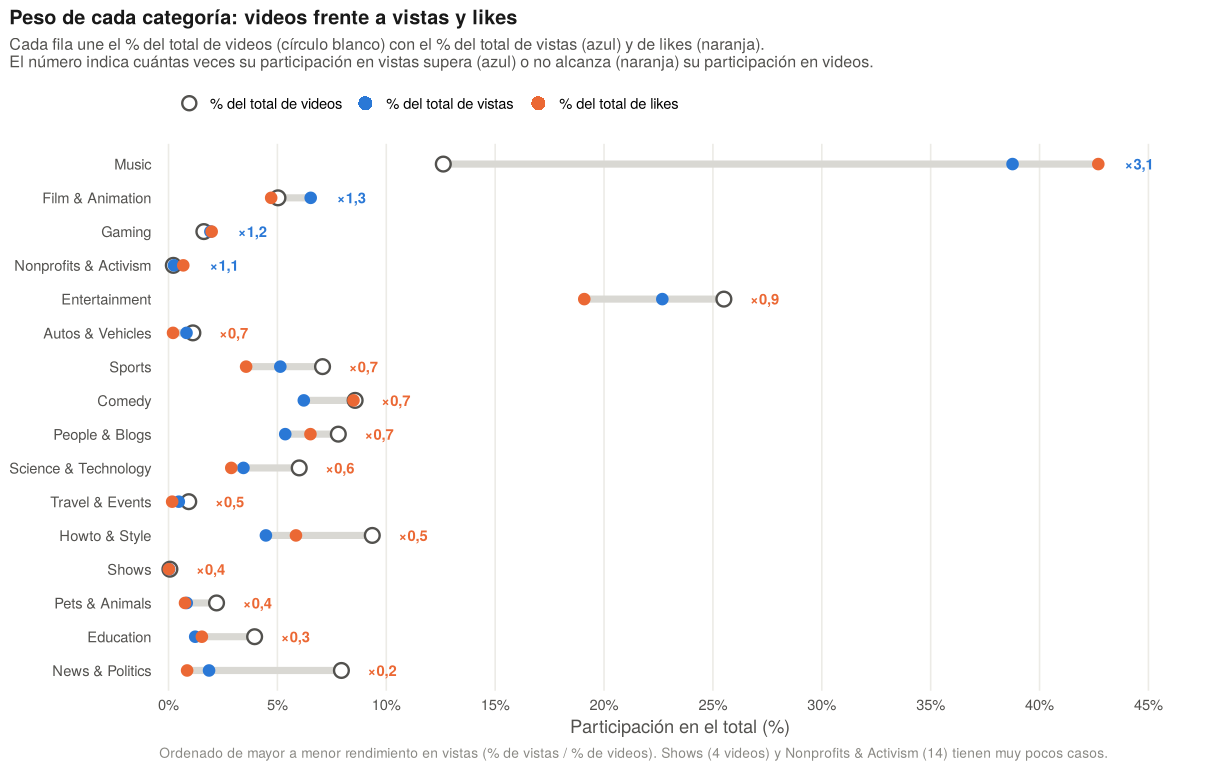

In [14]:
seg <- por_cat %>% mutate(ratio_v = pct_vistas / pct_videos, categoria = fct_reorder(categoria, ratio_v))
seg_largo <- seg %>% select(categoria, `% del total de videos` = pct_videos, `% del total de vistas` = pct_vistas, `% del total de likes` = pct_likes) %>%
  pivot_longer(-categoria, names_to = "medida", values_to = "valor") %>%
  mutate(medida = factor(medida, levels = c("% del total de videos", "% del total de vistas", "% del total de likes")))
seg_rango <- seg_largo %>% group_by(categoria) %>% summarise(min = min(valor), max = max(valor))
seg_etq <- seg %>% transmute(categoria, x = pmax(pct_videos, pct_vistas, pct_likes), lab = paste0("×", num(ratio_v, 1)), col = ifelse(ratio_v >= 1, "arriba", "abajo"))
p_seg <- ggplot() +
  geom_segment(data = seg_rango, aes(x = min, xend = max, y = categoria, yend = categoria), colour = GRIS_CLARO, linewidth = 2.2, lineend = "round") +
  geom_point(data = filter(seg_largo, medida == "% del total de videos"), aes(valor, categoria, colour = medida), shape = 21, size = 3.8, fill = "white", stroke = 1.1) +
  geom_point(data = filter(seg_largo, medida != "% del total de videos"), aes(valor, categoria, colour = medida), size = 3.2) +
  geom_text(data = seg_etq, aes(x = x + 0.012, y = categoria, label = lab, colour = col), hjust = 0, size = 3.4, fontface = "bold", show.legend = FALSE) +
  scale_colour_manual(values = c(`% del total de videos` = TINTA, `% del total de vistas` = AZUL, `% del total de likes` = NARANJA, arriba = AZUL, abajo = NARANJA),
                      breaks = c("% del total de videos", "% del total de vistas", "% del total de likes"), name = NULL) +
  guides(colour = guide_legend(override.aes = list(shape = c(21, 16, 16), fill = "white", size = 3.6))) +
  scale_x_continuous(labels = label_percent(accuracy = 1), breaks = seq(0, 0.45, 0.05), expand = expansion(mult = c(0.01, 0.08))) +
  labs(title = "Peso de cada categoría: videos frente a vistas y likes",
       subtitle = "Cada fila une el % del total de videos (círculo blanco) con el % del total de vistas (azul) y de likes (naranja).\nEl número indica cuántas veces su participación en vistas supera (azul) o no alcanza (naranja) su participación en videos.",
       x = "Participación en el total (%)", y = NULL,
       caption = "Ordenado de mayor a menor rendimiento en vistas (% de vistas / % de videos). Shows (4 videos) y Nonprofits & Activism (14) tienen muy pocos casos.") +
  theme(plot.title.position = "plot", legend.justification = "left", panel.grid.major.y = element_blank())
options(repr.plot.width = 11, repr.plot.height = 7); p_seg
guardar(p_seg, "02b_segmentos_categorias", 11, 7)

**Lectura.** *Music* rinde tres veces su tamaño: con el 12,6 % de los videos obtiene el 38,8 % de las vistas (×3,1) y el 42,7 % de los *likes*. *Film & Animation* (×1,3) y *Gaming* (×1,2) también rinden por encima en vistas. *Entertainment* tiene la mayor cantidad de videos (25,5 %), pero queda algo por debajo en vistas (×0,9) y en *likes*. *News & Politics* tiene la mayor diferencia negativa: 7,9 % de los videos, pero solo 1,9 % de las vistas (×0,2) y 0,9 % de los *likes*. En *Howto & Style*, *Comedy*, *People & Blogs* y *Education* el punto naranja queda a la derecha del azul: su participación en *likes* es mayor que en vistas, es decir, convierten mejor sus vistas en interacción.

**Gráfico bivariado.** El diagrama de cajas muestra la distribución completa de las vistas por categoría (no solo la mediana) y la prueba de Kruskal-Wallis evalúa si las diferencias son significativas. Se usa una prueba no paramétrica porque las vistas no son normales ni siquiera en escala logarítmica, y las varianzas difieren entre categorías.

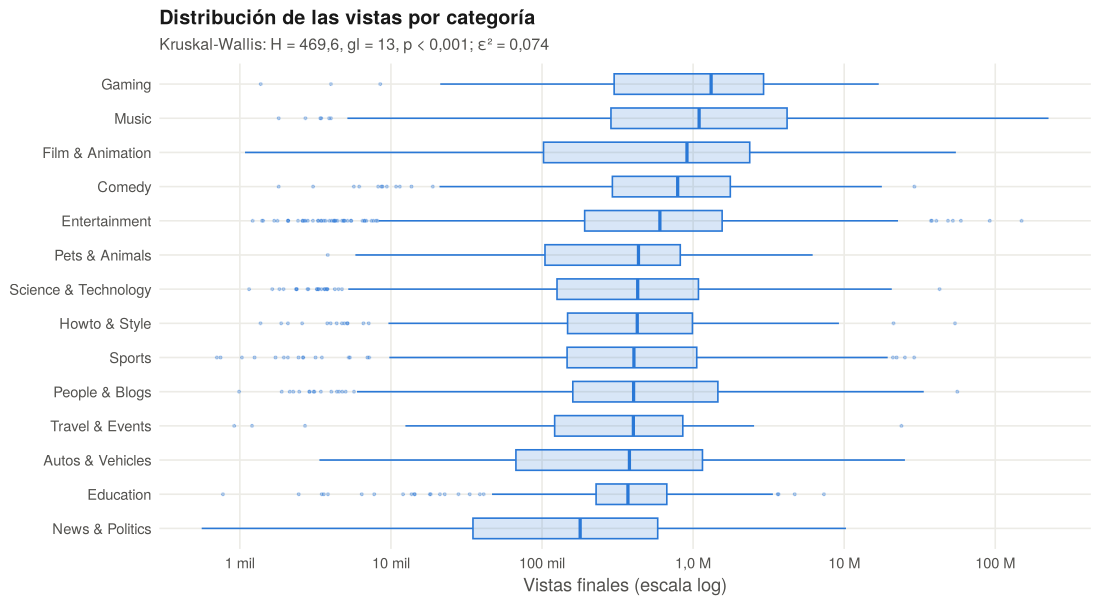

In [15]:
kw_cat <- kruskal.test(log10(vistas) ~ categoria, data = videos %>% filter(categoria %in% cats_min$categoria))
eps2 <- unname(kw_cat$statistic) / (nrow(videos %>% filter(categoria %in% cats_min$categoria)) - 1)   # tamaño del efecto épsilon²
p_box <- videos %>% filter(categoria %in% cats_min$categoria) %>%
  mutate(categoria = fct_reorder(categoria, vistas, median)) %>%
  ggplot(aes(vistas, categoria)) +
  geom_boxplot(fill = AZUL, alpha = 0.18, colour = AZUL, outlier.size = 0.6, outlier.alpha = 0.3, width = 0.6) +
  scale_x_log10(labels = lab_corta, breaks = 10^(3:8)) +
  labs(title = "Distribución de las vistas por categoría",
       subtitle = paste0("Kruskal-Wallis: H = ", num(kw_cat$statistic, 1), ", gl = ", kw_cat$parameter, ", p < 0,001; ε² = ", num(eps2, 3)),
       x = "Vistas finales (escala log)", y = NULL)
options(repr.plot.width = 10, repr.plot.height = 5.5); p_box
guardar(p_box, "03_boxplot_categorias", 10, 5.5)

**Lectura.** Las diferencias entre categorías son estadísticamente significativas (H = 469,6; p < 0,001), pero el tamaño del efecto es moderado: **ε² = 0,074**, es decir, la categoría explica alrededor del 7 % de la variabilidad de las vistas. Dentro de cada categoría hay videos de mil vistas y de cien millones, de modo que la categoría por sí sola no determina el éxito de un video.

**Gráfico multivariado.** La relación entre vistas y *likes* (escala log-log) muestra si las categorías con más alcance también obtienen proporcionalmente más *likes*. La pendiente de la recta es una **elasticidad**: el cambio porcentual en *likes* por cada 1 % más de vistas.

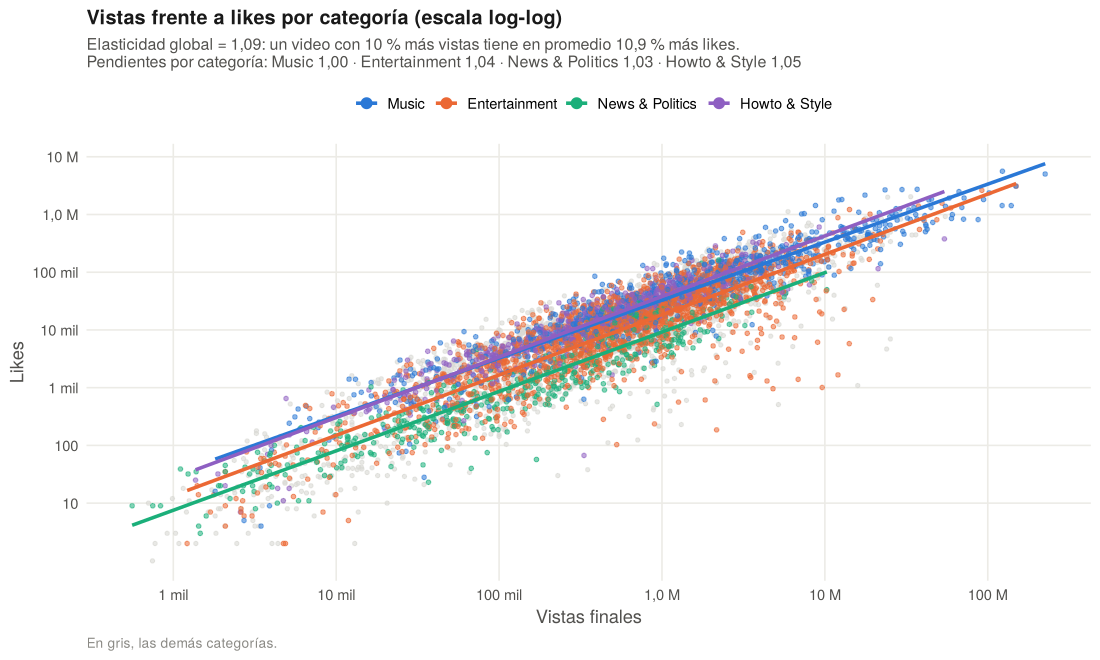

In [16]:
cats_foco <- c("Music", "Entertainment", "News & Politics", "Howto & Style")
d_sc <- videos %>% filter(!is.na(likes), likes > 0) %>%
  mutate(grupo = if_else(categoria %in% cats_foco, categoria, "Otras"), grupo = factor(grupo, levels = c(cats_foco, "Otras")))
elas <- coef(lm(log10(likes) ~ log10(vistas), data = d_sc))[2]
elas_cat <- d_sc %>% filter(grupo != "Otras") %>% group_by(grupo) %>% summarise(b = coef(lm(log10(likes) ~ log10(vistas)))[2])
p_sc <- ggplot(d_sc, aes(vistas, likes)) +
  geom_point(data = filter(d_sc, grupo == "Otras"), colour = GRIS_CLARO, size = 1, alpha = 0.6) +
  geom_point(data = filter(d_sc, grupo != "Otras"), aes(colour = grupo), size = 1.1, alpha = 0.55) +
  geom_smooth(data = filter(d_sc, grupo != "Otras"), aes(colour = grupo), method = "lm", se = FALSE, linewidth = 1.1, formula = y ~ x) +
  scale_x_log10(labels = lab_corta, breaks = 10^(3:8)) + scale_y_log10(labels = lab_corta, breaks = 10^(1:7)) +
  scale_colour_manual(values = setNames(PALETA, cats_foco), name = NULL) +
  labs(title = "Vistas frente a likes por categoría (escala log-log)",
       subtitle = paste0("Elasticidad global = ", num(elas, 2), ": un video con 10 % más vistas tiene en promedio ", num(100 * (1.1^elas - 1), 1), " % más likes.\n",
                         "Pendientes por categoría: ", paste0(elas_cat$grupo, " ", num(elas_cat$b, 2), collapse = " · ")),
       x = "Vistas finales", y = "Likes", caption = "En gris, las demás categorías.") +
  guides(colour = guide_legend(override.aes = list(size = 3, alpha = 1)))
options(repr.plot.width = 10, repr.plot.height = 6); p_sc
guardar(p_sc, "04_vistas_vs_likes", 10, 6)

**Lectura.** Vistas y *likes* crecen casi en proporción 1 a 1 (elasticidad de 1,09), y las pendientes por categoría son prácticamente iguales (entre 1,00 y 1,05). Lo que cambia entre categorías es el **nivel** (la altura de la recta): a igual número de vistas, un video de *Howto & Style* o *Music* recibe aproximadamente el triple de *likes* que uno de *News & Politics*. Por eso las tasas por vista son la forma correcta de comparar el *engagement*.

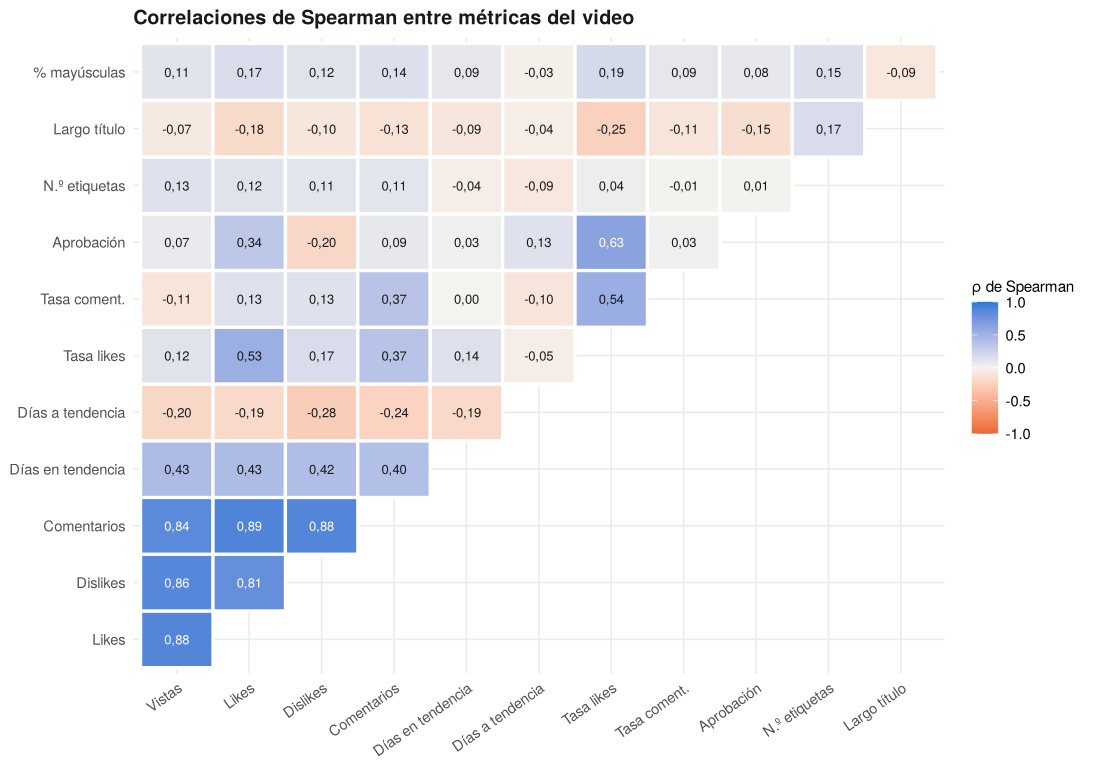

In [17]:
# Matriz de correlaciones de Spearman
vars_cor <- videos %>% transmute(Vistas = vistas, Likes = likes, Dislikes = dislikes, Comentarios = comentarios,
                                 `Días en tendencia` = dias_tendencia, `Días a tendencia` = dias_a_tendencia,
                                 `Tasa likes` = tasa_likes, `Tasa coment.` = tasa_coment, Aprobación = aprobacion,
                                 `N.º etiquetas` = n_etiquetas, `Largo título` = largo_titulo, `% mayúsculas` = prop_mayus)
cm <- cor(vars_cor, method = "spearman", use = "pairwise.complete.obs")
cm_df <- as.data.frame(as.table(cm)) %>% filter(as.integer(Var1) > as.integer(Var2))
p_cor <- ggplot(cm_df, aes(Var2, Var1, fill = Freq)) + geom_tile(colour = "white", linewidth = 1) +
  geom_text(aes(label = num(Freq, 2)), size = 3, colour = ifelse(abs(cm_df$Freq) > 0.6, "white", "#191919")) +
  scale_fill_gradient2(low = NARANJA, mid = "#f4f3ef", high = AZUL, limits = c(-1, 1), name = "ρ de Spearman") +
  labs(title = "Correlaciones de Spearman entre métricas del video", x = NULL, y = NULL) +
  theme(axis.text.x = element_text(angle = 35, hjust = 1), panel.grid = element_blank(), legend.position = "right")
options(repr.plot.width = 10, repr.plot.height = 7); p_cor
guardar(p_cor, "05_correlaciones", 10, 7)

**Lectura.** Los conteos (vistas, *likes*, *dislikes* y comentarios) están fuertemente correlacionados entre sí (ρ de 0,81 a 0,89): miden casi lo mismo, el **volumen de audiencia**. Las tasas (*likes* por vista, comentarios por vista y aprobación) casi no se correlacionan con el volumen (|ρ| ≤ 0,12): miden otra dimensión, la **intensidad de la interacción**. Esta redundancia justifica reducir la dimensionalidad con componentes principales. Los días en tendencia se asocian moderadamente con las vistas (ρ = 0,43).

### 3.3 Canales: ¿quién domina la lista de tendencias?

Canales: 2.198 | Canales con un solo video en tendencia: 63,3 % | Gini de las vistas entre canales: 0,84 | El 1 % de canales con más vistas concentra: 25,5 % 


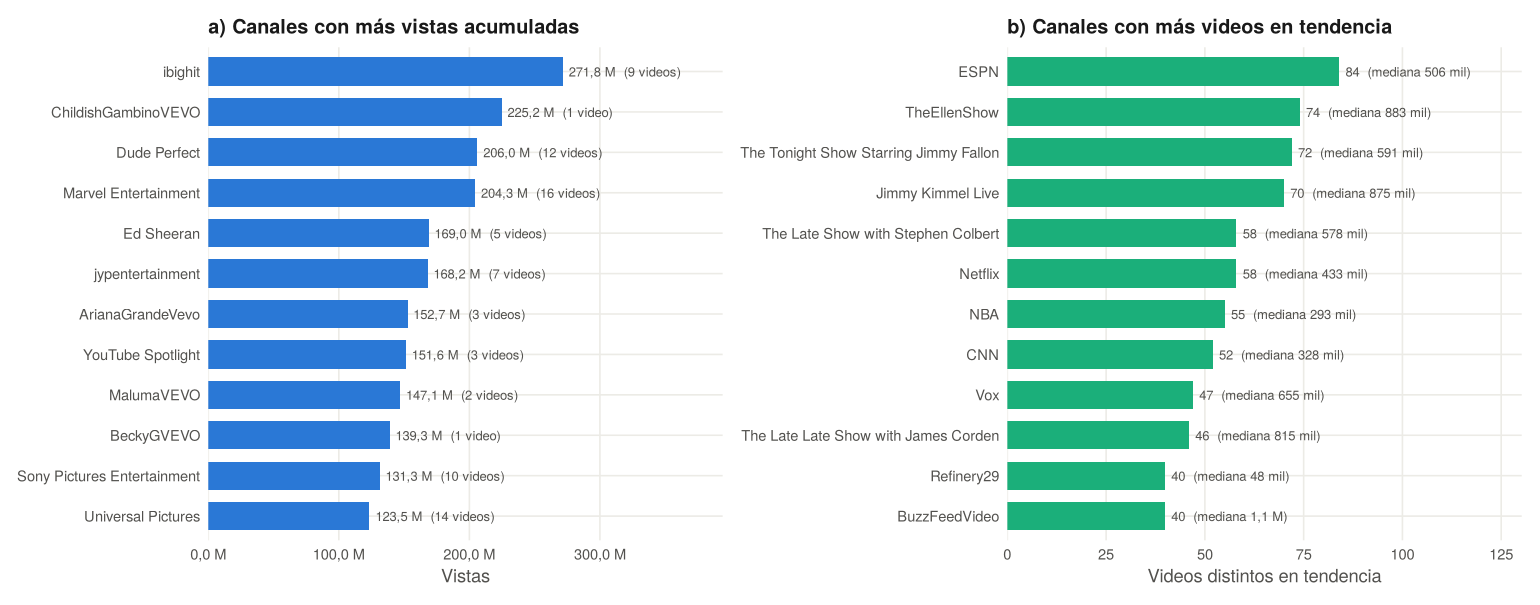

In [18]:
por_canal <- videos %>% group_by(canal) %>%
  summarise(categoria = names(which.max(table(categoria))), videos = n(), vistas_tot = sum(vistas), med_vistas = median(vistas),
            tasa_likes = median(tasa_likes, na.rm = TRUE), dias_tend = mean(dias_tendencia)) %>% arrange(desc(vistas_tot))
gini <- function(x) { x <- sort(x); n <- length(x); sum((2 * seq_len(n) - n - 1) * x) / (n * sum(x)) }
cat("Canales:", num(nrow(por_canal)), "| Canales con un solo video en tendencia:", pct(mean(por_canal$videos == 1)),
    "| Gini de las vistas entre canales:", num(gini(por_canal$vistas_tot), 2),
    "| El 1 % de canales con más vistas concentra:", pct(sum(head(por_canal$vistas_tot, ceiling(.01 * nrow(por_canal)))) / sum(por_canal$vistas_tot)), "\n")

top_vistas <- por_canal %>% slice_max(vistas_tot, n = 12) %>% mutate(canal = fct_reorder(canal, vistas_tot))
top_frec <- por_canal %>% slice_max(videos, n = 12, with_ties = FALSE) %>% mutate(canal = fct_reorder(canal, videos))
c1 <- ggplot(top_vistas, aes(vistas_tot, canal)) + geom_col(fill = AZUL, width = 0.7) +
  geom_text(aes(label = paste0(lab_mill(vistas_tot), "  (", videos, if_else(videos == 1, " video)", " videos)"))), hjust = -0.05, size = 3, colour = TINTA) +
  scale_x_continuous(labels = lab_mill, expand = expansion(mult = c(0, .45))) +
  labs(title = "a) Canales con más vistas acumuladas", x = "Vistas", y = NULL)
c2 <- ggplot(top_frec, aes(videos, canal)) + geom_col(fill = AQUA, width = 0.7) +
  geom_text(aes(label = paste0(videos, "  (mediana ", lab_corta(med_vistas), ")")), hjust = -0.05, size = 3, colour = TINTA) +
  scale_x_continuous(expand = expansion(mult = c(0, .55))) +
  labs(title = "b) Canales con más videos en tendencia", x = "Videos distintos en tendencia", y = NULL)
options(repr.plot.width = 14, repr.plot.height = 5.5); c1 + c2
guardar(c1 + c2, "06_top_canales", 14, 5.5)

**Lectura.** La lista de tendencias es muy desigual entre canales (coeficiente de Gini de 0,84). El 63 % de los 2.198 canales llegó a tendencia con un solo video, mientras que el 1 % de los canales concentra el 25,5 % de las vistas. Los canales con más vistas son sellos y artistas musicales (ibighit, ChildishGambinoVEVO, Ed Sheeran) y estudios de cine (Marvel, Sony, Universal). En cambio, los que aparecen con más frecuencia son medios con producción diaria (ESPN, programas nocturnos de TV, Netflix, CNN). Hay dos formas de "ganar" en YouTube: el **impacto** (pocos videos con muchas vistas) y la **constancia** (muchos videos en tendencia con un alcance medio). Un canal corporativo nuevo está más cerca del segundo modelo: su ventaja es la constancia.

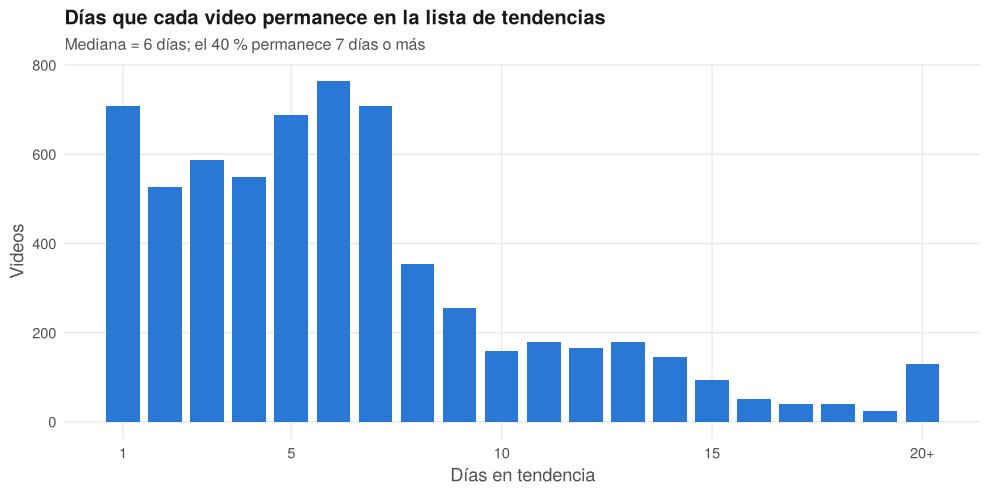

In [19]:
# Distribución de los días en tendencia
p_dias <- videos %>% mutate(dias = pmin(dias_tendencia, 20)) %>% count(dias) %>%
  ggplot(aes(dias, n)) + geom_col(fill = AZUL, width = 0.8) +
  scale_x_continuous(breaks = c(1, 5, 10, 15, 20), labels = c("1", "5", "10", "15", "20+")) +
  labs(title = "Días que cada video permanece en la lista de tendencias",
       subtitle = paste0("Mediana = ", median(videos$dias_tendencia), " días; el ", pct(mean(videos$dias_tendencia >= 7), 0), " permanece 7 días o más"),
       x = "Días en tendencia", y = "Videos")
options(repr.plot.width = 9, repr.plot.height = 4.5); p_dias
guardar(p_dias, "06b_dias_en_tendencia", 9, 4.5)

## 4. P2 — ¿Es posible encontrar agrupaciones de videos?

Se responde con cuatro técnicas complementarias:

1. **Análisis de componentes principales (ACP)** para reducir la dimensionalidad de las métricas de desempeño, que están muy correlacionadas.
2. **K-means (no supervisado)**: agrupa los videos por su comportamiento, sin usar la categoría. El número de grupos se elige con cinco criterios: codo, *silhouette*, Calinski-Harabasz, Davies-Bouldin y estabilidad *bootstrap*.
3. **Validación externa con la categoría (enfoque supervisado)**: se comprueba si los grupos coinciden con las categorías de YouTube y si un clasificador puede reconocer la categoría a partir del comportamiento.
4. **Análisis de correspondencias múltiples (ACM)** sobre variables categóricas y nominales, para ver qué categorías se asocian con qué perfiles de desempeño, tono y horario.

Antes de esto se calcula el **sentimiento del título** (minería de texto), que se usa en el ACM y en los modelos posteriores.

### 4.1 Análisis de sentimiento de los títulos (minería de texto)

Se usa el léxico *Bing* (Hu y Liu, 2004), que clasifica 6.786 palabras en inglés como positivas o negativas. El puntaje de cada título es el número de palabras positivas menos el de negativas. Es un método sencillo y transparente, adecuado para títulos cortos. Su limitación es que no capta sarcasmo ni negaciones.

In [20]:
bing <- get_sentiments("bing")
tokens_tit <- videos %>% transmute(video_id, texto = normalizar(titulo)) %>% unnest_tokens(palabra, texto)
sent <- tokens_tit %>% inner_join(bing, by = c("palabra" = "word"), relationship = "many-to-many") %>%
  count(video_id, sentiment) %>% pivot_wider(names_from = sentiment, values_from = n, values_fill = 0)
videos <- videos %>% left_join(sent, by = "video_id") %>%
  mutate(across(c(positive, negative), ~ coalesce(.x, 0L)), sentimiento = positive - negative,
         tono = factor(case_when(sentimiento > 0 ~ "Positivo", sentimiento < 0 ~ "Negativo", TRUE ~ "Neutro"),
                       levels = c("Negativo", "Neutro", "Positivo")))
cat("Títulos con al menos una palabra del léxico:", pct(mean(videos$positive + videos$negative > 0)), "\n")
videos %>% count(tono) %>% mutate(pct = pct(n / sum(n)))

Títulos con al menos una palabra del léxico: 42,0 % 


tono,n,pct
<fct>,<int>,<chr>
Negativo,1131,"17,8 %"
Neutro,3934,"62,0 %"
Positivo,1283,"20,2 %"


tono,n,Mediana vistas,Likes / 100 vistas,Coment. / 100 vistas,Aprobación
<fct>,<int>,<chr>,<chr>,<chr>,<chr>
Negativo,1131,619.443,"2,28","0,29","96,0 %"
Neutro,3934,499.200,"2,48","0,28","96,6 %"
Positivo,1283,484.054,"2,36","0,25","96,5 %"


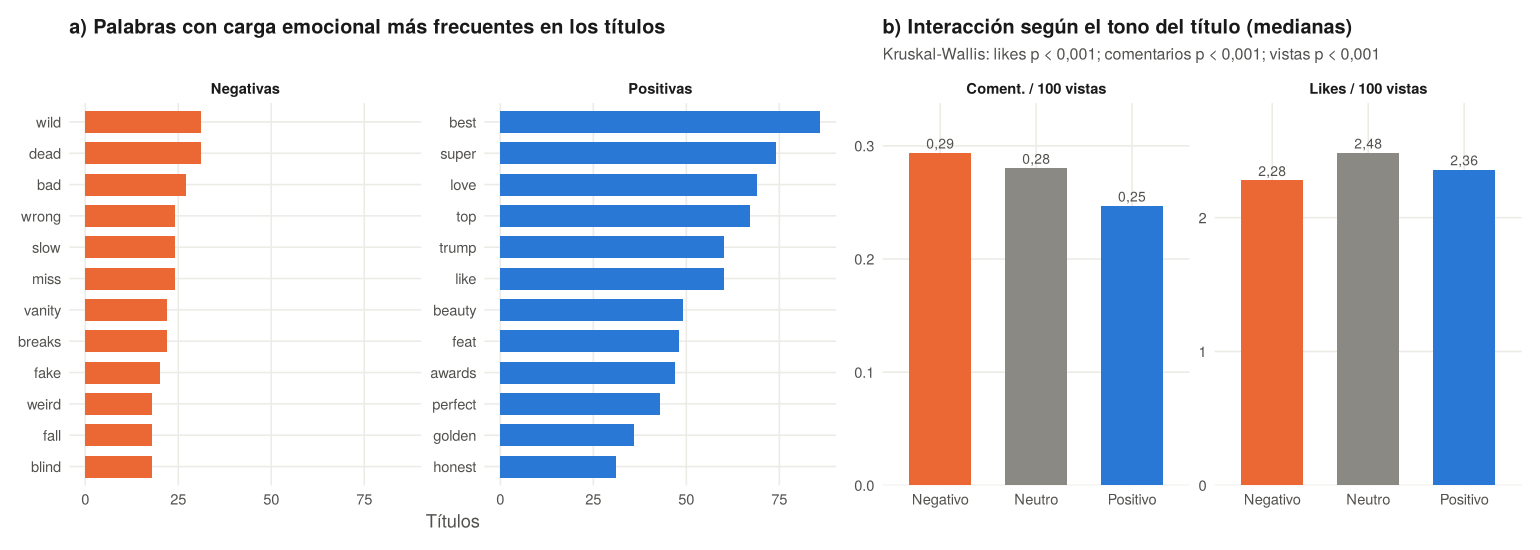

In [21]:
pal_sent <- tokens_tit %>% inner_join(bing, by = c("palabra" = "word"), relationship = "many-to-many") %>%
  count(palabra, sentiment, sort = TRUE) %>% group_by(sentiment) %>% slice_max(n, n = 12, with_ties = FALSE) %>% ungroup() %>%
  mutate(sentiment = recode(sentiment, positive = "Positivas", negative = "Negativas"), palabra = reorder_within(palabra, n, sentiment))
s1 <- ggplot(pal_sent, aes(n, palabra, fill = sentiment)) + geom_col(width = 0.7, show.legend = FALSE) +
  facet_wrap(~ sentiment, scales = "free_y") + scale_y_reordered() +
  scale_fill_manual(values = c(Positivas = AZUL, Negativas = NARANJA)) +
  labs(title = "a) Palabras con carga emocional más frecuentes en los títulos", x = "Títulos", y = NULL)
kw_tono_l <- kruskal.test(tasa_likes ~ tono, data = videos); kw_tono_c <- kruskal.test(tasa_coment ~ tono, data = videos); kw_tono_v <- kruskal.test(vistas ~ tono, data = videos)
tono_res <- videos %>% group_by(tono) %>% summarise(n = n(), `Mediana vistas` = median(vistas), `Likes / 100 vistas` = 100 * median(tasa_likes, na.rm = TRUE),
                                                    `Coment. / 100 vistas` = 100 * median(tasa_coment, na.rm = TRUE), `Aprobación` = median(aprobacion, na.rm = TRUE))
s2 <- tono_res %>% select(tono, `Likes / 100 vistas`, `Coment. / 100 vistas`) %>% pivot_longer(-tono) %>%
  ggplot(aes(tono, value, fill = tono)) + geom_col(width = 0.65, show.legend = FALSE) +
  geom_text(aes(label = num(value, 2)), vjust = -0.4, size = 3.2, colour = TINTA) +
  facet_wrap(~ name, scales = "free_y") + scale_fill_manual(values = c(Negativo = NARANJA, Neutro = GRIS, Positivo = AZUL)) +
  scale_y_continuous(expand = expansion(mult = c(0, .15))) +
  labs(title = "b) Interacción según el tono del título (medianas)",
       subtitle = paste0("Kruskal-Wallis: likes ", p_txt(kw_tono_l$p.value), "; comentarios ", p_txt(kw_tono_c$p.value), "; vistas ", p_txt(kw_tono_v$p.value)),
       x = NULL, y = NULL)
options(repr.plot.width = 14, repr.plot.height = 5); s1 + s2 + plot_layout(widths = c(1.2, 1))
guardar(s1 + s2 + plot_layout(widths = c(1.2, 1)), "07_sentimiento", 14, 5)
tono_res %>% mutate(`Mediana vistas` = num(`Mediana vistas`), across(c(`Likes / 100 vistas`, `Coment. / 100 vistas`), ~ num(.x, 2)), `Aprobación` = pct(`Aprobación`))

**Lectura.** El 42 % de los títulos contiene al menos una palabra con carga emocional; el 20 % tiene tono positivo y el 18 % negativo. Las palabras negativas más frecuentes son de impacto ("dead", "bad", "wrong", "fake") y las positivas, de recomendación ("best", "love", "top", "perfect"). El gráfico también muestra una limitación de los léxicos: "trump", "super" (*Super Bowl*) y "golden" (*Golden Globes*) se cuentan como positivas aunque en estos títulos son nombres propios. Las diferencias de interacción entre tonos son pequeñas (los títulos negativos tienen algo más de vistas y los positivos algo menos de comentarios), y el ACM confirma que el tono casi no se asocia con el desempeño (η² < 0,04). **Conclusión práctica:** el tono del título no es una palanca relevante; importan más el tema, el formato y la audiencia del canal.

### 4.2 Componentes principales de las métricas de desempeño

Variables (una fila por video, sin los videos con *likes* o comentarios deshabilitados): vistas, *likes*, *dislikes* y comentarios en escala logarítmica, tasas de interacción, aprobación, días en tendencia, días hasta la tendencia y crecimiento de las vistas durante la tendencia. Las de conteo se transforman con log₁₀ por su asimetría extrema y todas se estandarizan (puntaje z) para que ninguna domine por su escala.

In [22]:
base_cl <- videos %>% filter(!is.na(likes), !is.na(comentarios), likes > 0, comentarios > 0, dislikes > 0)
X_cl <- base_cl %>% transmute(`log vistas` = log10(vistas), `log likes` = log10(likes), `log dislikes` = log10(dislikes), `log comentarios` = log10(comentarios),
                              `Tasa likes (log)` = log10(tasa_likes), `Tasa coment. (log)` = log10(tasa_coment), `Aprobación (logit)` = qlogis(pmin(aprobacion, 0.999)),
                              `Días en tendencia` = dias_tendencia, `Días a tendencia (log)` = log10(dias_a_tendencia + 1), `Crecimiento vistas (log)` = log10(crec_vistas))
Z_cl <- scale(X_cl)
acp <- prcomp(Z_cl)
var_exp <- acp$sdev^2 / sum(acp$sdev^2)
cat("Videos en el análisis:", num(nrow(base_cl)), "| Varianza explicada por CP1-CP3:", paste(pct(var_exp[1:3]), collapse = ", "),
    "| acumulada:", pct(sum(var_exp[1:3])), "| Autovalores > 1:", sum(acp$sdev^2 > 1), "\n")
cargas <- as.data.frame(acp$rotation[, 1:3]) %>% rownames_to_column("Variable")
cargas %>% mutate(across(where(is.numeric), ~ num(.x, 2)))

Videos en el análisis: 6.150 | Varianza explicada por CP1-CP3: 43,3 %, 19,7 %, 12,3 % | acumulada: 75,3 % | Autovalores > 1: 4 


Variable,PC1,PC2,PC3
<chr>,<chr>,<chr>,<chr>
log vistas,"-0,43","0,20","0,15"
log likes,"-0,46","-0,09","0,15"
log dislikes,"-0,43","0,18","-0,22"
log comentarios,"-0,45","-0,05","-0,16"
Tasa likes (log),"-0,23","-0,58","0,06"
Tasa coment. (log),"-0,11","-0,45","-0,57"
Aprobación (logit),"-0,11","-0,45","0,62"
Días en tendencia,"-0,26","0,20","0,22"
Días a tendencia (log),"0,19","-0,04","0,33"


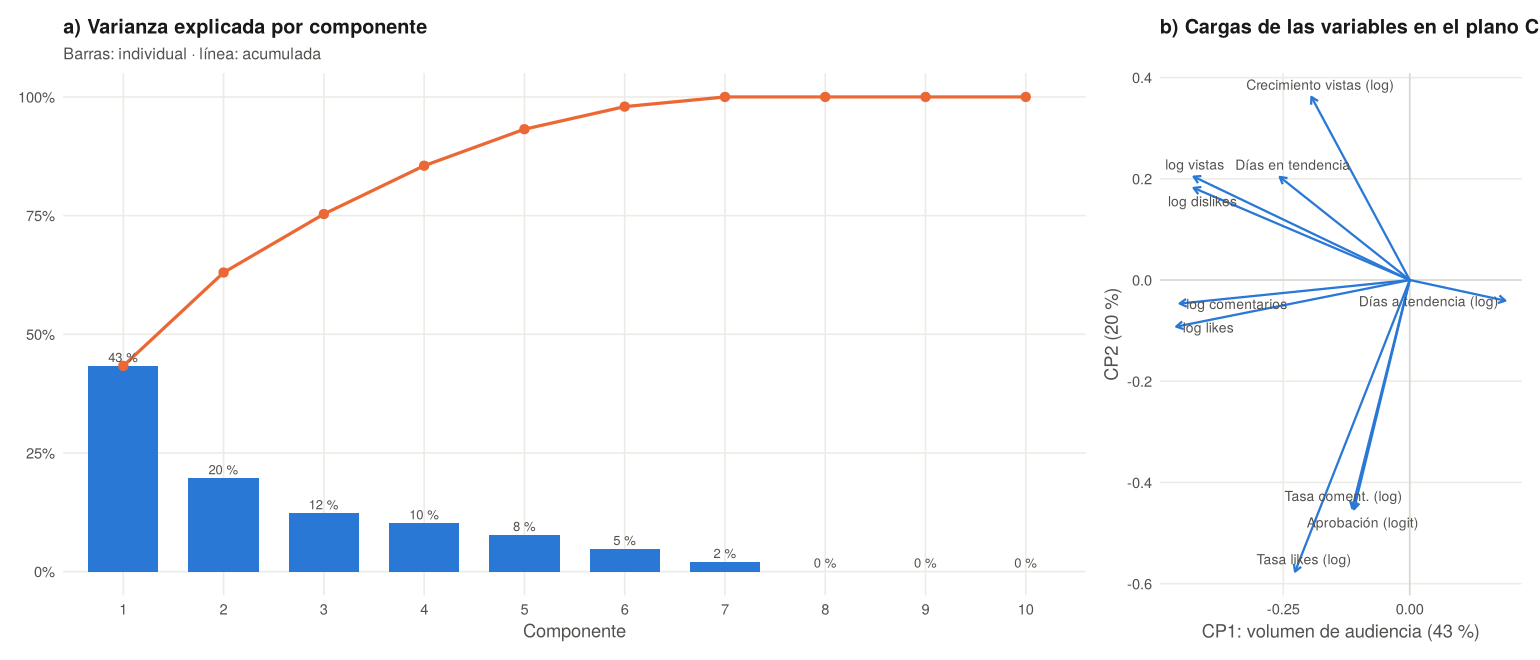

In [23]:
a1 <- tibble(CP = factor(seq_along(var_exp)), var = var_exp, acum = cumsum(var_exp)) %>%
  ggplot(aes(CP, var)) + geom_col(fill = AZUL, width = 0.7) + geom_line(aes(y = acum, group = 1), colour = NARANJA, linewidth = 1) +
  geom_point(aes(y = acum), colour = NARANJA, size = 2.5) + geom_text(aes(label = pct(var, 0)), vjust = -0.4, size = 3, colour = TINTA) +
  scale_y_continuous(labels = label_percent()) + labs(title = "a) Varianza explicada por componente", subtitle = "Barras: individual · línea: acumulada", x = "Componente", y = NULL)
a2 <- cargas %>% ggplot(aes(PC1, PC2)) + geom_hline(yintercept = 0, colour = GRIS_CLARO) + geom_vline(xintercept = 0, colour = GRIS_CLARO) +
  geom_segment(aes(x = 0, y = 0, xend = PC1, yend = PC2), arrow = arrow(length = unit(0.18, "cm")), colour = AZUL, linewidth = 0.7) +
  geom_text_repel(aes(label = Variable), size = 3.2, colour = TINTA, max.overlaps = 20) +
  labs(title = "b) Cargas de las variables en el plano CP1-CP2",
       x = paste0("CP1: volumen de audiencia (", pct(var_exp[1], 0), ")"), y = paste0("CP2 (", pct(var_exp[2], 0), ")")) + coord_equal()
options(repr.plot.width = 14, repr.plot.height = 6); a1 + a2
guardar(a1 + a2, "08_acp", 14, 6)

**Lectura.** Cuatro componentes tienen autovalor mayor que 1 y los tres primeros explican el **75 % de la varianza**. El **CP1 (43 %)** es el **volumen de audiencia**: cargan de forma similar las vistas, los *likes*, los *dislikes* y los comentarios. El **CP2 (20 %)** es la **intensidad de interacción**: lo forman la tasa de *likes*, la de comentarios y la aprobación, en sentido opuesto al crecimiento de las vistas. Son dos dimensiones casi independientes; un video puede tener mucha audiencia y poca interacción, o al revés. Esta distinción es la base de la métrica de *sponsors*.

### 4.3 K-means: selección del número de grupos

In [24]:
davies_bouldin <- function(X, cl) {
  k <- sort(unique(cl)); cent <- t(sapply(k, function(j) colMeans(X[cl == j, , drop = FALSE])))
  s <- sapply(seq_along(k), function(j) mean(sqrt(rowSums(sweep(X[cl == k[j], , drop = FALSE], 2, cent[j, ])^2))))
  d <- as.matrix(dist(cent)); r <- sapply(seq_along(k), function(i) max((s[i] + s[-i]) / d[i, -i])); mean(r)
}
calinski <- function(X, km) { n <- nrow(X); k <- length(km$size); (km$betweenss / (k - 1)) / (km$tot.withinss / (n - k)) }
set.seed(SEMILLA)
D_cl <- dist(Z_cl)
criterios <- map_dfr(2:8, function(k) {
  km <- suppressWarnings(kmeans(Z_cl, centers = k, nstart = 25, iter.max = 100))
  ari_boot <- map_dbl(1:15, function(b) {
    idx <- sample(nrow(Z_cl), replace = TRUE); kb <- suppressWarnings(kmeans(Z_cl[idx, ], centers = k, nstart = 10, iter.max = 100))
    pred <- apply(Z_cl, 1, function(r) which.min(colSums((t(kb$centers) - r)^2))); adjustedRandIndex(km$cluster, pred) })
  tibble(k = k, Inercia = km$tot.withinss, Silhouette = mean(silhouette(km$cluster, D_cl)[, 3]),
         `Calinski-Harabasz` = calinski(Z_cl, km), `Davies-Bouldin` = davies_bouldin(Z_cl, km$cluster), `Estabilidad (ARI)` = mean(ari_boot))
})
criterios %>% mutate(across(-k, ~ num(.x, ifelse(.x > 100, 0, 3))))

k,Inercia,Silhouette,Calinski-Harabasz,Davies-Bouldin,Estabilidad (ARI)
<int>,<chr>,<chr>,<chr>,<chr>,<chr>
2,45.655,"0,241",2.132,"1,528","0,947"
3,39.692,"0,179",1.688,"1,649","0,882"
4,35.639,"0,178",1.486,"1,563","0,873"
5,32.145,"0,186",1.402,"1,376","0,808"
6,29.594,"0,162",1.324,"1,425","0,823"
7,27.664,"0,168",1.252,"1,429","0,835"
8,26.164,"0,167",1.185,"1,397","0,696"


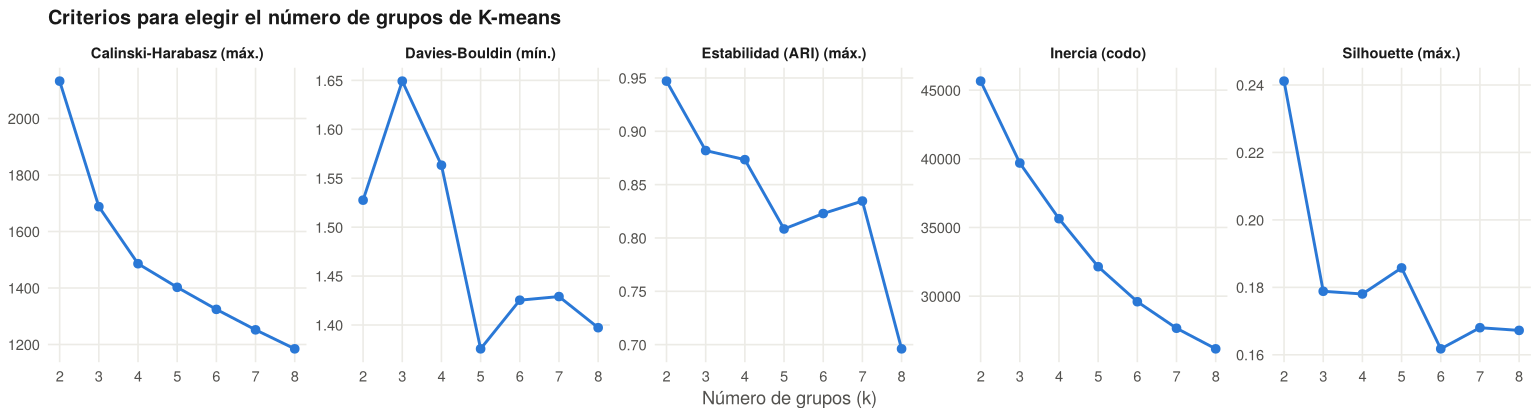

In [25]:
crit_long <- criterios %>% pivot_longer(-k) %>%
  mutate(name = factor(name, levels = c("Inercia", "Silhouette", "Calinski-Harabasz", "Davies-Bouldin", "Estabilidad (ARI)")),
         mejor = case_when(name == "Davies-Bouldin" ~ "mín.", name == "Inercia" ~ "codo", TRUE ~ "máx."))
options(repr.plot.width = 14, repr.plot.height = 3.8)
p_crit <- ggplot(crit_long, aes(k, value)) + geom_line(colour = AZUL, linewidth = 0.9) + geom_point(colour = AZUL, size = 2.3) +
  facet_wrap(~ paste0(name, " (", mejor, ")"), scales = "free_y", nrow = 1) + scale_x_continuous(breaks = 2:8) +
  labs(title = "Criterios para elegir el número de grupos de K-means", x = "Número de grupos (k)", y = NULL)
p_crit
guardar(p_crit, "09_criterios_k", 14, 3.8)

**Elección de k.** Los criterios no coinciden en un único valor. El *silhouette*, el Calinski-Harabasz y la estabilidad favorecen **k = 2**, pero esa partición solo separa los videos grandes de los pequeños (repite el CP1). El Davies-Bouldin favorece k = 5. Ningún k alcanza un *silhouette* de 0,25, lo que indica que **los videos forman un continuo más que grupos naturalmente separados**. Se elige **k = 4** por tres razones: (1) mantiene una estabilidad *bootstrap* alta (ARI = 0,87, mayor que 0,85); (2) es el menor k que separa la dimensión de interacción (CP2) además de la de volumen; y (3) produce segmentos accionables. Es una segmentación **útil para decidir**, no una tipología natural de los datos, y así debe comunicarse.

In [26]:
K_OPT <- 4      # número de grupos seleccionado
set.seed(SEMILLA)
km <- kmeans(Z_cl, centers = K_OPT, nstart = 50, iter.max = 200)
sil <- silhouette(km$cluster, D_cl)
cat("k =", K_OPT, "| Silhouette =", num(mean(sil[, 3]), 3), "| % videos con silhouette negativo =", pct(mean(sil[, 3] < 0)),
    "| Varianza explicada (BSS/TSS) =", pct(km$betweenss / km$totss), "\n")

# Nombre de cada grupo según su perfil
med_g <- base_cl %>% mutate(g = km$cluster) %>% group_by(g) %>% summarise(v = median(vistas), l = median(tasa_likes))
g_viral <- med_g$g[which.max(med_g$v)]; g_bajo <- med_g$g[which.min(med_g$v)]
resto <- med_g %>% filter(!g %in% c(g_viral, g_bajo))
nombres_g <- setNames(rep(NA_character_, K_OPT), med_g$g)
nombres_g[as.character(g_viral)] <- "Virales masivos"; nombres_g[as.character(g_bajo)] <- "Bajo alcance"
nombres_g[as.character(resto$g[which.max(resto$l)])] <- "Comunidad comprometida"
nombres_g[as.character(resto$g[which.min(resto$l)])] <- "Alcance sin conexión"
NIVELES_G <- c("Virales masivos", "Comunidad comprometida", "Alcance sin conexión", "Bajo alcance")
COL_G <- setNames(c(AZUL, AQUA, NARANJA, MORADO), NIVELES_G)
base_cl$grupo <- factor(nombres_g[as.character(km$cluster)], levels = NIVELES_G)
km$cluster_nombre <- base_cl$grupo
perfil_z <- as_tibble(Z_cl) %>% mutate(grupo = base_cl$grupo) %>% group_by(grupo) %>% summarise(across(everything(), mean))
perfil_orig <- base_cl %>% group_by(grupo) %>%
  summarise(Videos = n(), `Mediana vistas` = median(vistas), `Likes / 100 vistas` = 100 * median(tasa_likes), `Coment. / 100 vistas` = 100 * median(tasa_coment),
            `Aprobación` = median(aprobacion), `Días en tendencia` = mean(dias_tendencia), `Días a tendencia (mediana)` = median(dias_a_tendencia),
            `Crecimiento en tendencia (x)` = median(crec_vistas))
perfil_orig %>% mutate(`% videos` = pct(Videos / sum(Videos)), across(c(`Mediana vistas`), num), across(c(`Likes / 100 vistas`, `Coment. / 100 vistas`, `Días en tendencia`, `Crecimiento en tendencia (x)`), ~ num(.x, 2)), `Aprobación` = pct(`Aprobación`))

k = 4 | Silhouette = 0,178 | % videos con silhouette negativo = 13,0 % | Varianza explicada (BSS/TSS) = 42,0 % 


grupo,Videos,Mediana vistas,Likes / 100 vistas,Coment. / 100 vistas,Aprobación,Días en tendencia,Días a tendencia (mediana),Crecimiento en tendencia (x),% videos
<fct>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
Virales masivos,1732,2.389.912,"3,00","0,29","96,9 %","10,57",1,"2,45","28,2 %"
Comunidad comprometida,2320,328.300,"3,71","0,37","97,9 %","4,98",2,"1,40","37,7 %"
Alcance sin conexión,1377,491.967,"0,90","0,18","89,9 %","5,63",1,"1,80","22,4 %"
Bajo alcance,721,28.781,"0,91","0,17","93,4 %","3,20",3,"1,12","11,7 %"


**Los cuatro grupos de comportamiento:**

| Grupo | % videos | Perfil | Lectura de negocio |
|---|---|---|---|
| **Virales masivos** | 28 % | 2,4 M de vistas (mediana), 3,0 *likes*/100 vistas, 10,6 días en tendencia, sus vistas crecen 2,4 veces mientras están en tendencia | Gran exposición con buena interacción; son caros y escasos |
| **Comunidad comprometida** | 38 % | 0,33 M de vistas, pero la mayor interacción (3,7 *likes* y 0,37 comentarios por 100 vistas, 97,9 % de aprobación) | Audiencias leales que responden; el mejor **costo por interacción** para un *sponsor* |
| **Alcance sin conexión** | 22 % | 0,49 M de vistas, pero 0,9 *likes*/100 vistas y la aprobación más baja (89,9 %) | Se ve, pero no genera vínculo; poco útil para llevar tráfico |
| **Bajo alcance** | 12 % | 29.000 vistas, baja interacción, llegan tarde a tendencia (3 días) y salen rápido | Tendencias de nicho o locales |

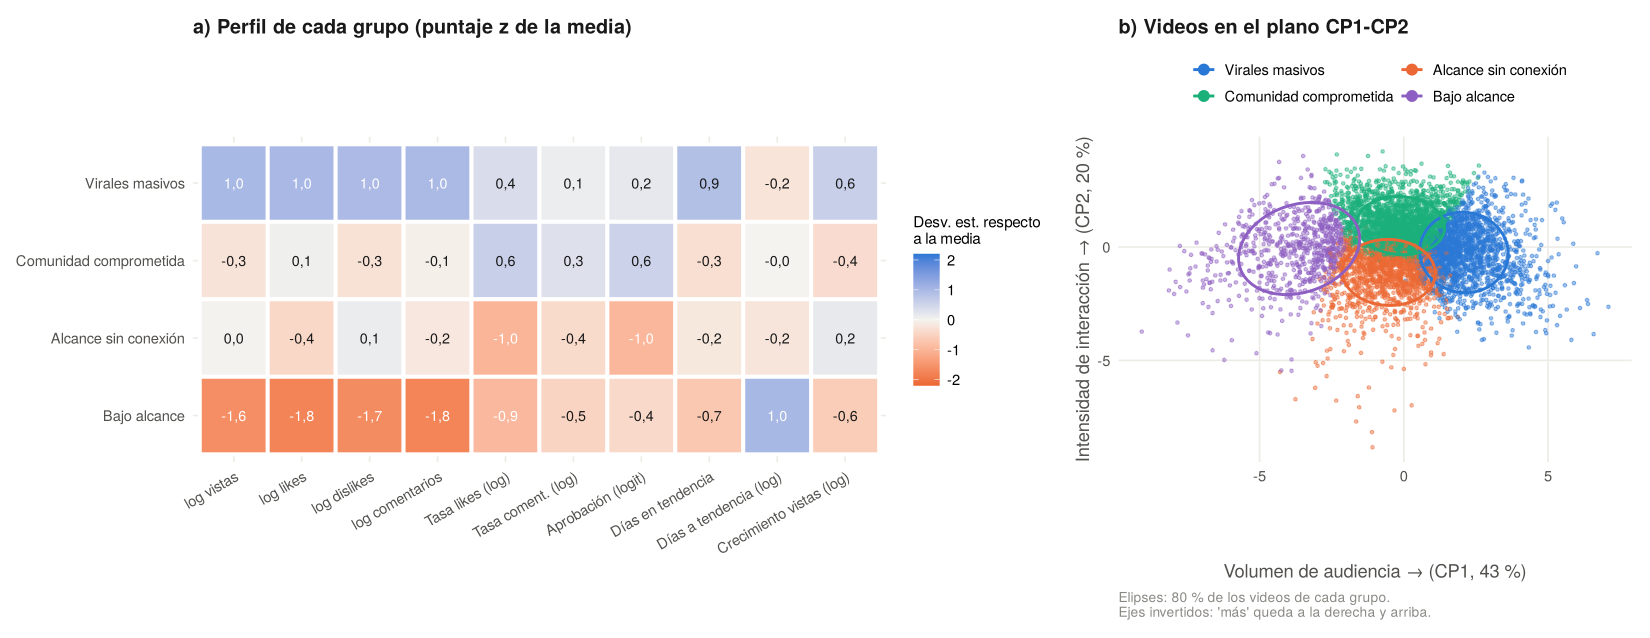

In [27]:
h1 <- perfil_z %>% pivot_longer(-grupo) %>% mutate(name = factor(name, levels = colnames(Z_cl))) %>%
  ggplot(aes(name, fct_rev(grupo), fill = value)) + geom_tile(colour = "white", linewidth = 1.2) +
  geom_text(aes(label = num(value, 1)), size = 3.3, colour = ifelse(abs(perfil_z %>% pivot_longer(-grupo) %>% pull(value)) > 0.9, "white", "#191919")) +
  scale_fill_gradient2(low = NARANJA, mid = "#f4f3ef", high = AZUL, limits = c(-2.2, 2.2), oob = squish, name = "Desv. est. respecto\na la media") +
  labs(title = "a) Perfil de cada grupo (puntaje z de la media)", x = NULL, y = NULL) +
  theme(axis.text.x = element_text(angle = 30, hjust = 1), panel.grid = element_blank(), legend.position = "right")
pcs <- as_tibble(acp$x[, 1:2]) %>% mutate(grupo = base_cl$grupo)
h2 <- ggplot(pcs, aes(-PC1, -PC2, colour = grupo)) + geom_point(size = 0.8, alpha = 0.45) +
  stat_ellipse(linewidth = 0.9, level = 0.8) +
  scale_colour_manual(values = COL_G, name = NULL) + guides(colour = guide_legend(override.aes = list(size = 3, alpha = 1), nrow = 2)) +
  labs(title = "b) Videos en el plano CP1-CP2",
       x = paste0("Volumen de audiencia → (CP1, ", pct(var_exp[1], 0), ")"), y = paste0("Intensidad de interacción → (CP2, ", pct(var_exp[2], 0), ")"),
       caption = "Elipses: 80 % de los videos de cada grupo.\nEjes invertidos: 'más' queda a la derecha y arriba.")
options(repr.plot.width = 15, repr.plot.height = 5.8); h1 + h2 + plot_layout(widths = c(1.35, 1))
guardar(h1 + h2 + plot_layout(widths = c(1.35, 1)), "10_perfil_grupos", 15, 5.8)

**Lectura.** El mapa de calor confirma la interpretación: los *Virales masivos* están por encima de la media en todo, la *Comunidad comprometida* se distingue solo por las tasas de interacción, el grupo *Alcance sin conexión* está en la media de volumen pero 1 desviación estándar por debajo en *likes* por vista y aprobación, y el grupo *Bajo alcance* está por debajo en todo, salvo en los días que tarda en llegar a tendencia.

### 4.4 Validación externa: ¿los grupos coinciden con las categorías de YouTube?

Si los grupos de comportamiento repitieran las categorías, el *clustering* no aportaría información nueva. Se evalúa con tres medidas: la composición de cada categoría por grupo, la V de Cramér (asociación entre las dos clasificaciones) y el índice de Rand ajustado (ARI = 1 si las particiones son idénticas, 0 si coinciden como al azar).

χ² = 1.434,1 | gl = 45 | p < 0,001 | V de Cramér = 0,279 | ARI grupo vs. categoría = 0,029 


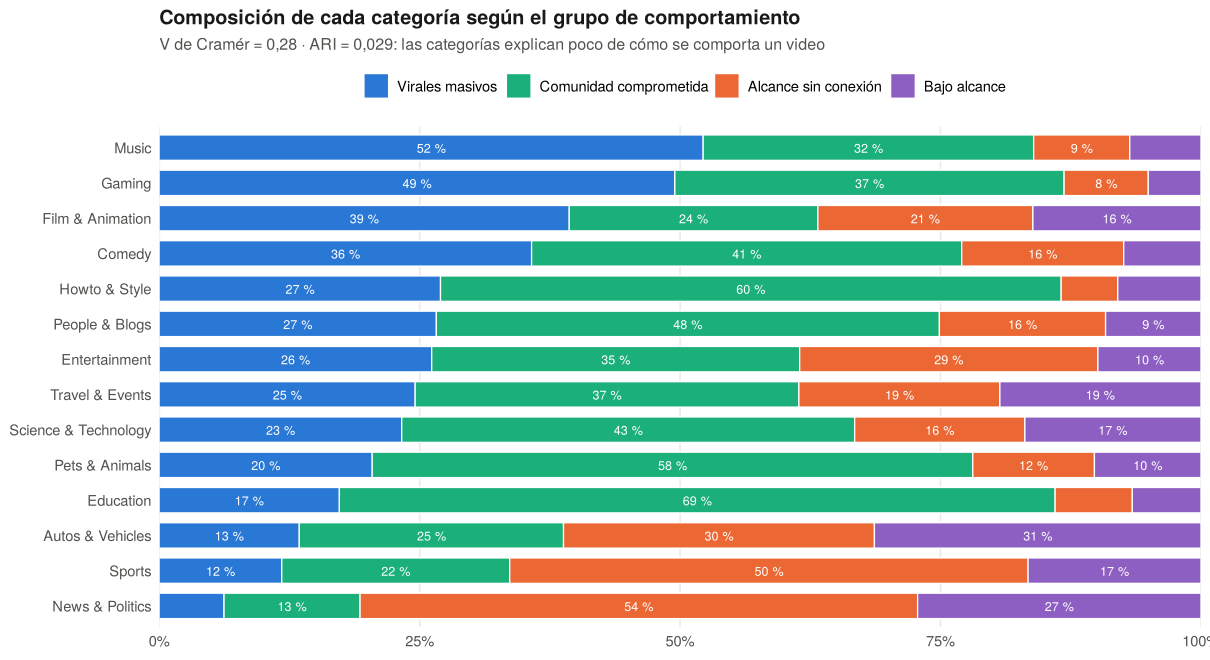

In [28]:
tab_gc <- table(base_cl$categoria, base_cl$grupo)
chi_gc <- suppressWarnings(chisq.test(tab_gc))
v_cramer <- sqrt(unname(chi_gc$statistic) / (sum(tab_gc) * (min(dim(tab_gc)) - 1)))
ari_cat <- adjustedRandIndex(base_cl$categoria, base_cl$grupo)
cat("χ² =", num(chi_gc$statistic, 1), "| gl =", chi_gc$parameter, "| p < 0,001 | V de Cramér =", num(v_cramer, 3), "| ARI grupo vs. categoría =", num(ari_cat, 3), "\n")

comp <- base_cl %>% filter(categoria %in% cats_min$categoria) %>% count(categoria, grupo) %>% group_by(categoria) %>% mutate(p = n / sum(n)) %>% ungroup()
orden_cat <- comp %>% filter(grupo == "Virales masivos") %>% arrange(p) %>% pull(categoria)
p_comp <- comp %>% mutate(categoria = factor(categoria, levels = orden_cat)) %>%
  ggplot(aes(p, categoria, fill = fct_rev(grupo))) + geom_col(width = 0.72, colour = "white", linewidth = 0.4) +
  geom_text(aes(label = ifelse(p >= 0.08, pct(p, 0), "")), position = position_stack(vjust = 0.5), size = 2.9, colour = "white") +
  scale_fill_manual(values = COL_G, name = NULL, breaks = NIVELES_G) + scale_x_continuous(labels = label_percent(), expand = c(0, 0)) +
  labs(title = "Composición de cada categoría según el grupo de comportamiento",
       subtitle = paste0("V de Cramér = ", num(v_cramer, 2), " · ARI = ", num(ari_cat, 3), ": las categorías explican poco de cómo se comporta un video"), x = NULL, y = NULL)
options(repr.plot.width = 11, repr.plot.height = 6); p_comp
guardar(p_comp, "11_grupos_vs_categoria", 11, 6)

**Lectura.** Los grupos y las categorías están asociados (V de Cramér = 0,28), pero **no coinciden** (ARI = 0,03, casi el mismo nivel que el azar). En *Music* predomina el grupo *Virales masivos* (52 %); en *Education*, *Howto & Style* y *Pets & Animals*, el grupo *Comunidad comprometida* (58 % a 69 %); y en *News & Politics* y *Sports*, el grupo *Alcance sin conexión* (50 % a 54 %). Aun así, todas las categorías tienen videos de los cuatro grupos. **El *clustering* aporta información que la categoría no da**: para elegir dónde pautar, el perfil de comportamiento del canal es más informativo que su categoría.

**Enfoque supervisado.** Como contraste, se entrena un *random forest* que intenta reconocer la categoría de un video solo con sus métricas de comportamiento (70 % entrenamiento, 30 % prueba). Si las categorías tuvieran patrones de comportamiento propios, el modelo acertaría mucho más que el modelo base, que siempre predice la categoría más frecuente.

In [29]:
set.seed(SEMILLA)
d_sup <- as_tibble(Z_cl) %>% setNames(make.names(names(.))) %>% mutate(categoria = factor(base_cl$categoria)) %>%
  filter(categoria %in% cats_min$categoria) %>% mutate(categoria = droplevels(categoria))
idx_tr <- sample(nrow(d_sup), 0.7 * nrow(d_sup))
rf_cat <- ranger(categoria ~ ., data = d_sup[idx_tr, ], num.trees = 500, seed = SEMILLA)
pred_cat <- predict(rf_cat, d_sup[-idx_tr, ])$predictions
real_cat <- d_sup$categoria[-idx_tr]
recall_c <- tapply(pred_cat == real_cat, real_cat, mean)
prec_c <- sapply(levels(real_cat), function(l) mean(real_cat[pred_cat == l] == l))
f1_c <- 2 * prec_c * recall_c / (prec_c + recall_c); f1_c[is.na(f1_c)] <- 0; prec_c[is.na(prec_c)] <- 0
cat("Exactitud RF:", pct(mean(pred_cat == real_cat)), "| Exactitud del modelo base (siempre 'Entertainment'):", pct(mean(real_cat == "Entertainment")),
    "| F1 macro:", num(mean(f1_c, na.rm = TRUE), 3), "\n")
tibble(Categoría = names(recall_c), `Sensibilidad (recall)` = pct(recall_c), Precisión = pct(prec_c), F1 = num(f1_c, 2)) %>% arrange(desc(F1))

Exactitud RF: 38,4 % | Exactitud del modelo base (siempre 'Entertainment'): 25,9 % | F1 macro: 0,247 


Categoría,Sensibilidad (recall),Precisión,F1
<chr>,<chr>,<chr>,<chr>
News & Politics,"54,7 %","61,8 %","0,58"
Music,"59,9 %","47,6 %","0,53"
Sports,"43,0 %","53,3 %","0,48"
Entertainment,"62,6 %","36,1 %","0,46"
Howto & Style,"34,5 %","31,6 %","0,33"
Comedy,"23,8 %","34,2 %","0,28"
Pets & Animals,"15,2 %","31,2 %","0,20"
Education,"13,6 %","25,7 %","0,18"
Gaming,"7,9 %","50,0 %","0,14"


**Lectura.** Con solo las métricas de comportamiento, el *random forest* reconoce la categoría correcta en el 38 % de los casos, frente al 26 % del modelo base (F1 macro de 0,25). Las categorías con comportamiento más característico son *News & Politics*, *Music* y *Sports*. Las demás se confunden entre sí. Esto confirma, por la vía supervisada, que la categoría y el comportamiento son dimensiones distintas.

### 4.5 Análisis de correspondencias múltiples (ACM)

El ACM permite trabajar con variables **categóricas y nominales**, como la categoría, el tono o la franja horaria. Las variables activas, que construyen los ejes, son la categoría (las 8 más frecuentes y "Otras"), el nivel de vistas (cuartiles), el nivel de *likes* por vista (terciles), la permanencia en tendencia y el tono del título. Como variables suplementarias, que no intervienen en los ejes, se proyectan la franja horaria, el fin de semana, la mención de *sponsor* y el grupo de K-means. Como la tasa de inercia bruta del ACM subestima la calidad de los planos, se aplica la corrección de Benzécri.

In [30]:
top_cats <- por_cat %>% slice_max(videos, n = 8) %>% pull(categoria)
d_acm <- base_cl %>% transmute(
  Categoria = factor(if_else(categoria %in% top_cats, categoria, "Otras")),
  Vistas = cut(vistas, quantile(vistas, 0:4 / 4), include.lowest = TRUE, labels = c("Vistas Q1 (bajas)", "Vistas Q2", "Vistas Q3", "Vistas Q4 (altas)")),
  Likes = cut(tasa_likes, quantile(tasa_likes, 0:3 / 3), include.lowest = TRUE, labels = c("Likes/vista bajo", "Likes/vista medio", "Likes/vista alto")),
  Permanencia = cut(dias_tendencia, c(0, 3, 7, 40), labels = c("1-3 días", "4-7 días", "8+ días")),
  Tono = paste("Tono", str_to_lower(tono)),
  Franja = franja, FinSemana = if_else(fin_semana, "Fin de semana", "Entre semana"),
  Sponsor = if_else(menciona_sponsor, "Con mención sponsor", "Sin mención sponsor"), Grupo = grupo) %>% mutate(across(everything(), factor))
acm <- MCA(d_acm, quali.sup = 6:9, graph = FALSE)
Q <- 5; lam <- acm$eig[, 1]; lam_c <- ifelse(lam > 1 / Q, ((Q / (Q - 1)) * (lam - 1 / Q))^2, 0)
eig_tab <- tibble(Dimensión = 1:5, `Valor propio` = lam[1:5], `Inercia bruta` = acm$eig[1:5, 2] / 100, `Benzécri` = (lam_c / sum(lam_c))[1:5])
eig_tab %>% mutate(`Valor propio` = num(`Valor propio`, 3), across(c(`Inercia bruta`, `Benzécri`), pct))

Dimensión,Valor propio,Inercia bruta,Benzécri
<int>,<chr>,<chr>,<chr>
1,"0,343","10,1 %","78,5 %"
2,"0,260","7,7 %","14,1 %"
3,"0,229","6,7 %","3,3 %"
4,"0,224","6,6 %","2,3 %"
5,"0,217","6,4 %","1,1 %"


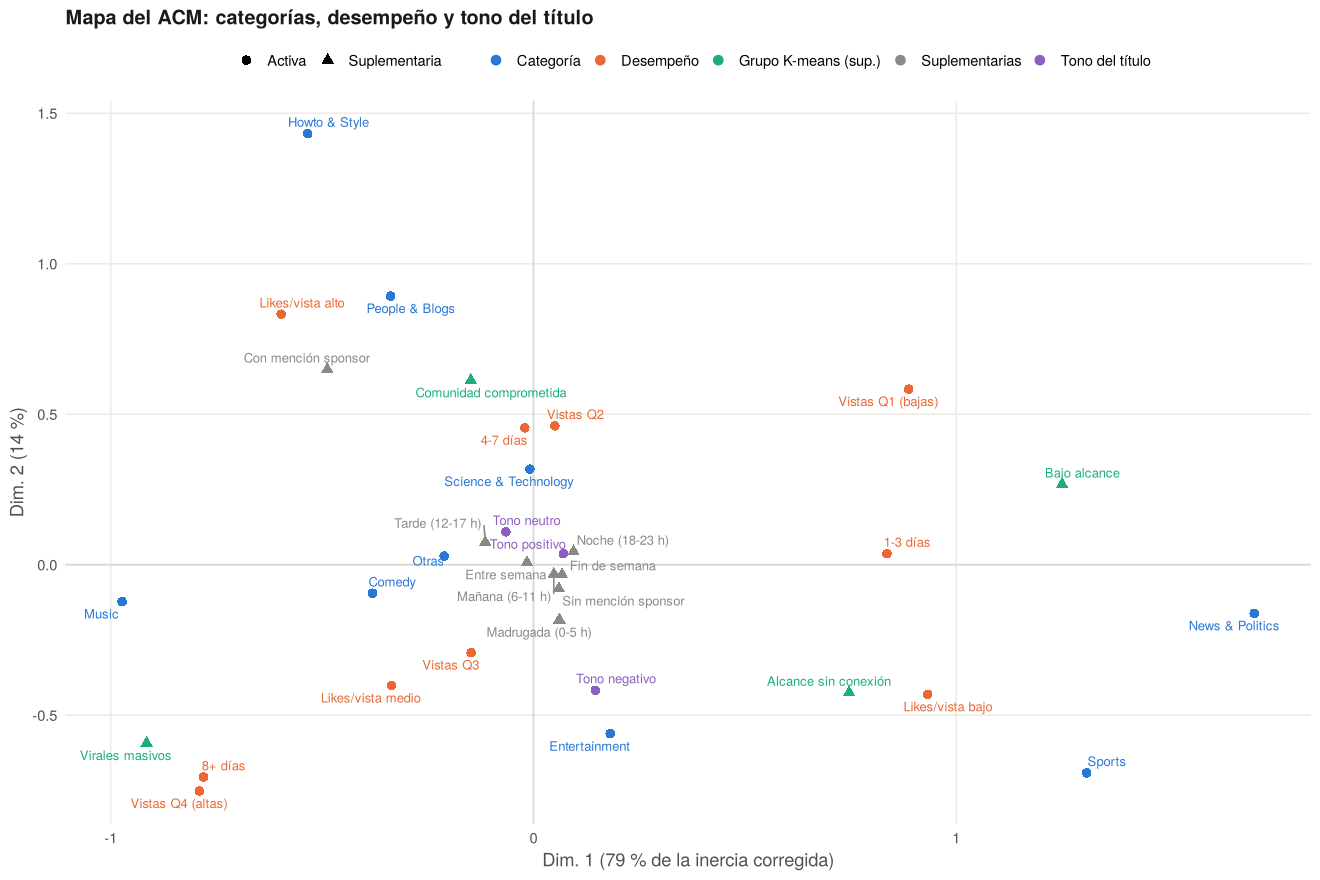

In [31]:
coord_act <- as_tibble(acm$var$coord[, 1:2], rownames = "cat") %>% mutate(tipo = "Activa")
coord_sup <- as_tibble(acm$quali.sup$coord[, 1:2], rownames = "cat") %>% mutate(tipo = "Suplementaria")
var_de <- c(setNames(rep(names(d_acm), sapply(d_acm, nlevels)), unlist(lapply(d_acm, levels))))
coords <- bind_rows(coord_act, coord_sup) %>% mutate(variable = var_de[cat],
  variable = recode(variable, Categoria = "Categoría", Vistas = "Desempeño", Likes = "Desempeño", Permanencia = "Desempeño", Tono = "Tono del título",
                    Franja = "Suplementarias", FinSemana = "Suplementarias", Sponsor = "Suplementarias", Grupo = "Grupo K-means (sup.)"))
p_acm <- ggplot(coords, aes(`Dim 1`, `Dim 2`, colour = variable)) +
  geom_hline(yintercept = 0, colour = GRIS_CLARO) + geom_vline(xintercept = 0, colour = GRIS_CLARO) +
  geom_point(aes(shape = tipo), size = 2.6) +
  geom_text_repel(aes(label = cat), size = 3, max.overlaps = 40, show.legend = FALSE, seed = SEMILLA) +
  scale_colour_manual(values = c(`Categoría` = AZUL, `Desempeño` = NARANJA, `Tono del título` = MORADO, `Suplementarias` = GRIS, `Grupo K-means (sup.)` = AQUA), name = NULL) +
  scale_shape_manual(values = c(Activa = 16, Suplementaria = 17), name = NULL) +
  labs(title = "Mapa del ACM: categorías, desempeño y tono del título",
       x = paste0("Dim. 1 (", pct(eig_tab$Benzécri[1], 0), " de la inercia corregida)"), y = paste0("Dim. 2 (", pct(eig_tab$Benzécri[2], 0), ")"))
options(repr.plot.width = 12, repr.plot.height = 8); p_acm
guardar(p_acm, "12_acm", 12, 8)

In [32]:
# Medidas de discriminación (η²) por dimensión
as_tibble(acm$var$eta2[, 1:2], rownames = "Variable activa") %>% mutate(across(where(is.numeric), ~ num(.x, 3)))

Variable activa,Dim 1,Dim 2
<chr>,<chr>,<chr>
Categoria,"0,527","0,382"
Vistas,"0,359","0,301"
Likes,"0,446","0,346"
Permanencia,"0,374","0,233"
Tono,"0,007","0,039"


**Lectura del ACM.** Con la corrección de Benzécri, el primer eje concentra el **79 % de la inercia** y el segundo el 14 %, de modo que el plano resume casi toda la asociación. El **eje 1 es un gradiente de desempeño**: a la izquierda están las vistas altas (Q4), la permanencia de 8 días o más, los *likes* por vista altos y *Music*; a la derecha, las vistas bajas (Q1), la permanencia de 1 a 3 días, los *likes* por vista bajos, *News & Politics* y *Sports*. El **eje 2 separa el tipo de interacción**: arriba, *Howto & Style* y *People & Blogs* junto a la categoría *Likes/vista alto*; abajo, *Entertainment*, *Sports* y el tono negativo. La categoría (η² = 0,53) y los *likes* por vista (0,45) son las variables que más construyen el eje 1; el tono casi no discrimina (0,01).

Entre las suplementarias destaca que **los videos con mención de *sponsor* o afiliados se ubican junto a los *likes* por vista altos y al grupo *Comunidad comprometida***: el contenido patrocinado no se asocia con una peor interacción. La franja horaria y el fin de semana quedan cerca del origen: el momento de publicación casi no se asocia con el perfil de desempeño.

## 5. P3 — ¿Qué combinación de atributos hace que un video sea tendencia y se mantenga?

**Planteamiento.** Todos los videos de la base ya son tendencia, así que la pregunta útil para el negocio es **qué distingue a los videos que se sostienen en tendencia**. Un video que permanece más días acumula más exposición y más tráfico potencial hacia el sitio web. Se define:

* **Variable objetivo:** *tendencia sostenida* = permanecer **7 días o más** en la lista (umbral cercano a la mediana, de 6 días, y que equivale a una semana completa).
* **Censura:** se excluyen los videos que ya estaban en tendencia el primer día de captura (no se sabe cuándo entraron) y los que entraron en los últimos 7 días del periodo (no tuvieron tiempo de llegar a 7 días).
* **Predictoras disponibles al entrar a tendencia (sin fuga de información):** atributos del título, las etiquetas y la descripción; categoría; hora y día de publicación; señal temprana del primer día (vistas, *likes*, comentarios y horas transcurridas desde la publicación); y la **trayectoria previa del canal**: cuántos videos suyos habían sido tendencia **antes** y con cuántas vistas en promedio. Esta última se calcula solo con videos anteriores, para no usar información del futuro.

Técnicas: *random forest* (importancia por **índice de Gini** y por permutación), regresión logística (razones de momios interpretables) y un árbol de decisión corto para traducir el resultado a reglas.

In [33]:
# Trayectoria previa del canal calculada con sus videos anteriores
media_global_log <- mean(log10(videos$vistas))
videos <- videos %>% arrange(primera_tendencia, publicacion_et) %>% group_by(canal) %>%
  mutate(canal_previos = row_number() - 1L,
         canal_log_vistas_prev = (cumsum(log10(vistas)) - log10(vistas)) / pmax(canal_previos, 1),
         canal_log_vistas_prev = if_else(canal_previos == 0, NA_real_, canal_log_vistas_prev)) %>% ungroup() %>%
  mutate(canal_prev_suav = (canal_previos * coalesce(canal_log_vistas_prev, 0) + 3 * media_global_log) / (canal_previos + 3))  # contracción hacia la media global

fecha_ini <- min(limpio$fecha_tendencia); fecha_fin <- max(limpio$fecha_tendencia)
d_p3 <- videos %>% filter(primera_tendencia > fecha_ini, primera_tendencia <= fecha_fin - 7, !is.na(likes_ini), !is.na(comentarios_ini)) %>%
  mutate(sostenida = factor(if_else(dias_tendencia >= 7, "Sí", "No"), levels = c("No", "Sí")),
         log_vistas_ini = log10(vistas_ini), tasa_likes_ini = likes_ini / vistas_ini, tasa_coment_ini = comentarios_ini / vistas_ini,
         aprob_ini = likes_ini / pmax(likes_ini + dislikes_ini, 1), log_horas_a_tend = log10(horas_a_tendencia),
         categoria = factor(categoria), dia_pub = factor(dia_pub))
cat("Videos en el análisis:", num(nrow(d_p3)), "| Con tendencia sostenida (≥ 7 días):", pct(mean(d_p3$sostenida == "Sí")), "\n")

predictoras_p3 <- c("categoria", "hora_pub", "dia_pub", "largo_titulo", "prop_mayus", "tiene_exclam", "tiene_pregunta", "tiene_numero", "tiene_emoji",
                    "palabra_oficial", "palabra_trailer", "palabra_vs", "palabra_reaccion", "sentimiento", "n_etiquetas", "largo_desc", "n_enlaces",
                    "menciona_sponsor", "enlaces_redes", "log_vistas_ini", "tasa_likes_ini", "tasa_coment_ini", "aprob_ini", "log_horas_a_tend",
                    "resurgido", "canal_previos", "canal_prev_suav")
etiquetas_var <- c(categoria = "Categoría", hora_pub = "Hora de publicación", dia_pub = "Día de publicación", largo_titulo = "Largo del título",
                   prop_mayus = "% mayúsculas en título", tiene_exclam = "Título con '!'", tiene_pregunta = "Título con '?'", tiene_numero = "Título con número",
                   tiene_emoji = "Título con emoji", palabra_oficial = "Título 'official'", palabra_trailer = "Título 'trailer/teaser'", palabra_vs = "Título 'vs'",
                   palabra_reaccion = "Título reto/reacción", sentimiento = "Sentimiento del título", n_etiquetas = "N.º de etiquetas", largo_desc = "Largo de la descripción",
                   n_enlaces = "N.º de enlaces en descripción", menciona_sponsor = "Menciona sponsor/afiliado", enlaces_redes = "Enlaces a redes sociales",
                   log_vistas_ini = "Vistas al entrar a tendencia (log)", tasa_likes_ini = "Likes/vista al entrar", tasa_coment_ini = "Comentarios/vista al entrar",
                   aprob_ini = "Aprobación al entrar", log_horas_a_tend = "Horas hasta entrar a tendencia (log)", resurgido = "Video resurgido (> 30 días)",
                   canal_previos = "Videos previos del canal en tendencia", canal_prev_suav = "Vistas previas del canal (log, suavizado)")

set.seed(SEMILLA)
idx_p3 <- caret::createDataPartition(d_p3$sostenida, p = 0.75, list = FALSE)[, 1]
tr3 <- d_p3[idx_p3, c("sostenida", predictoras_p3)]; te3 <- d_p3[-idx_p3, c("sostenida", predictoras_p3)]
auc <- function(y, p) { y <- as.integer(y == "Sí"); r <- rank(p); (sum(r[y == 1]) - sum(y) * (sum(y) + 1) / 2) / (sum(y) * sum(1 - y)) }

# Random forest con importancia de Gini (impureza) y por permutación
rf3 <- ranger(sostenida ~ ., data = tr3, num.trees = 800, mtry = 6, min.node.size = 10, probability = TRUE, importance = "impurity", seed = SEMILLA)
rf3_perm <- ranger(sostenida ~ ., data = tr3, num.trees = 800, mtry = 6, min.node.size = 10, probability = TRUE, importance = "permutation", seed = SEMILLA)
p_rf3 <- predict(rf3, te3)$predictions[, "Sí"]
# Regresión logística con variables numéricas estandarizadas
num_vars <- predictoras_p3[sapply(tr3[predictoras_p3], is.numeric)]
medias3 <- sapply(tr3[num_vars], mean); sds3 <- sapply(tr3[num_vars], sd)
estd <- function(d) { d[num_vars] <- sweep(sweep(d[num_vars], 2, medias3), 2, sds3, "/"); d }
glm3 <- suppressWarnings(glm(sostenida ~ ., data = estd(tr3), family = binomial))
p_glm3 <- predict(glm3, estd(te3), type = "response")
y3 <- te3$sostenida
metricas_clas <- function(p, nombre, umbral = 0.5) { pred <- if_else(p >= umbral, "Sí", "No")
  tibble(Modelo = nombre, AUC = auc(y3, p), Exactitud = mean(pred == y3), Sensibilidad = mean(pred[y3 == "Sí"] == "Sí"), Especificidad = mean(pred[y3 == "No"] == "No")) }
res_p3 <- bind_rows(tibble(Modelo = "Base (clase mayoritaria)", AUC = 0.5, Exactitud = max(mean(y3 == "Sí"), mean(y3 == "No")), Sensibilidad = NA, Especificidad = NA),
                    metricas_clas(p_glm3, "Regresión logística"), metricas_clas(p_rf3, "Random forest"))
res_p3 %>% mutate(AUC = num(AUC, 3), across(c(Exactitud, Sensibilidad, Especificidad), ~ ifelse(is.na(.x), "-", pct(.x))))

Videos en el análisis: 5.953 | Con tendencia sostenida (≥ 7 días): 41,4 % 


Modelo,AUC,Exactitud,Sensibilidad,Especificidad
<chr>,<chr>,<chr>,<chr>,<chr>
Base (clase mayoritaria),"0,500","58,6 %",-,-
Regresión logística,"0,739","67,8 %","56,8 %","75,5 %"
Random forest,"0,766","69,8 %","60,4 %","76,5 %"


**Desempeño.** Ambos modelos superan claramente al modelo base. El *random forest* alcanza un **AUC de 0,77**: al tomar un video que se sostiene y otro que no, el modelo asigna mayor probabilidad al primero en el 77 % de los casos. La regresión logística queda cerca (AUC de 0,74), lo que indica que buena parte de la relación es aproximadamente lineal.

Tipo de atributo,Importancia (Gini),Importancia (permutación)
<chr>,<chr>,<chr>
Señal temprana,"45,5 %","63,4 %"
"Contenido (título, etiquetas, descripción)","31,7 %","15,1 %"
Trayectoria del canal,"12,0 %","15,9 %"
Categoría y tiempo,"10,8 %","5,7 %"


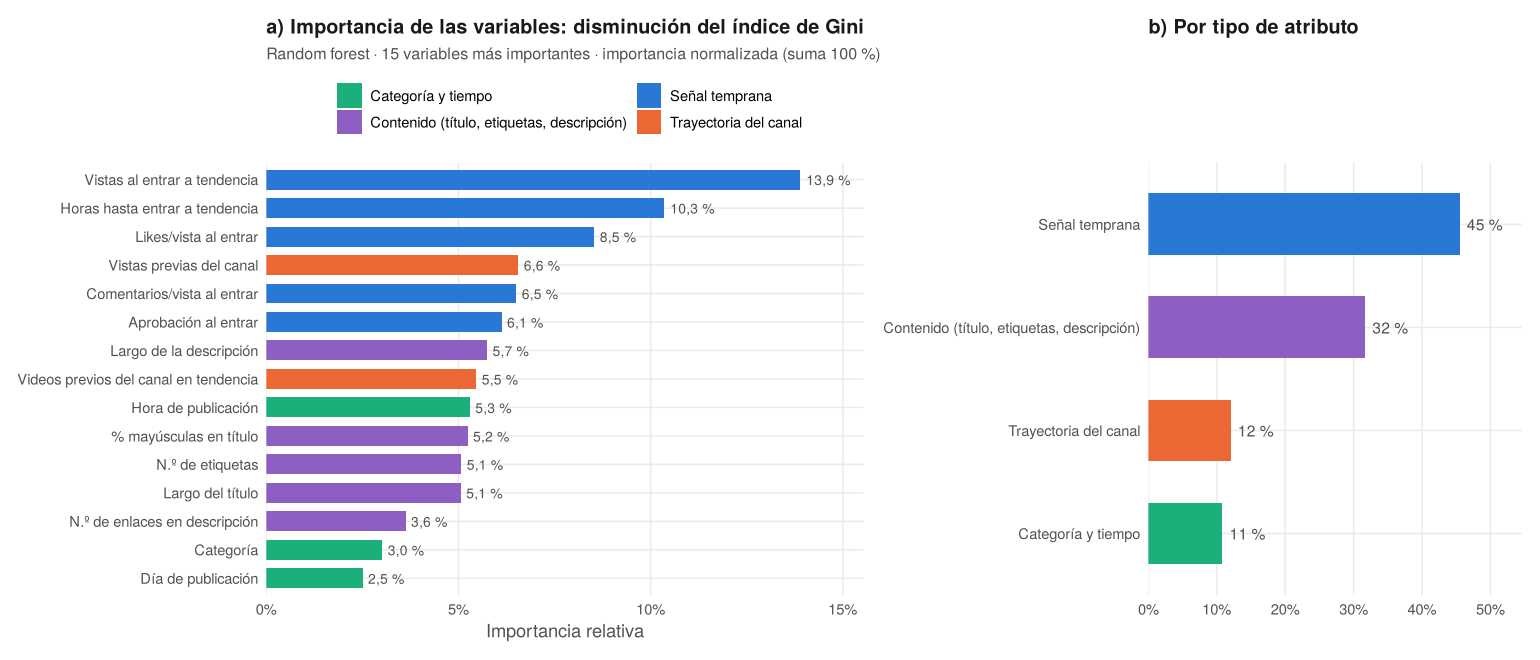

In [34]:
imp <- tibble(var = names(rf3$variable.importance), gini = rf3$variable.importance, perm = rf3_perm$variable.importance[names(rf3$variable.importance)]) %>%
  mutate(gini = gini / sum(gini), perm = pmax(perm, 0) / sum(pmax(perm, 0)), etiqueta = etiquetas_var[var],
         grupo = case_when(var %in% c("log_vistas_ini", "tasa_likes_ini", "tasa_coment_ini", "aprob_ini", "log_horas_a_tend", "resurgido") ~ "Señal temprana",
                           var %in% c("canal_previos", "canal_prev_suav") ~ "Trayectoria del canal",
                           var %in% c("categoria", "hora_pub", "dia_pub") ~ "Categoría y tiempo", TRUE ~ "Contenido (título, etiquetas, descripción)"))
imp_top <- imp %>% slice_max(gini, n = 15) %>% mutate(etiqueta = fct_reorder(etiqueta, gini))
COL_IMP <- c(`Señal temprana` = AZUL, `Trayectoria del canal` = NARANJA, `Categoría y tiempo` = AQUA, `Contenido (título, etiquetas, descripción)` = MORADO)
imp_top <- imp %>% slice_max(gini, n = 15) %>%
  mutate(etiqueta = str_remove(etiqueta, " \\(log\\)| \\(log, suavizado\\)"), etiqueta = fct_reorder(etiqueta, gini))
i1 <- ggplot(imp_top, aes(gini, etiqueta, fill = grupo)) + geom_col(width = 0.7) +
  geom_text(aes(label = pct(gini, 1)), hjust = -0.15, size = 3.2, colour = TINTA) +
  scale_fill_manual(values = COL_IMP, name = NULL) + scale_x_continuous(labels = label_percent(), expand = expansion(mult = c(0, .12))) +
  guides(fill = guide_legend(nrow = 2)) +
  labs(title = "a) Importancia de las variables: disminución del índice de Gini", subtitle = "Random forest · 15 variables más importantes · importancia normalizada (suma 100 %)", x = "Importancia relativa", y = NULL)
imp_grupo <- imp %>% group_by(grupo) %>% summarise(gini = sum(gini), perm = sum(perm))
i2 <- imp_grupo %>% mutate(grupo = fct_reorder(grupo, gini)) %>%
  ggplot(aes(gini, grupo, fill = grupo)) + geom_col(width = 0.6) + geom_text(aes(label = pct(gini, 0)), hjust = -0.2, size = 3.6, colour = TINTA) +
  scale_fill_manual(values = COL_IMP, guide = "none") + scale_x_continuous(labels = label_percent(), expand = expansion(mult = c(0, .2))) +
  labs(title = "b) Por tipo de atributo", x = NULL, y = NULL)
options(repr.plot.width = 14, repr.plot.height = 6); i1 + i2 + plot_layout(widths = c(1.6, 1))
guardar(i1 + i2 + plot_layout(widths = c(1.6, 1)), "13b_importancia_gini", 14, 6)
imp_grupo %>% arrange(desc(gini)) %>% transmute(`Tipo de atributo` = grupo, `Importancia (Gini)` = pct(gini), `Importancia (permutación)` = pct(perm))

**Respuesta a P3.** El factor dominante es la **señal temprana** (entre el 45 % y el 63 % de la importancia según el método): cuántas vistas tiene el video al entrar a tendencia, qué tan rápido llegó y cómo reacciona la audiencia. Le siguen los **atributos de contenido** (15 % a 32 %) y la **trayectoria del canal** (12 % a 16 %). La categoría y el momento de publicación aportan poco. La diferencia entre los dos métodos es esperable: la importancia de Gini sobrevalora las variables continuas con muchos valores posibles, como el largo de la descripción o del título, mientras que la importancia por permutación mide cuánto empeora el modelo al desordenar cada variable y por eso es más confiable. Ambas coinciden en el orden de los primeros lugares.

Término,Razón de momios,IC 95 %,p
<chr>,<chr>,<chr>,<chr>
Vistas al entrar a tendencia (log),"2,14","[1,96; 2,35]","< 0,001"
Horas hasta entrar a tendencia (log),"0,42","[0,37; 0,49]","< 0,001"
Videos previos del canal en tendencia,"0,67","[0,61; 0,73]","< 0,001"
Video resurgido (> 30 días),"68,20","[20,95; 214,24]","< 0,001"
N.º de etiquetas,"0,88","[0,81; 0,95]","0,001"
Título 'official',"1,42","[1,04; 1,94]","0,029"
Día de publicación: jueves,"1,29","[1,02; 1,63]","0,036"


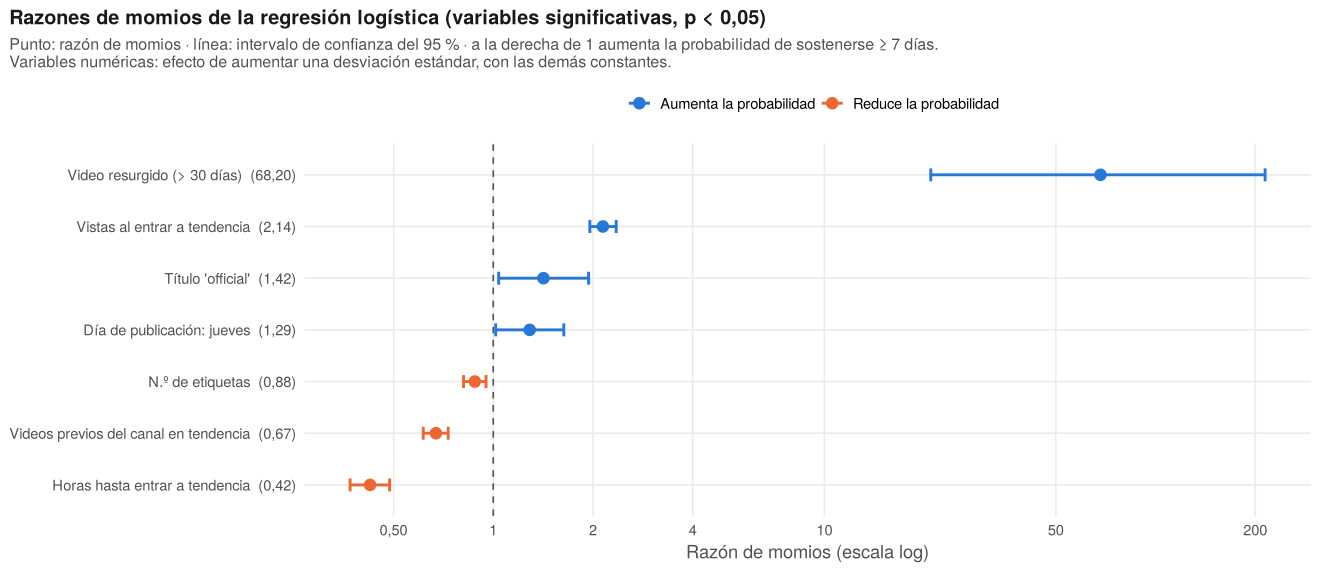

In [35]:
traducir <- function(txt) {
  txt <- str_replace_all(txt, "log_vistas_ini(>=|< )([0-9.]+)", function(m) { u <- str_match(m, "(>=|< )([0-9.]+)"); paste0("Vistas al entrar ", ifelse(u[2] == ">=", "≥ ", "< "), lab_corta(10^as.numeric(u[3]))) })
  txt <- str_replace_all(txt, "log_horas_a_tend(>=|< )([0-9.]+)", function(m) { u <- str_match(m, "(>=|< )([0-9.]+)"); paste0("Horas hasta tendencia ", ifelse(u[2] == ">=", "≥ ", "< "), num(10^as.numeric(u[3]), 0)) })
  txt <- str_replace_all(txt, "(tasa_likes_ini|tasa_coment_ini)(>=|< )([0-9.]+)", function(m) { u <- str_match(m, "(tasa_likes_ini|tasa_coment_ini)(>=|< )([0-9.]+)"); paste0(etiquetas_var[[u[2]]], ifelse(u[3] == ">=", " ≥ ", " < "), num(100 * as.numeric(u[4]), 1), " %") })
  for (v in names(etiquetas_var)[order(-nchar(names(etiquetas_var)))]) txt <- str_replace_all(txt, fixed(v), etiquetas_var[[v]])
  txt <- str_replace_all(txt, "(Día de publicación|Categoría)([a-zA-Z])", "\\1: \\2")
  txt <- str_replace_all(txt, "\\s*>=\\s*", " ≥ "); txt <- str_replace_all(txt, "\\s*<\\s+", " < ")
  str_replace_all(txt, "([0-9])\\.([0-9])", "\\1,\\2") }
# Razones de momios de la regresión logística
or_tab <- suppressWarnings(broom::tidy(glm3, conf.int = TRUE, exponentiate = TRUE)) %>% filter(term != "(Intercept)", p.value < 0.05) %>%
  arrange(p.value) %>% transmute(Término = traducir(str_remove(term, "TRUE$")), `Razón de momios` = num(estimate, 2), `IC 95 %` = paste0("[", num(conf.low, 2), "; ", num(conf.high, 2), "]"), p = pval(p.value))
or_tab
or_df <- suppressWarnings(broom::tidy(glm3, conf.int = TRUE, exponentiate = TRUE)) %>% filter(term != "(Intercept)", p.value < 0.05) %>%
  mutate(lab = str_remove(traducir(str_remove(term, "TRUE$")), " \\(log\\)"), dir = if_else(estimate > 1, "Aumenta la probabilidad", "Reduce la probabilidad"),
         lab = fct_reorder(paste0(lab, "  (", num(estimate, 2), ")"), estimate))
p_or <- ggplot(or_df, aes(estimate, lab, colour = dir)) + geom_vline(xintercept = 1, linetype = "dashed", colour = TINTA) +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.25, linewidth = 0.9) + geom_point(size = 3.2) +
  scale_x_log10(breaks = c(0.25, 0.5, 1, 2, 4, 10, 50, 200), labels = function(x) num(x, ifelse(x < 1, 2, 0))) +
  scale_colour_manual(values = c(`Aumenta la probabilidad` = AZUL, `Reduce la probabilidad` = NARANJA), name = NULL) +
  labs(title = "Razones de momios de la regresión logística (variables significativas, p < 0,05)",
       subtitle = "Punto: razón de momios · línea: intervalo de confianza del 95 % · a la derecha de 1 aumenta la probabilidad de sostenerse ≥ 7 días.\nVariables numéricas: efecto de aumentar una desviación estándar, con las demás constantes.",
       x = "Razón de momios (escala log)", y = NULL) + theme(plot.title.position = "plot")
options(repr.plot.width = 12, repr.plot.height = 5.2); p_or
guardar(p_or, "13c_razones_momios", 12, 5.2)

**Lectura de las razones de momios** (variables numéricas: efecto de aumentar una desviación estándar, manteniendo las demás constantes):

* **Vistas al entrar (2,1):** un video que entra a tendencia con más audiencia tiene el doble de *odds* de sostenerse.
* **Horas hasta la tendencia (0,42):** cuanto más rápido llega a tendencia, más probable es que se mantenga. La velocidad inicial es una señal clave.
* **Videos previos del canal en tendencia (0,67):** los canales que entran a tendencia muy seguido (TV nocturna, deportes, noticias) se sostienen **menos**, porque su contenido es de actualidad y caduca rápido.
* **Título con "official" (1,4):** los lanzamientos oficiales (música y tráileres) se sostienen más.
* **Más etiquetas (0,88):** saturar de etiquetas no ayuda.
* **Videos resurgidos:** el efecto es muy grande, pero se basa en muy pocos casos (intervalo muy amplio), así que no debe sobreinterpretarse.

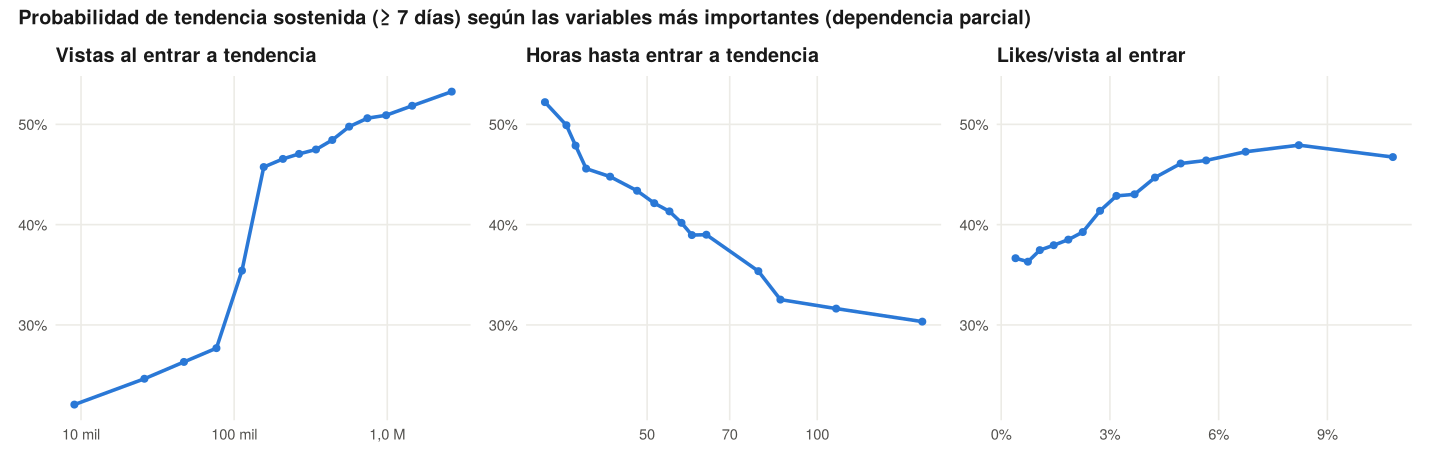

In [36]:
# Efecto marginal (dependencia parcial) de las tres variables numéricas más importantes
top_num <- imp %>% filter(var %in% num_vars) %>% slice_max(gini, n = 3) %>% pull(var)
pdp_df <- map_dfr(top_num, function(v) {
  rejilla <- quantile(tr3[[v]], seq(0.05, 0.95, length.out = 15), na.rm = TRUE)
  muestra <- tr3[sample(nrow(tr3), min(800, nrow(tr3))), ]
  map_dfr(rejilla, function(g) { m <- muestra; m[[v]] <- g; tibble(var = v, x = g, p = mean(predict(rf3, m)$predictions[, "Sí"])) })
})
graf_pdp <- function(v) {
  d <- pdp_df %>% filter(var == v)
  g <- ggplot(d, aes(if (str_starts(v, "log_")) 10^x else x, p)) + geom_line(colour = AZUL, linewidth = 1.1) + geom_point(colour = AZUL, size = 1.8) +
    scale_y_continuous(labels = label_percent(), limits = range(pdp_df$p)) + labs(title = str_remove(etiquetas_var[[v]], " \\(log\\)"), x = NULL, y = NULL)
  if (str_starts(v, "log_")) g <- g + scale_x_log10(labels = lab_corta) else if (str_starts(v, "tasa_")) g <- g + scale_x_continuous(labels = label_percent(accuracy = 1)) else g
  g
}
p_pdp <- wrap_plots(purrr::map(top_num, graf_pdp), nrow = 1) +
  plot_annotation(title = "Probabilidad de tendencia sostenida (≥ 7 días) según las variables más importantes (dependencia parcial)")
options(repr.plot.width = 13, repr.plot.height = 4.2); p_pdp
guardar(p_pdp, "14_dependencia_parcial", 13, 4.2)

**Lectura.** La probabilidad de sostenerse **salta del 28 % al 46 % cuando el video entra a tendencia con más de unas 150.000 vistas** y luego sigue subiendo más despacio. **Cae del 52 % al 30 %** cuando el video tarda de 1 a 6 días en llegar a tendencia. También sube con la tasa de *likes* al entrar, hasta cerca del 8 %. Para la empresa, **las primeras 24 a 48 horas son decisivas**: concentrar la promoción del video propio (correo, redes y sitio web) en ese periodo aumenta la probabilidad de que se mantenga en tendencia.

**Reglas de decisión.** Un árbol de decisión con profundidad 3 traduce la combinación de atributos a reglas que un equipo de contenido puede aplicar. Sacrifica algo de precisión a cambio de poder leerse.

In [37]:
arbol <- rpart::rpart(sostenida ~ ., data = tr3, method = "class", control = rpart::rpart.control(maxdepth = 3, cp = 0.002, minbucket = 80))
p_arbol <- predict(arbol, te3)[, "Sí"]
cat("AUC del árbol en prueba:", num(auc(y3, p_arbol), 3), "\n")
hojas <- which(arbol$frame$var == "<leaf>")
reglas <- rpart::path.rpart(arbol, nodes = as.numeric(rownames(arbol$frame)[hojas]), print.it = FALSE)
tibble(Condiciones = map_chr(reglas, ~ traducir(paste(.x[-1], collapse = "  Y  "))),
       Videos = arbol$frame$n[hojas], p = arbol$frame$yval2[hojas, 5]) %>%
  arrange(desc(round(p, 3)), desc(Videos)) %>% mutate(Regla = row_number(), `% sostenida` = pct(p)) %>% select(Regla, Condiciones, Videos, `% sostenida`)

AUC del árbol en prueba: 0,667 


Regla,Condiciones,Videos,% sostenida
<int>,<chr>,<int>,<chr>
1,"Vistas al entrar ≥ 143 mil Y Videos previos del canal en tendencia < 20,5 Y Horas hasta tendencia < 86",2085,"58,8 %"
2,"Vistas al entrar ≥ 143 mil Y Videos previos del canal en tendencia < 20,5 Y Horas hasta tendencia ≥ 86",433,"39,0 %"
3,Vistas al entrar < 143 mil,1585,"23,4 %"
4,"Vistas al entrar ≥ 143 mil Y Videos previos del canal en tendencia ≥ 20,5",363,"23,4 %"


**Diagrama del árbol.** Cada caja es una pregunta o una regla final; las etiquetas de las ramas indican el corte elegido.

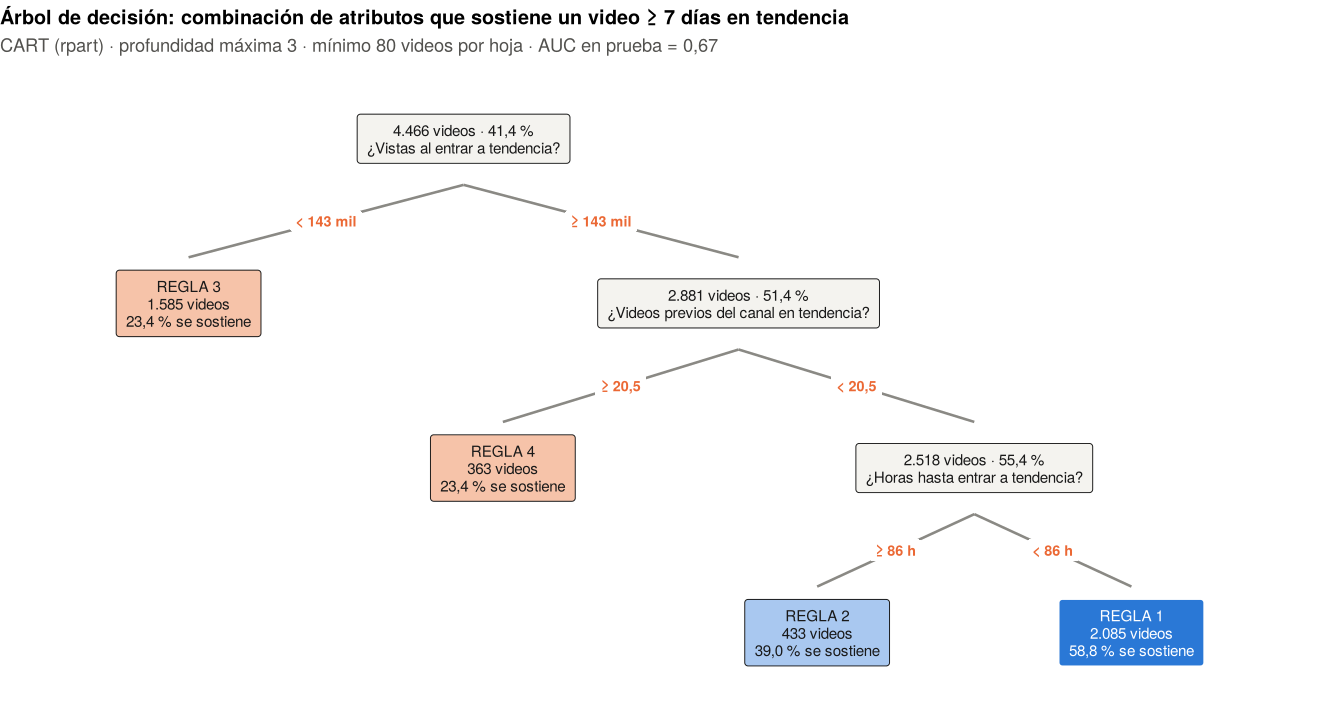

In [38]:
fr <- arbol$frame %>% mutate(nodo = as.integer(rownames(arbol$frame)), prof = floor(log2(nodo)), hoja = var == "<leaf>", p = yval2[, 5])
fr$x <- NA_real_; fr$x[fr$hoja] <- seq_len(sum(fr$hoja))
for (k in sort(fr$nodo[!fr$hoja], decreasing = TRUE)) fr$x[fr$nodo == k] <- mean(fr$x[fr$nodo %in% c(2 * k, 2 * k + 1)])
fr <- fr %>% mutate(x = x / max(x), y = max(prof) - prof + 1)
orden_reglas <- fr %>% filter(hoja) %>% arrange(desc(round(p, 3)), desc(n)) %>% mutate(regla = row_number()) %>% select(nodo, regla)
fr <- fr %>% left_join(orden_reglas, by = "nodo") %>%
  mutate(texto = if_else(hoja, paste0("REGLA ", regla, "\n", num(n), " videos\n", pct(p), " se sostiene"),
                         paste0(num(n), " videos · ", pct(p), "\n¿", str_remove(etiquetas_var[as.character(var)], " \\(log\\)"), "?")),
         tipo = case_when(!hoja ~ "pregunta", p == max(p[hoja]) ~ "alta", p >= mean(d_p3$sostenida == "Sí") - 0.05 ~ "media", TRUE ~ "baja"))
etq_rama <- traducir(labels(arbol))
ramas <- fr %>% filter(nodo > 1) %>% mutate(padre = nodo %/% 2, etq = str_replace(etq_rama[match(nodo, fr$nodo)], "^(Vistas al entrar|Videos previos del canal en tendencia|Horas hasta tendencia) ", ""),
         etq = if_else(str_detect(etq_rama[match(nodo, fr$nodo)], "^Horas"), paste(etq, "h"), etq)) %>%
  left_join(fr %>% select(padre = nodo, x0 = x, y0 = y), by = "padre")
p_arbol_d <- ggplot() +
  geom_segment(data = ramas, aes(x = x0, y = y0 - 0.28, xend = x, yend = y + 0.28), colour = GRIS, linewidth = 0.8) +
  geom_label(data = ramas, aes(x = (x0 + x) / 2, y = (y0 + y) / 2, label = etq), size = 3.3, colour = NARANJA, fontface = "bold", label.size = 0, fill = "white") +
  geom_label(data = fr, aes(x, y, label = texto, fill = tipo, colour = tipo), size = 3.5, lineheight = 0.95, label.padding = unit(0.45, "lines"), label.size = 0.3, show.legend = FALSE) +
  scale_fill_manual(values = c(pregunta = "#f4f3ef", alta = AZUL, media = "#a9c8f0", baja = "#f6c3a9")) +
  scale_colour_manual(values = c(pregunta = "#191919", alta = "white", media = "#191919", baja = "#191919")) +
  scale_x_continuous(expand = expansion(add = 0.15)) + scale_y_continuous(expand = expansion(add = 0.5)) +
  labs(title = "Árbol de decisión: combinación de atributos que sostiene un video ≥ 7 días en tendencia",
       subtitle = paste0("CART (rpart) · profundidad máxima 3 · mínimo 80 videos por hoja · AUC en prueba = ", num(auc(y3, p_arbol), 2))) +
  theme_void(base_size = 12) + theme(plot.title = element_text(face = "bold", size = 13), plot.subtitle = element_text(colour = TINTA))
options(repr.plot.width = 12, repr.plot.height = 6.5); p_arbol_d
guardar(p_arbol_d, "14b_arbol_decision", 12, 6.5)

**Reglas para el equipo de contenido.** La combinación más favorable es **entrar a tendencia con al menos 143.000 vistas, en menos de 3,5 días (86 horas) y desde un canal que no satura la lista** (menos de 20 videos previos en tendencia): el 59 % de esos videos se sostiene una semana o más, frente al 23 % de los que entran con menos vistas. El árbol es menos preciso que el *random forest* (AUC de 0,67 frente a 0,77), pero sus reglas se pueden aplicar directamente.

## 6. P4 — ¿Influye la fecha u hora de publicación?

Se analiza el tiempo en tres escalas, cada una con la técnica adecuada:

1. **Hora del día** (variable circular: las 23 h están junto a las 0 h). Se usan **estadística circular** (dirección media, longitud media resultante R, prueba de Rayleigh para uniformidad y prueba de Watson para comparar dos grupos) y un diagrama de rosa.
2. **Día de la semana**: comparación de frecuencias y de desempeño con Kruskal-Wallis y un mapa de calor día × hora.
3. **Calendario (serie diaria de tendencia)**: descomposición STL y un modelo **ARIMA/SARIMA** con estacionalidad semanal para la serie diaria de videos que entran a tendencia y de sus vistas.

Todas las horas se expresan en **hora del Este de EE. UU. (ET)**, la zona horaria de referencia de la audiencia y de la mayoría de los medios del país.

In [39]:
d_tiempo <- videos %>% filter(year(publicacion_et) >= 2017, !resurgido)    # videos publicados desde 2017, sin resurgidos
# Estadística circular de la hora de publicación (24 h = 360°)
hora_circ <- circular(d_tiempo$hora_pub, units = "hours", template = "clock24")
alto <- d_tiempo$vistas >= quantile(d_tiempo$vistas, 0.75)
media_dir <- function(h) { m <- mean.circular(circular(h, units = "hours", template = "clock24")); (as.numeric(m) + 24) %% 24 }
hhmm <- function(h) sprintf("%02d:%02d", floor(h), round((h %% 1) * 60))
ray <- rayleigh.test(hora_circ)
wat <- watson.two.test(circular(d_tiempo$hora_pub[alto], units = "hours", template = "clock24"),
                       circular(d_tiempo$hora_pub[!alto], units = "hours", template = "clock24"))
tibble(Grupo = c("Todos los videos", "Top 25 % en vistas", "Resto (75 %)"),
       Videos = num(c(nrow(d_tiempo), sum(alto), sum(!alto))),
       `Hora media (ET)` = hhmm(c(media_dir(d_tiempo$hora_pub), media_dir(d_tiempo$hora_pub[alto]), media_dir(d_tiempo$hora_pub[!alto]))),
       `R (concentración 0-1)` = num(c(rho.circular(hora_circ), rho.circular(circular(d_tiempo$hora_pub[alto], units = "hours", template = "clock24")),
                                      rho.circular(circular(d_tiempo$hora_pub[!alto], units = "hours", template = "clock24"))), 3))
cat("Rayleigh (H0: publicación uniforme en las 24 h): R media =", num(ray$statistic, 3), "|", p_txt(ray$p.value), "\n")
print(wat)

Grupo,Videos,Hora media (ET),R (concentración 0-1)
<chr>,<chr>,<chr>,<chr>
Todos los videos,6.247,12:55,"0,309"
Top 25 % en vistas,1.562,13:12,"0,284"
Resto (75 %),4.685,12:50,"0,318"


Rayleigh (H0: publicación uniforme en las 24 h): R media = 0,309 | p < 0,001 



      Watson's Two-Sample Test of Homogeneity 

Test Statistic: 0.219 
0.01 < P-value < 0.05 
 


**Lectura.** La hora de publicación **no es uniforme** (Rayleigh, p < 0,001): la dirección media es cerca de las **12:55 ET**, con una concentración moderada (R̄ = 0,31). Los videos del top 25 % en vistas se publican, en promedio, unos 20 minutos más tarde (13:12 frente a 12:50). La prueba de Watson detecta una diferencia de distribución significativa, aunque pequeña (0,01 < p < 0,05).

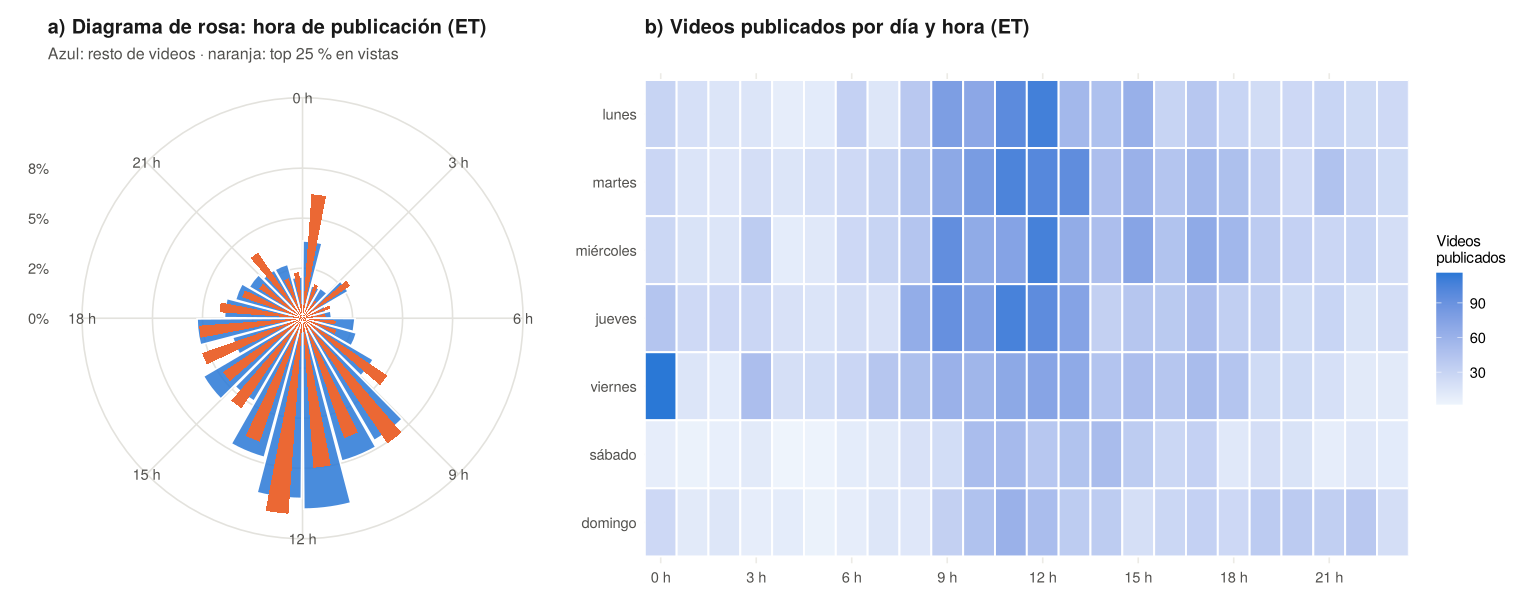

In [40]:
rosa <- d_tiempo %>% mutate(h = floor(hora_pub), Grupo = if_else(vistas >= quantile(vistas, 0.75), "Top 25 % en vistas", "Resto")) %>%
  count(Grupo, h) %>% group_by(Grupo) %>% mutate(p = n / sum(n)) %>% ungroup()
r1 <- ggplot(rosa %>% filter(Grupo == "Resto"), aes(h + 0.5, p)) +
  geom_col(width = 0.95, fill = AZUL, alpha = 0.85, colour = "white") +
  geom_col(data = rosa %>% filter(Grupo == "Top 25 % en vistas"), width = 0.45, fill = NARANJA) +
  coord_polar(start = 0) + scale_x_continuous(limits = c(0, 24), breaks = seq(0, 21, 3), labels = paste0(seq(0, 21, 3), " h")) +
  scale_y_continuous(labels = label_percent(accuracy = 1)) +
  labs(title = "a) Diagrama de rosa: hora de publicación (ET)", subtitle = "Azul: resto de videos · naranja: top 25 % en vistas", x = NULL, y = NULL) +
  theme(panel.grid.major = element_line(colour = "#e3e2dd"))
heat <- d_tiempo %>% mutate(h = floor(hora_pub)) %>% group_by(dia_pub, h) %>% summarise(n = n(), med = median(vistas), .groups = "drop")
r2 <- ggplot(heat, aes(h, fct_rev(dia_pub), fill = n)) + geom_tile(colour = "white", linewidth = 0.6) +
  scale_fill_gradient(low = "#eef4fc", high = AZUL, name = "Videos\npublicados") +
  scale_x_continuous(breaks = seq(0, 23, 3), labels = paste0(seq(0, 23, 3), " h"), expand = c(0, 0)) +
  labs(title = "b) Videos publicados por día y hora (ET)", x = NULL, y = NULL) + theme(panel.grid = element_blank(), legend.position = "right")
options(repr.plot.width = 14, repr.plot.height = 5.5); r1 + r2 + plot_layout(widths = c(1, 1.5))
guardar(r1 + r2 + plot_layout(widths = c(1, 1.5)), "15_hora_publicacion", 14, 5.5)

**Lectura.** La publicación se concentra entre las **9 y las 14 h ET de lunes a jueves**, el horario laboral de la costa este. Hay un pico muy marcado el **viernes a las 0 h**, que corresponde a los lanzamientos musicales (la industria estrena música nueva los viernes a medianoche) y explica la barra naranja de la medianoche en el diagrama de rosa. Los fines de semana se publica mucho menos.

Prueba,H,p,ε² (tamaño del efecto)
<chr>,<chr>,<chr>,<chr>
Vistas según día de publicación,"43,2","< 0,001","0,0069"
Likes/vista según día,"33,2","< 0,001","0,0053"
Días en tendencia según día,"8,5","0,201","0,0014"
Vistas según franja horaria,"10,3","0,016","0,0016"


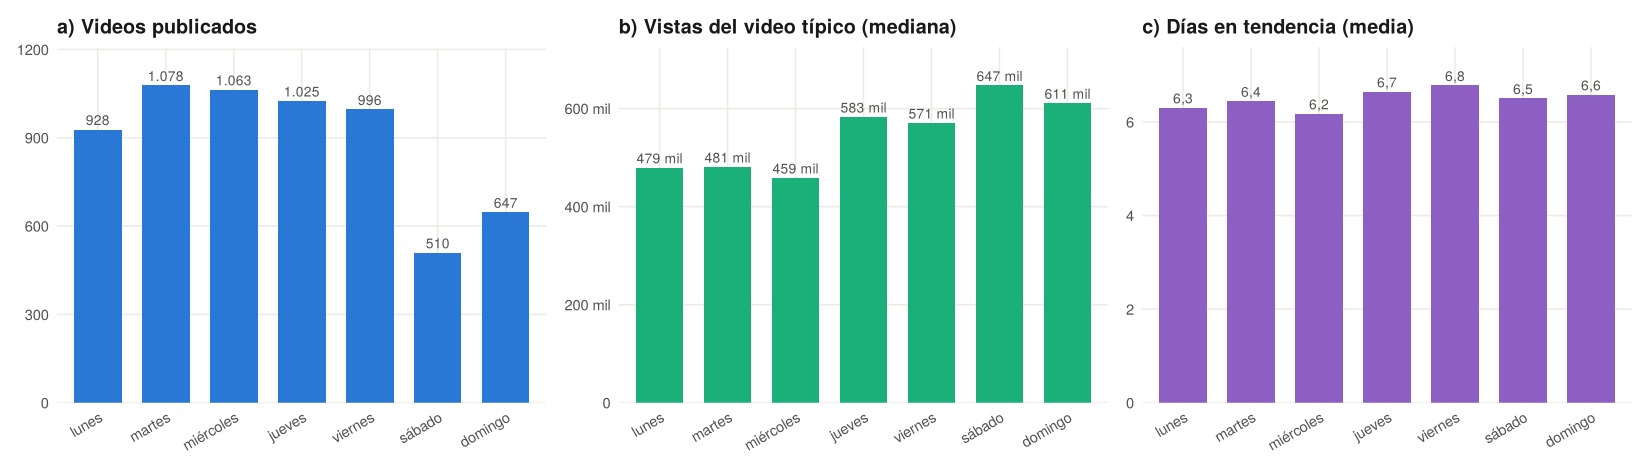

In [41]:
# Pruebas de Kruskal-Wallis por día y franja horaria
kw_dia <- kruskal.test(log10(vistas) ~ dia_pub, data = d_tiempo); kw_franja <- kruskal.test(log10(vistas) ~ franja, data = d_tiempo)
kw_dia_l <- kruskal.test(tasa_likes ~ dia_pub, data = d_tiempo); kw_dias_t <- kruskal.test(dias_tendencia ~ dia_pub, data = d_tiempo)
eps <- function(k, n) unname(k$statistic) / (n - 1)
tibble(Prueba = c("Vistas según día de publicación", "Likes/vista según día", "Días en tendencia según día", "Vistas según franja horaria"),
       H = num(c(kw_dia$statistic, kw_dia_l$statistic, kw_dias_t$statistic, kw_franja$statistic), 1),
       p = pval(c(kw_dia$p.value, kw_dia_l$p.value, kw_dias_t$p.value, kw_franja$p.value)),
       `ε² (tamaño del efecto)` = num(c(eps(kw_dia, nrow(d_tiempo)), eps(kw_dia_l, nrow(d_tiempo)), eps(kw_dias_t, nrow(d_tiempo)), eps(kw_franja, nrow(d_tiempo))), 4))

dia_res <- d_tiempo %>% group_by(dia_pub) %>% summarise(Videos = n(), med_vistas = median(vistas), dias = mean(dias_tendencia), horas = median(horas_a_tendencia))
d1 <- ggplot(dia_res, aes(dia_pub, Videos)) + geom_col(fill = AZUL, width = 0.7) + geom_text(aes(label = num(Videos)), vjust = -0.4, size = 3.2, colour = TINTA) +
  scale_y_continuous(expand = expansion(mult = c(0, .12))) + labs(title = "a) Videos publicados", x = NULL, y = NULL)
d2 <- ggplot(dia_res, aes(dia_pub, med_vistas)) + geom_col(fill = AQUA, width = 0.7) + geom_text(aes(label = lab_corta(med_vistas)), vjust = -0.4, size = 3.2, colour = TINTA) +
  scale_y_continuous(labels = lab_corta, expand = expansion(mult = c(0, .12))) + labs(title = "b) Vistas del video típico (mediana)", x = NULL, y = NULL)
d3 <- ggplot(dia_res, aes(dia_pub, dias)) + geom_col(fill = MORADO, width = 0.7) + geom_text(aes(label = num(dias, 1)), vjust = -0.4, size = 3.2, colour = TINTA) +
  scale_y_continuous(expand = expansion(mult = c(0, .12))) + labs(title = "c) Días en tendencia (media)", x = NULL, y = NULL)
options(repr.plot.width = 15, repr.plot.height = 4.3); (d1 + d2 + d3) & theme(axis.text.x = element_text(angle = 30, hjust = 1))
guardar((d1 + d2 + d3) & theme(axis.text.x = element_text(angle = 30, hjust = 1)), "16_dia_semana", 15, 4.3)

**Lectura.** El día de publicación tiene un efecto **estadísticamente significativo pero prácticamente despreciable**: explica menos del 1 % de la variabilidad de las vistas (ε² = 0,007) y no cambia los días en tendencia (p = 0,20). Los videos de sábado y domingo tienen una mediana algo mayor (unas 610.000 a 650.000 vistas, frente a 460.000 a 480.000 de lunes a miércoles), probablemente porque **hay menos competencia**: ese día se publican la mitad de videos. Es una oportunidad táctica, no un factor decisivo.

### 6.1 Serie de tiempo diaria de la lista de tendencias

Se construyen dos series diarias a partir de las capturas: (a) el **número de videos nuevos** que entran a tendencia cada día y (b) la **mediana de vistas** de esos videos al entrar, en escala log. Los días sin dato se imputan con `na.interp` solo para poder ajustar los modelos, y se marcan en el gráfico. Como la serie tiene frecuencia 7, `na.interp` usa un método estacional: descompone la serie con STL robusta, interpola linealmente la serie desestacionalizada y le vuelve a sumar el componente semanal, de modo que el valor imputado respeta el día de la semana. La frecuencia de la serie es 7, para capturar un posible ciclo semanal.

In [42]:
nuevos <- videos %>% filter(primera_tendencia > fecha_ini) %>% group_by(fecha = primera_tendencia) %>%
  summarise(nuevos = n(), med_log_vistas = median(log10(vistas_ini)))
serie <- tibble(fecha = seq(fecha_ini + 1, fecha_fin, by = "day")) %>% left_join(nuevos, by = "fecha") %>%
  mutate(imputado = is.na(nuevos) | !(fecha %in% unique(limpio$fecha_tendencia)))
y_nuevos <- na.interp(ts(if_else(serie$imputado, NA_real_, serie$nuevos), frequency = 7))
y_vistas <- na.interp(ts(if_else(serie$imputado, NA_real_, serie$med_log_vistas), frequency = 7))
serie <- serie %>% mutate(nuevos_i = as.numeric(y_nuevos), vistas_i = as.numeric(y_vistas))
cat("Días en la serie:", nrow(serie), "| Días imputados:", sum(serie$imputado), "| Videos nuevos por día (mediana):", median(serie$nuevos, na.rm = TRUE), "\n")

stl_n <- stl(y_nuevos, s.window = "periodic", robust = TRUE); stl_v <- stl(y_vistas, s.window = "periodic", robust = TRUE)
fuerza_est <- function(s) { r <- s$time.series[, "remainder"]; sz <- s$time.series[, "seasonal"]; max(0, 1 - var(r) / var(r + sz)) }
fuerza_tend <- function(s) { r <- s$time.series[, "remainder"]; tr <- s$time.series[, "trend"]; max(0, 1 - var(r) / var(r + tr)) }
tibble(Serie = c("Videos nuevos por día", "Mediana de vistas al entrar (log)"),
       `Fuerza de la estacionalidad semanal (0-1)` = num(c(fuerza_est(stl_n), fuerza_est(stl_v)), 2),
       `Fuerza de la tendencia (0-1)` = num(c(fuerza_tend(stl_n), fuerza_tend(stl_v)), 2))

Días en la serie: 212 | Días imputados: 9 | Videos nuevos por día (mediana): 24 


Serie,Fuerza de la estacionalidad semanal (0-1),Fuerza de la tendencia (0-1)
<chr>,<chr>,<chr>
Videos nuevos por día,"0,14","0,51"
Mediana de vistas al entrar (log),"0,06","0,77"


**Lectura.** La serie tiene 9 días imputados: los 8 sin captura (10 y 11 de enero; 8 a 13 de abril) y el 14 de marzo, día con captura pero sin ningún video nuevo registrado. La **estacionalidad semanal es débil** (fuerza de 0,14 en el número de videos nuevos y de 0,06 en sus vistas), mientras que la **tendencia es fuerte** (0,51 y 0,77).

In [43]:
set.seed(SEMILLA)
n_tr <- nrow(serie) - 14                                   # últimas 14 observaciones como conjunto de prueba
ajuste <- function(y) {
  ytr <- window(y, end = time(y)[n_tr]); yte <- window(y, start = time(y)[n_tr + 1])
  m_sar <- auto.arima(ytr, seasonal = TRUE, stepwise = FALSE, approximation = FALSE)
  m_ar  <- auto.arima(ytr, seasonal = FALSE, stepwise = FALSE, approximation = FALSE)
  m_sn  <- snaive(ytr, h = 14)
  f_sar <- forecast(m_sar, h = 14); f_ar <- forecast(m_ar, h = 14)
  list(modelo = m_sar, tabla = tibble(Modelo = c(paste("SARIMA:", str_remove(as.character(m_sar), "ARIMA")), paste("ARIMA sin estacionalidad:", str_remove(as.character(m_ar), "ARIMA")), "Ingenuo estacional (misma día semana anterior)"),
       AICc = c(m_sar$aicc, m_ar$aicc, NA), `RMSE prueba (14 días)` = c(accuracy(f_sar, yte)[2, "RMSE"], accuracy(f_ar, yte)[2, "RMSE"], accuracy(m_sn, yte)[2, "RMSE"]),
       `Ljung-Box p (residuos)` = c(Box.test(residuals(m_sar), lag = 14, type = "Ljung-Box", fitdf = length(coef(m_sar)))$p.value,
                                     Box.test(residuals(m_ar), lag = 14, type = "Ljung-Box", fitdf = length(coef(m_ar)))$p.value, NA)))
}
aj_n <- ajuste(y_nuevos); aj_v <- ajuste(y_vistas)
bind_rows(aj_n$tabla %>% mutate(Serie = "Videos nuevos/día"), aj_v$tabla %>% mutate(Serie = "Vistas al entrar (log)")) %>% relocate(Serie) %>%
  mutate(AICc = num(AICc, 1), `RMSE prueba (14 días)` = num(`RMSE prueba (14 días)`, 3), `Ljung-Box p (residuos)` = num(`Ljung-Box p (residuos)`, 3))

Serie,Modelo,AICc,RMSE prueba (14 días),Ljung-Box p (residuos)
<chr>,<chr>,<chr>,<chr>,<chr>
Videos nuevos/día,"SARIMA: (1,1,1)(1,0,1)[7]","1.634,0","8,206","0,763"
Videos nuevos/día,"ARIMA sin estacionalidad: (1,1,1)","1.653,0","9,432","0,001"
Videos nuevos/día,Ingenuo estacional (misma día semana anterior),NA,"7,783",NA
Vistas al entrar (log),"SARIMA: (3,1,1)(1,0,0)[7] with drift","-87,7","0,163","0,624"
Vistas al entrar (log),"ARIMA sin estacionalidad: (0,1,4) with drift","-86,6","0,161","0,418"
Vistas al entrar (log),Ingenuo estacional (misma día semana anterior),NA,"0,157",NA


**Lectura.** Para el número de videos nuevos por día, el **SARIMA(1,1,1)(1,0,1)₇** mejora al ARIMA sin estacionalidad (AICc de 1.634 frente a 1.653; error de 8,2 frente a 9,4 videos) y deja residuos sin autocorrelación (Ljung-Box p = 0,76, frente a 0,001 del modelo no estacional). Por lo tanto, **sí existe un ciclo semanal en la lista**: entran más videos nuevos los viernes (38,9 en promedio) y menos los domingos (20,7). En cambio, las vistas con que entran los videos no tienen estacionalidad útil: los tres modelos tienen un error prácticamente igual. El modelo ingenuo estacional (repetir el valor del mismo día de la semana anterior) obtiene incluso un error algo menor en la prueba (7,8 videos). Esto confirma el ciclo semanal y muestra que el pronóstico de corto plazo de esta serie tiene un techo bajo: un modelo más complejo no lo supera de forma clara.

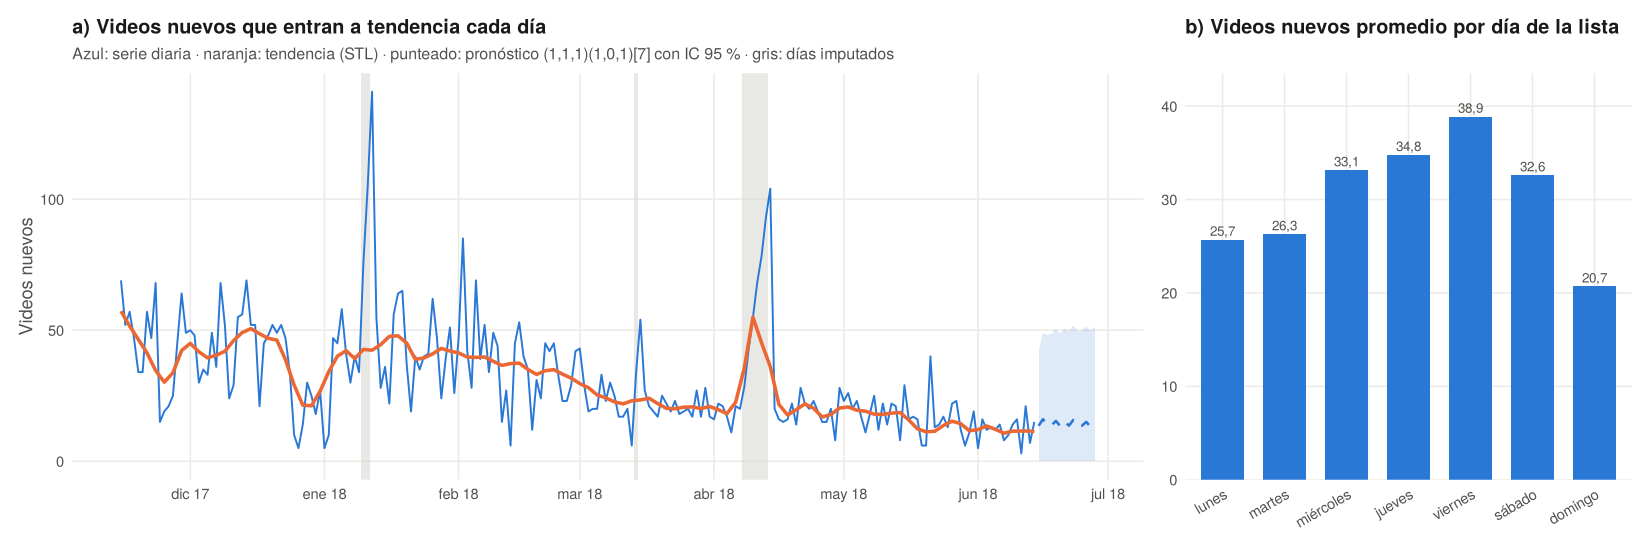

In [44]:
m_final <- auto.arima(y_nuevos, seasonal = TRUE, stepwise = FALSE, approximation = FALSE)
fc <- forecast(m_final, h = 14)
fc_df <- tibble(fecha = fecha_fin + 1:14, media = as.numeric(fc$mean), lo = pmax(as.numeric(fc$lower[, 2]), 0), hi = as.numeric(fc$upper[, 2]))
semana <- serie %>% mutate(dia = factor(dias_es[wday(fecha, week_start = 1)], levels = dias_es)) %>% filter(!imputado) %>%
  group_by(dia) %>% summarise(nuevos = mean(nuevos), vistas = mean(med_log_vistas))
t1 <- ggplot(serie, aes(fecha, nuevos_i)) +
  geom_rect(data = serie %>% filter(imputado), aes(xmin = fecha - 0.5, xmax = fecha + 0.5, ymin = -Inf, ymax = Inf), fill = GRIS_CLARO, alpha = 0.6, inherit.aes = FALSE) +
  geom_line(colour = AZUL, linewidth = 0.6) +
  geom_line(aes(y = as.numeric(stl_n$time.series[, "trend"])), colour = NARANJA, linewidth = 1.1) +
  geom_ribbon(data = fc_df, aes(x = fecha, ymin = lo, ymax = hi), fill = AZUL, alpha = 0.15, inherit.aes = FALSE) +
  geom_line(data = fc_df, aes(fecha, media), colour = AZUL, linetype = "dashed", linewidth = 0.8) +
  scale_x_date(date_breaks = "1 month", labels = function(d) paste(meses_es[month(d)], format(d, "%y"))) +
  labs(title = "a) Videos nuevos que entran a tendencia cada día",
       subtitle = paste0("Azul: serie diaria · naranja: tendencia (STL) · punteado: pronóstico ", str_remove(as.character(m_final), "ARIMA"), " con IC 95 % · gris: días imputados"),
       x = NULL, y = "Videos nuevos")
t2 <- semana %>% ggplot(aes(dia, nuevos)) + geom_col(fill = AZUL, width = 0.7) + geom_text(aes(label = num(nuevos, 1)), vjust = -0.4, size = 3.1, colour = TINTA) +
  scale_y_continuous(expand = expansion(mult = c(0, .12))) +
  labs(title = "b) Videos nuevos promedio por día de la lista", x = NULL, y = NULL) + theme(axis.text.x = element_text(angle = 30, hjust = 1))
options(repr.plot.width = 15, repr.plot.height = 5); t1 + t2 + plot_layout(widths = c(2.4, 1))
guardar(t1 + t2 + plot_layout(widths = c(2.4, 1)), "17_serie_tiempo", 15, 5)

**Lectura.** La serie muestra una **tendencia decreciente**: de unos 45 videos nuevos por día en diciembre de 2017 se pasa a unos 15 en junio de 2018. Los dos picos (enero y abril) aparecen justo después de los huecos de captura y son un artefacto: los videos que entraron durante los días sin datos se registran como "nuevos" el primer día con captura. El pronóstico SARIMA para las dos semanas siguientes es de unos 14 videos nuevos por día.

In [45]:
# Comparación por mes de publicación
mes_res <- d_tiempo %>% filter(mes_pub >= as.Date("2017-11-01")) %>% group_by(mes_pub) %>%
  summarise(Videos = n(), `Mediana vistas` = median(vistas), `Likes / 100 vistas` = 100 * median(tasa_likes, na.rm = TRUE), `Días en tendencia` = mean(dias_tendencia))
kw_mes <- kruskal.test(log10(vistas) ~ factor(mes_pub), data = d_tiempo %>% filter(mes_pub >= as.Date("2017-11-01")))
cat("Kruskal-Wallis vistas por mes: H =", num(kw_mes$statistic, 1), "|", p_txt(kw_mes$p.value), "|", "ε² =", num(eps(kw_mes, sum(mes_res$Videos)), 4), "\n")
mes_res %>% mutate(Mes = paste(meses_es[month(mes_pub)], year(mes_pub)), .before = 1) %>% select(-mes_pub) %>%
  mutate(`Mediana vistas` = num(`Mediana vistas`), across(c(`Likes / 100 vistas`, `Días en tendencia`), ~ num(.x, 2)))

Kruskal-Wallis vistas por mes: H = 1.067,9 | p < 0,001 | ε² = 0,1711 


Mes,Videos,Mediana vistas,Likes / 100 vistas,Días en tendencia
<chr>,<int>,<chr>,<chr>,<chr>
nov 2017,961,311.117,"2,65","4,34"
dic 2017,1155,298.314,"2,75","5,31"
ene 2018,1265,328.687,"2,40","4,34"
feb 2018,991,393.170,"2,19","6,25"
mar 2018,673,839.162,"2,49","9,11"
abr 2018,530,1.188.774,"2,37","9,58"
may 2018,528,1.562.000,"2,31","12,43"
jun 2018,139,1.803.187,"2,56","5,35"


**Respuesta a P4.**

* **Hora:** sí hay un patrón (publicar entre las 9 y las 14 h ET entre semana es la norma), pero los videos de mayor alcance no se publican en una hora muy distinta. La hora es **un factor de higiene, no de éxito**: conviene publicar al inicio de la tarde ET para que el video tenga el día completo de la audiencia de EE. UU. y llegue a tendencia en menos de 24 horas.
* **Día:** el efecto es despreciable en el desempeño, aunque los fines de semana hay menos competencia.
* **Mes:** la diferencia aparente es enorme (ε² = 0,17; de 0,31 M de vistas de mediana en noviembre a 1,8 M en junio), pero **no es estacionalidad**. Coincide con la caída de videos nuevos por día y con el aumento de los días en tendencia (de 4,3 a 12,4). Desde marzo de 2018, la lista **rota menos** y retiene más tiempo a los mismos videos, que por eso acumulan más vistas. Es un cambio en el funcionamiento de la lista (o en la captura de los datos), no un efecto de la temporada. Con solo 7 meses de datos no se puede estimar la estacionalidad anual (Navidad, verano, *Black Friday*); para eso se necesitarían al menos 2 o 3 años.

## 7. P5 — ¿Es posible predecir cuántas vistas o *likes* tendrá un video?

**Diseño del experimento.** La respuesta depende de **en qué momento** se hace la predicción, así que se evalúan dos escenarios con las mismas técnicas:

| Escenario | Cuándo se predice | Variables | Uso para el negocio |
|---|---|---|---|
| **A. Antes de publicar** | Al planear el video | Categoría, hora y día, título (largo, mayúsculas, signos, palabras clave, sentimiento), etiquetas, descripción (enlaces, *sponsor*) y trayectoria previa del canal | Planear contenido propio y estimar el alcance de un *sponsor* antes de contratarlo |
| **B. Señal temprana** | El día en que el video entra a tendencia | Las de A más vistas, *likes*, comentarios y horas transcurridas al entrar a tendencia | Decidir si se amplifica un video (pauta o promoción cruzada) mientras está en tendencia |

* **Variable objetivo:** log₁₀ de las vistas finales (y, en paralelo, de los *likes* finales). Se usa el logaritmo porque los errores son multiplicativos: equivocarse en 100.000 vistas es grave para un video de 200.000, pero menor para uno de 20 millones.
* **Validación agrupada por canal:** el 80 % de los canales se usa para entrenar y el 20 % restante, que el modelo nunca vio, para probar. Así se evita que el modelo "memorice" canales y se mide cómo generaliza a canales nuevos, como el de la empresa. Los hiperparámetros se eligen con validación cruzada de 5 pliegues, también agrupada por canal, dentro del entrenamiento.
* **Modelos:** base (predice la media), regresión lineal múltiple, Elastic Net, *random forest*, XGBoost y una red neuronal (perceptrón multicapa con una capa oculta).
* **Métricas:** RMSE, MAE y R² en escala log₁₀, y dos métricas de negocio: el **error típico** (mediana del error porcentual en vistas) y el **% de videos predichos dentro de un factor de 2** (entre la mitad y el doble del valor real).

In [46]:
feat_A <- c("categoria", "hora_pub", "dia_pub", "largo_titulo", "palabras_titulo", "prop_mayus", "tiene_exclam", "tiene_pregunta", "tiene_numero", "tiene_emoji",
            "palabra_oficial", "palabra_trailer", "palabra_vs", "palabra_reaccion", "sentimiento", "n_etiquetas", "largo_desc", "n_enlaces",
            "menciona_sponsor", "enlaces_redes", "canal_previos", "canal_prev_suav")
feat_B <- c(feat_A, "log_vistas_ini", "log_likes_ini", "log_coment_ini", "log_horas_a_tend", "resurgido")
d_p5 <- videos %>% filter(!is.na(likes), likes > 0, !is.na(likes_ini), !is.na(comentarios_ini)) %>%
  mutate(y_vistas = log10(vistas), y_likes = log10(likes), log_vistas_ini = log10(vistas_ini), log_likes_ini = log10(likes_ini + 1),
         log_coment_ini = log10(comentarios_ini + 1), log_horas_a_tend = log10(horas_a_tendencia),
         categoria = factor(categoria), dia_pub = factor(dia_pub, ordered = FALSE), across(where(is.logical), as.numeric))
set.seed(SEMILLA)
canales <- unique(d_p5$canal); canales_te <- sample(canales, round(0.2 * length(canales)))
es_te <- d_p5$canal %in% canales_te
pliegue_canal <- setNames(sample(rep(1:5, length.out = length(setdiff(canales, canales_te)))), setdiff(canales, canales_te))
folds_tr <- pliegue_canal[d_p5$canal[!es_te]]
cat("Videos:", num(nrow(d_p5)), "| Entrenamiento:", num(sum(!es_te)), "videos de", num(length(canales) - length(canales_te)), "canales",
    "| Prueba:", num(sum(es_te)), "videos de", num(length(canales_te)), "canales nuevos\n")

Videos: 6.230 | Entrenamiento: 5.100 videos de 1.706 canales | Prueba: 1.130 videos de 426 canales nuevos


In [47]:
matriz <- function(feats) {
  X <- model.matrix(as.formula(paste("~", paste(feats, collapse = " + "))), data = d_p5)[, -1]
  list(tr = X[!es_te, ], te = X[es_te, ])
}
metr <- function(y, p, modelo) {
  e <- p - y
  tibble(Modelo = modelo, RMSE = sqrt(mean(e^2)), MAE = mean(abs(e)), R2 = 1 - sum(e^2) / sum((y - mean(y))^2),
         `Error típico` = median(abs(10^e - 1)), `Dentro de x2` = mean(abs(e) < log10(2)))
}
entrenar_todos <- function(feats, objetivo) {
  M <- matriz(feats); ytr <- d_p5[[objetivo]][!es_te]; yte <- d_p5[[objetivo]][es_te]
  mu <- colMeans(M$tr); sdv <- apply(M$tr, 2, sd); sdv[sdv == 0] <- 1
  Ztr <- scale(M$tr, mu, sdv); Zte <- scale(M$te, mu, sdv)
  pred <- list()
  pred$`Base (media)` <- rep(mean(ytr), length(yte))
  lmf <- lm(ytr ~ ., data = as.data.frame(M$tr)); pred$`Regresión lineal` <- suppressWarnings(predict(lmf, as.data.frame(M$te)))
  en <- cv.glmnet(Ztr, ytr, alpha = 0.5, foldid = folds_tr); pred$`Elastic Net` <- as.numeric(predict(en, Zte, s = "lambda.1se"))
  # Random forest: mtry elegido por error OOB
  rf_grid <- map_dfr(c(4, 8, 12), function(m) tibble(mtry = m, oob = ranger(x = M$tr, y = ytr, num.trees = 400, mtry = min(m, ncol(M$tr)), min.node.size = 5, seed = SEMILLA)$prediction.error))
  rf <- ranger(x = M$tr, y = ytr, num.trees = 600, mtry = rf_grid$mtry[which.min(rf_grid$oob)], min.node.size = 5, importance = "impurity", seed = SEMILLA, quantreg = TRUE, keep.inbag = TRUE)
  pred$`Random forest` <- predict(rf, M$te)$predictions
  # XGBoost: número de árboles por validación cruzada agrupada
  dtr <- xgb.DMatrix(M$tr, label = ytr)
  par_xgb <- list(objective = "reg:squarederror", eta = 0.05, max_depth = 5, subsample = 0.8, colsample_bytree = 0.8, min_child_weight = 5, nthread = 2)
  cvx <- xgb.cv(params = par_xgb, data = dtr, nrounds = 1500, folds = split(seq_along(folds_tr), folds_tr), early_stopping_rounds = 50, verbose = 0)
  n_best <- which.min(cvx$evaluation_log$test_rmse_mean)
  xg <- xgb.train(params = par_xgb, data = dtr, nrounds = n_best, verbose = 0)
  pred$XGBoost <- predict(xg, M$te)
  # Red neuronal (MLP, 1 capa oculta): tamaño y regularización por validación cruzada agrupada
  ymu <- mean(ytr); ysd <- sd(ytr)
  grid_nn <- expand_grid(size = c(5, 10), decay = c(0.1, 1))
  grid_nn$cv <- pmap_dbl(grid_nn, function(size, decay) mean(map_dbl(1:5, function(f) {
    i <- folds_tr != f; set.seed(SEMILLA)
    m <- nnet(Ztr[i, ], (ytr[i] - ymu) / ysd, size = size, decay = decay, linout = TRUE, maxit = 400, MaxNWts = 5000, trace = FALSE)
    sqrt(mean((predict(m, Ztr[!i, ]) * ysd + ymu - ytr[!i])^2)) })))
  mejor_nn <- grid_nn[which.min(grid_nn$cv), ]
  nn_pred <- purrr::map(1:5, function(s) { set.seed(SEMILLA + s)              # promedio de 5 redes con distinta semilla
    m <- nnet(Ztr, (ytr - ymu) / ysd, size = mejor_nn$size, decay = mejor_nn$decay, linout = TRUE, maxit = 400, MaxNWts = 5000, trace = FALSE)
    as.numeric(predict(m, Zte)) * ysd + ymu })
  pred$`Red neuronal (MLP)` <- Reduce(`+`, nn_pred) / 5
  list(metricas = imap_dfr(pred, ~ metr(yte, .x, .y)), pred = pred, y = yte, rf = rf, xgb = xg, M = M, nn = mejor_nn, n_xgb = n_best)
}
set.seed(SEMILLA)
resA <- entrenar_todos(feat_A, "y_vistas"); resB <- entrenar_todos(feat_B, "y_vistas")
resA_l <- entrenar_todos(feat_A, "y_likes"); resB_l <- entrenar_todos(feat_B, "y_likes")
cat("Hiperparámetros elegidos (vistas, escenario B): XGBoost", resB$n_xgb, "árboles; red neuronal con", resB$nn$size, "neuronas y decay =", num(resB$nn$decay, 1), "\n")

tabla_metr <- bind_rows(resA$metricas %>% mutate(Escenario = "A. Antes de publicar", Objetivo = "Vistas"),
                        resB$metricas %>% mutate(Escenario = "B. Señal temprana", Objetivo = "Vistas"),
                        resA_l$metricas %>% mutate(Escenario = "A. Antes de publicar", Objetivo = "Likes"),
                        resB_l$metricas %>% mutate(Escenario = "B. Señal temprana", Objetivo = "Likes"))
tabla_metr %>% relocate(Objetivo, Escenario) %>%
  mutate(across(c(RMSE, MAE, R2), ~ num(.x, 3)), across(c(`Error típico`, `Dentro de x2`), pct))

Hiperparámetros elegidos (vistas, escenario B): XGBoost 232 árboles; red neuronal con 5 neuronas y decay = 1,0 


Objetivo,Escenario,Modelo,RMSE,MAE,R2,Error típico,Dentro de x2
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Vistas,A. Antes de publicar,Base (media),"0,791","0,605","-0,003","77,0 %","33,8 %"
Vistas,A. Antes de publicar,Regresión lineal,"0,678","0,512","0,263","70,4 %","39,7 %"
Vistas,A. Antes de publicar,Elastic Net,"0,695","0,522","0,225","70,6 %","39,6 %"
Vistas,A. Antes de publicar,Random forest,"0,663","0,499","0,295","70,7 %","41,9 %"
Vistas,A. Antes de publicar,XGBoost,"0,658","0,495","0,306","69,1 %","41,2 %"
Vistas,A. Antes de publicar,Red neuronal (MLP),"0,664","0,498","0,294","71,5 %","41,4 %"
Vistas,B. Señal temprana,Base (media),"0,791","0,605","-0,003","77,0 %","33,8 %"
Vistas,B. Señal temprana,Regresión lineal,"0,249","0,170","0,901","29,4 %","86,2 %"
Vistas,B. Señal temprana,Elastic Net,"0,253","0,176","0,897","30,5 %","86,2 %"


**Lectura de los resultados (en canales que el modelo nunca vio):**

* **Escenario A, antes de publicar:** la predicción es **limitada**. El mejor modelo (XGBoost) explica el 31 % de la variabilidad de las vistas y el 40 % de la de los *likes*, y acierta dentro de un factor de 2 en el 41 % de los videos, frente al 34 % del modelo base. El error típico es de alrededor del 70 %. Es honesto decirlo: **con lo que se sabe antes de publicar no se puede predecir con precisión cuánto verá un video**, porque el éxito depende de factores que no están en los datos (calidad, novedad, algoritmo de recomendación, competencia del día). El modelo sí sirve para **ordenar** opciones (por ejemplo, comparar el alcance esperado de varios canales *sponsor*).
* **Escenario B, señal temprana:** la predicción es **muy buena**. XGBoost alcanza un **R² de 0,93 en vistas y de 0,97 en *likes***, con un error típico del 25 % en vistas y del 17 % en *likes*, y acierta dentro de un factor de 2 en el 89 % y el 94 % de los videos. Con los datos del primer día en tendencia es posible estimar cuánto acumulará el video y decidir si conviene invertir en amplificarlo.
* **Comparación de técnicas:** XGBoost y la red neuronal obtienen los mejores resultados en ambos escenarios, seguidos del *random forest*. La regresión lineal queda cerca (R² de 0,90 en el escenario B), lo que indica que la relación es casi lineal en escala logarítmica; si se prioriza la explicabilidad, es una alternativa razonable. La red neuronal no supera claramente a XGBoost, así que, con datos tabulares de este tamaño (unos 6.000 videos), **no se justifica un modelo de aprendizaje profundo** más complejo.

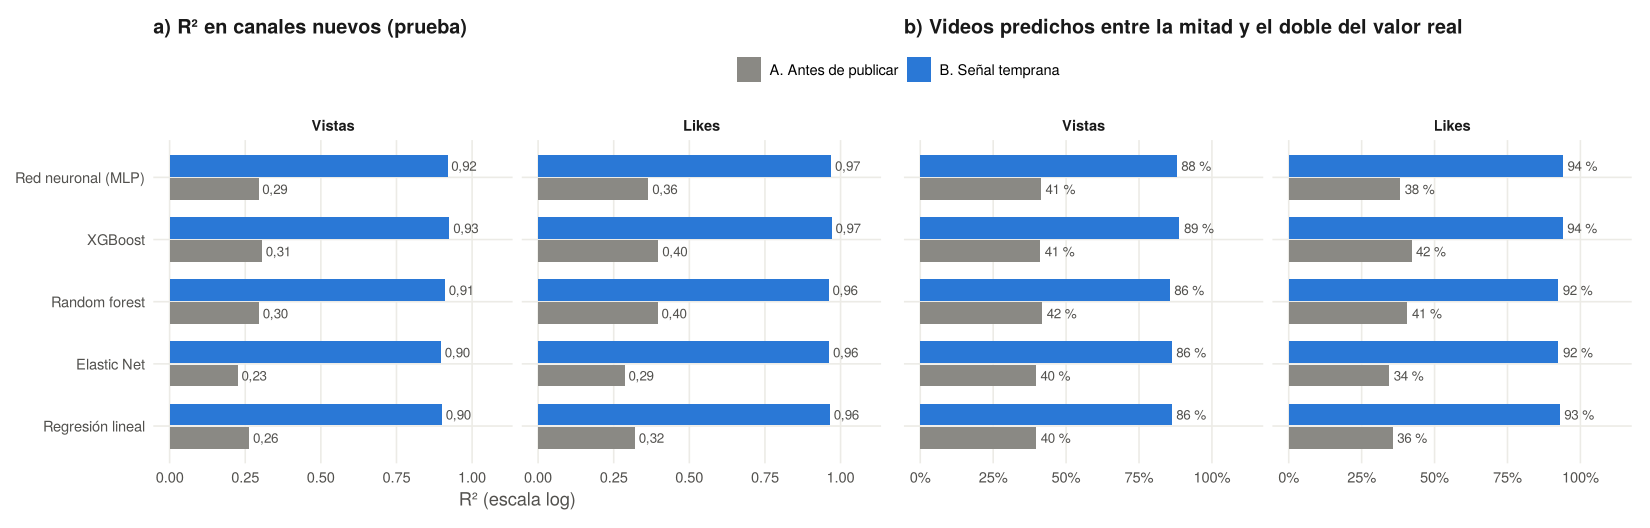

In [48]:
mm <- tabla_metr %>% filter(Modelo != "Base (media)") %>%
  mutate(Modelo = factor(Modelo, levels = c("Regresión lineal", "Elastic Net", "Random forest", "XGBoost", "Red neuronal (MLP)")),
         Objetivo = factor(Objetivo, levels = c("Vistas", "Likes")))
p_m1 <- ggplot(mm, aes(R2, Modelo, fill = Escenario)) + geom_col(position = position_dodge(width = 0.75), width = 0.7) +
  geom_text(aes(label = num(R2, 2)), position = position_dodge(width = 0.75), hjust = -0.15, size = 3.1, colour = TINTA) +
  facet_wrap(~ Objetivo) + scale_fill_manual(values = c(`A. Antes de publicar` = GRIS, `B. Señal temprana` = AZUL), name = NULL) +
  scale_x_continuous(limits = c(0, 1.08), breaks = seq(0, 1, .25)) + labs(title = "a) R² en canales nuevos (prueba)", x = "R² (escala log)", y = NULL)
p_m2 <- ggplot(mm, aes(`Dentro de x2`, Modelo, fill = Escenario)) + geom_col(position = position_dodge(width = 0.75), width = 0.7) +
  geom_text(aes(label = pct(`Dentro de x2`, 0)), position = position_dodge(width = 0.75), hjust = -0.15, size = 3.1, colour = TINTA) +
  facet_wrap(~ Objetivo) + scale_fill_manual(values = c(`A. Antes de publicar` = GRIS, `B. Señal temprana` = AZUL), name = NULL) +
  scale_x_continuous(labels = label_percent(), limits = c(0, 1.12), breaks = seq(0, 1, .25)) +
  labs(title = "b) Videos predichos entre la mitad y el doble del valor real", x = NULL, y = NULL) + theme(axis.text.y = element_blank())
options(repr.plot.width = 15, repr.plot.height = 4.8); (p_m1 + p_m2 + plot_layout(guides = "collect")) & theme(legend.position = "top")
guardar((p_m1 + p_m2 + plot_layout(guides = "collect")) & theme(legend.position = "top"), "18_metricas_modelos", 15, 4.8)

**Intervalos de predicción.** Para decidir conviene un rango más que un número exacto. El *random forest* de cuantiles (Meinshausen, 2006) estima, para cada video, el percentil 10 y el percentil 90 de las vistas esperadas. Se comprueba en la prueba que el intervalo del 80 % realmente contenga cerca del 80 % de los casos.

Escenario,Cobertura del intervalo 80 %,Ancho típico (P90/P10)
<chr>,<chr>,<chr>
A. Antes de publicar,"83,3 %","x43,2"
B. Señal temprana,"91,5 %","x4,5"


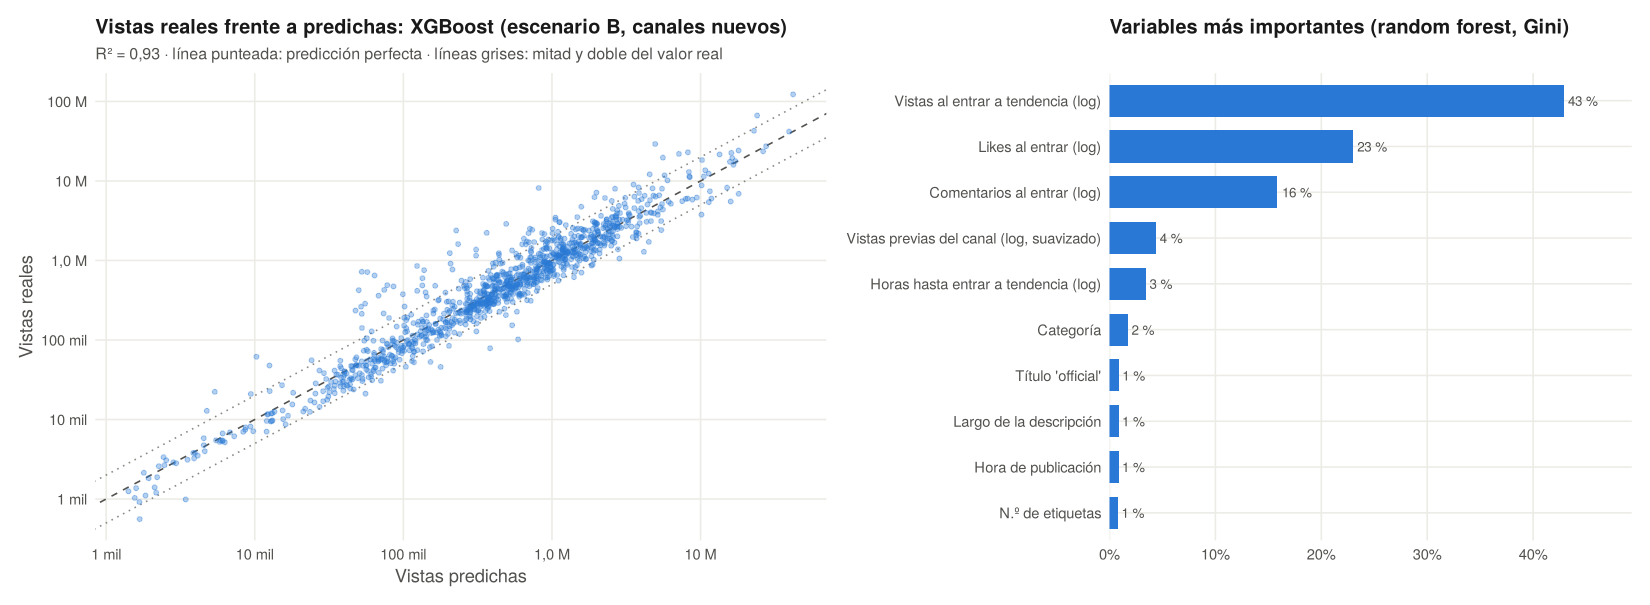

In [49]:
mejor_B <- resB$metricas %>% filter(Modelo != "Base (media)") %>% slice_max(R2, n = 1) %>% pull(Modelo)
q_B <- predict(resB$rf, resB$M$te, type = "quantiles", quantiles = c(0.1, 0.5, 0.9))$predictions
q_A <- predict(resA$rf, resA$M$te, type = "quantiles", quantiles = c(0.1, 0.5, 0.9))$predictions
cobertura <- function(q, y) mean(y >= q[, 1] & y <= q[, 3])
tibble(Escenario = c("A. Antes de publicar", "B. Señal temprana"),
       `Cobertura del intervalo 80 %` = pct(c(cobertura(q_A, resA$y), cobertura(q_B, resB$y))),
       `Ancho típico (P90/P10)` = paste0("x", num(c(median(10^(q_A[, 3] - q_A[, 1])), median(10^(q_B[, 3] - q_B[, 1]))), 1)))

pv <- tibble(real = resB$y, pred = resB$pred[[mejor_B]], lo = q_B[, 1], hi = q_B[, 3], categoria = d_p5$categoria[es_te])
p_pv <- ggplot(pv, aes(10^pred, 10^real)) +
  geom_abline(colour = TINTA, linetype = "dashed") +
  geom_abline(intercept = c(-log10(2), log10(2)), colour = GRIS, linetype = "dotted") +
  geom_point(colour = AZUL, alpha = 0.35, size = 1.2) +
  scale_x_log10(labels = lab_corta, breaks = 10^(3:8)) + scale_y_log10(labels = lab_corta, breaks = 10^(3:8)) +
  labs(title = paste0("Vistas reales frente a predichas: ", mejor_B, " (escenario B, canales nuevos)"),
       subtitle = paste0("R² = ", num(resB$metricas$R2[resB$metricas$Modelo == mejor_B], 2), " · línea punteada: predicción perfecta · líneas grises: mitad y doble del valor real"),
       x = "Vistas predichas", y = "Vistas reales")
imp_B <- tibble(var = names(resB$rf$variable.importance), imp = resB$rf$variable.importance) %>%
  mutate(var = str_remove(var, "TRUE$"), var = if_else(str_detect(var, "^categoria"), "categoria", var), var = if_else(str_detect(var, "^dia_pub"), "dia_pub", var)) %>%
  group_by(var) %>% summarise(imp = sum(imp)) %>% mutate(imp = imp / sum(imp)) %>% slice_max(imp, n = 10) %>%
  mutate(etiqueta = coalesce(c(etiquetas_var, log_likes_ini = "Likes al entrar (log)", log_coment_ini = "Comentarios al entrar (log)", palabras_titulo = "Palabras del título")[var], var),
         etiqueta = fct_reorder(etiqueta, imp))
p_impB <- ggplot(imp_B, aes(imp, etiqueta)) + geom_col(fill = AZUL, width = 0.7) + geom_text(aes(label = pct(imp, 0)), hjust = -0.15, size = 3.1, colour = TINTA) +
  scale_x_continuous(labels = label_percent(), expand = expansion(mult = c(0, .15))) +
  labs(title = "Variables más importantes (random forest, Gini)", x = NULL, y = NULL)
options(repr.plot.width = 15, repr.plot.height = 5.5); p_pv + p_impB + plot_layout(widths = c(1.4, 1))
guardar(p_pv + p_impB + plot_layout(widths = c(1.4, 1)), "19_prediccion_vistas", 15, 5.5)

**Lectura.** La cobertura de los intervalos del 80 % es adecuada (83 % en el escenario A y 92 % en el B; ligeramente conservadores). Su ancho muestra la diferencia de incertidumbre entre escenarios: **antes de publicar, el rango entre el percentil 10 y el 90 abarca un factor de 43** (por ejemplo, de 50.000 a 2 millones de vistas), mientras que **con la señal temprana se reduce a un factor de 4 a 5**. En el escenario B, las vistas, los *likes* y los comentarios al entrar a tendencia explican el 82 % de la importancia.

In [50]:
# Importancia de las variables en el escenario A (random forest, Gini)
tibble(var = names(resA$rf$variable.importance), imp = resA$rf$variable.importance) %>%
  mutate(var = str_remove(var, "TRUE$"), var = if_else(str_detect(var, "^categoria"), "categoria", var), var = if_else(str_detect(var, "^dia_pub"), "dia_pub", var)) %>%
  group_by(var) %>% summarise(imp = sum(imp)) %>% mutate(imp = imp / sum(imp)) %>% slice_max(imp, n = 8) %>%
  transmute(Variable = coalesce(c(etiquetas_var, palabras_titulo = "Palabras del título")[var], var), `Importancia (Gini)` = pct(imp))

Variable,Importancia (Gini)
<chr>,<chr>
"Vistas previas del canal (log, suavizado)","21,9 %"
Categoría,"9,7 %"
Largo de la descripción,"8,4 %"
Hora de publicación,"7,6 %"
N.º de etiquetas,"7,3 %"
% mayúsculas en título,"7,2 %"
Largo del título,"6,5 %"
N.º de enlaces en descripción,"5,7 %"


**Lectura.** Antes de publicar, la variable más importante con diferencia es la **trayectoria previa del canal** (22 %): un canal que ya tuvo videos con muchas vistas tiende a repetirlo. Le siguen la categoría, el largo de la descripción, la hora de publicación y las características del título. Para la elección de *sponsors* esto confirma que **el historial del canal es el mejor predictor disponible de su próximo resultado**, que es justo lo que resume el índice de la sección siguiente.

## 8. Métrica para elegir *sponsors*: Índice de Potencial de Retorno (IPR)

**Lógica de negocio.** Un *sponsor* (aquí, un canal en el que la empresa paga una mención o integración) genera retorno si cumple tres condiciones: (1) **exposición**, es decir, muchas personas ven el video y durante varios días; (2) **respuesta**, una audiencia que interactúa (*likes* y comentarios), que es la más propensa a hacer clic en un enlace hacia el sitio web; y (3) **confiabilidad**, un desempeño que se repite y no depende de un único video viral. El IPR combina cinco componentes, cada uno convertido a percentil (0 a 100) para que sean comparables:

| Componente | Medida | Peso | Por qué |
|---|---|---|---|
| Alcance | log₁₀ de vistas por video | 35 % | Tamaño de la audiencia expuesta |
| *Engagement* | (*likes* + comentarios) / vistas | 30 % | Propensión a actuar, el mejor indicador disponible de clics |
| Aprobación | *likes* / (*likes* + *dislikes*) | 15 % | Riesgo reputacional: una marca no quiere aparecer en contenido rechazado |
| Persistencia | días en tendencia por video | 10 % | Exposición sostenida |
| Frecuencia | número de videos distintos en tendencia | 10 % | Capacidad de llegar a tendencia de forma repetida |

**Componente bayesiano (promedio bayesiano empírico).** Un canal con 2 videos y un *engagement* altísimo puede deberse a la suerte. El promedio bayesiano **acerca cada canal a la media general en proporción a lo poco que se sabe de él**: con muchos videos se respeta su propio promedio y con pocos se "contrae" hacia la media. Formalmente, la estimación es un promedio ponderado entre la media del canal y la media global, con pesos n/σ² y 1/τ², donde σ² es la variabilidad entre videos de un mismo canal y τ² la variabilidad entre canales. Ambas se estiman con los datos. Solo se consideran canales con **al menos 3 videos en tendencia**.

In [51]:
# Promedio bayesiano empírico (modelo normal-normal) aplicado a una métrica por video
contraer <- function(valor, canal) {
  d <- tibble(valor, canal) %>% filter(is.finite(valor))
  por_c <- d %>% group_by(canal) %>% summarise(n = n(), media = mean(valor), var_w = var(valor))
  mu <- mean(d$valor)
  sigma2 <- weighted.mean(por_c$var_w[por_c$n >= 2], por_c$n[por_c$n >= 2] - 1)          # varianza dentro de canal (combinada)
  tau2 <- max(var(por_c$media[por_c$n >= 3]) - mean(sigma2 / por_c$n[por_c$n >= 3]), 1e-6)  # varianza entre canales (momentos)
  por_c %>% mutate(peso = (n / sigma2) / (n / sigma2 + 1 / tau2), contraida = peso * media + (1 - peso) * mu) %>%
    select(canal, n, media, peso, contraida) %>% structure(mu = mu, sigma2 = sigma2, tau2 = tau2)
}
v_sp <- videos %>% mutate(eng = (likes + comentarios) / vistas, l_eng = qlogis(pmin(pmax(eng, 1e-5), 0.999)),
                          l_aprob = qlogis(pmin(pmax(aprobacion, 0.01), 0.995)), l_vistas = log10(vistas))
c_alc <- contraer(v_sp$l_vistas, v_sp$canal); c_eng <- contraer(v_sp$l_eng, v_sp$canal)
c_apr <- contraer(v_sp$l_aprob, v_sp$canal); c_per <- contraer(v_sp$dias_tendencia, v_sp$canal)
tibble(Componente = c("Alcance (log vistas)", "Engagement (logit)", "Aprobación (logit)", "Persistencia (días)"),
       `Media global` = map_dbl(list(c_alc, c_eng, c_apr, c_per), ~ attr(.x, "mu")),
       `σ² dentro de canal` = map_dbl(list(c_alc, c_eng, c_apr, c_per), ~ attr(.x, "sigma2")),
       `τ² entre canales` = map_dbl(list(c_alc, c_eng, c_apr, c_per), ~ attr(.x, "tau2")),
       `Peso de un canal con 3 videos` = map_dbl(list(c_alc, c_eng, c_apr, c_per), ~ (3 / attr(.x, "sigma2")) / (3 / attr(.x, "sigma2") + 1 / attr(.x, "tau2")))) %>%
  mutate(across(where(is.numeric), ~ num(.x, 3)))

Componente,Media global,σ² dentro de canal,τ² entre canales,Peso de un canal con 3 videos
<chr>,<chr>,<chr>,<chr>,<chr>
Alcance (log vistas),"5,644","0,235","0,362","0,822"
Engagement (logit),"-3,673","0,191","0,573","0,900"
Aprobación (logit),"3,153","0,677","0,748","0,768"
Persistencia (días),"6,439","16,676","3,950","0,415"


**Lectura.** El peso indica cuánto se confía en el promedio propio del canal: con 3 videos, el 90 % de la estimación del *engagement* proviene del canal y el 10 % de la media general, porque el *engagement* varía poco entre los videos de un mismo canal (σ² = 0,19) y mucho entre canales (τ² = 0,57). En cambio, la persistencia varía mucho entre videos del mismo canal, así que con 3 videos solo se confía un 42 % en el canal. La contracción es mayor justo donde los datos son menos confiables.

In [52]:
cl_por_canal <- base_cl %>% count(canal, grupo) %>% group_by(canal) %>% slice_max(n, n = 1, with_ties = FALSE) %>% ungroup() %>%
  select(canal, grupo_pred = grupo)
ipr <- por_canal %>% select(canal, categoria, videos, vistas_tot, med_vistas) %>%
  inner_join(c_alc %>% select(canal, alcance = contraida), by = "canal") %>%
  inner_join(c_eng %>% select(canal, engagement = contraida), by = "canal") %>%
  inner_join(c_apr %>% select(canal, aprobacion = contraida), by = "canal") %>%
  inner_join(c_per %>% select(canal, persistencia = contraida), by = "canal") %>%
  left_join(videos %>% group_by(canal) %>% summarise(pct_sponsor = mean(menciona_sponsor), eng_bruto = median((likes + comentarios) / vistas, na.rm = TRUE)), by = "canal") %>%
  left_join(cl_por_canal, by = "canal") %>%
  filter(videos >= 3)
pctl <- function(x) 100 * (rank(x) - 1) / (length(x) - 1)
PESOS <- c(alcance = .35, engagement = .30, aprobacion = .15, persistencia = .10, frecuencia = .10)
calc_ipr <- function(d, w) with(d, w["alcance"] * pctl(alcance) + w["engagement"] * pctl(engagement) + w["aprobacion"] * pctl(aprobacion) +
                                   w["persistencia"] * pctl(persistencia) + w["frecuencia"] * pctl(log(videos)))
ipr <- ipr %>% mutate(IPR = calc_ipr(ipr, PESOS)) %>% arrange(desc(IPR)) %>% mutate(puesto = row_number())
cat("Canales elegibles (≥ 3 videos en tendencia):", nrow(ipr), "\n")
ipr %>% slice_head(n = 20) %>%
  transmute(`#` = puesto, Canal = canal, Categoría = categoria, Videos = videos, `Vistas/video (bayes)` = num(10^alcance),
            `Engagement (bayes)` = pct(plogis(engagement), 2), `Aprobación (bayes)` = pct(plogis(aprobacion)), `Días en tendencia` = num(persistencia, 1),
            `Grupo predominante` = grupo_pred, `% videos con mención sponsor` = pct(pct_sponsor, 0), IPR = num(IPR, 1))

Canales elegibles (≥ 3 videos en tendencia): 517 


#,Canal,Categoría,Videos,Vistas/video (bayes),Engagement (bayes),Aprobación (bayes),Días en tendencia,Grupo predominante,% videos con mención sponsor,IPR
<int>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<chr>
1,ibighit,Music,9,15.614.212,"11,70 %","98,9 %","8,1",Virales masivos,0 %,"94,9"
2,SMTOWN,Music,11,3.698.131,"9,44 %","98,9 %","6,5",Virales masivos,0 %,"89,2"
3,NikkieTutorials,Howto & Style,12,2.057.815,"7,76 %","98,6 %","8,4",Virales masivos,100 %,"88,7"
4,BANGTANTV,Music,4,3.340.336,"12,04 %","99,3 %","8,0",Virales masivos,0 %,"88,6"
5,Jaiden Animations,Film & Animation,5,2.749.252,"7,86 %","98,6 %","8,5",Virales masivos,0 %,"87,5"
6,Liza Koshy,Comedy,6,3.819.104,"7,79 %","98,7 %","7,1",Virales masivos,17 %,"87,1"
7,nigahiga,Entertainment,7,3.831.671,"5,98 %","98,1 %","10,3",Virales masivos,14 %,"87,0"
8,Kurzgesagt – In a Nutshell,Education,9,2.476.093,"6,09 %","98,1 %","10,7",Virales masivos,0 %,"86,7"
9,Domics,Comedy,7,2.149.400,"6,14 %","98,5 %","10,3",Virales masivos,29 %,"86,4"


**Lectura.** De los 2.198 canales, 517 tienen al menos 3 videos en tendencia y son elegibles. Los primeros puestos combinan millones de vistas por video con un *engagement* de 5 % a 12 % (la media es de 2,5 %) y una aprobación cercana al 99 %. Predominan los creadores de *Music*, *Comedy*, *Howto & Style* y *Entertainment*. Casi todos pertenecen al grupo de comportamiento *Virales masivos*, lo que confirma que el índice premia el alcance acompañado de interacción.

**Robustez del índice.** Los pesos son una decisión de negocio. Para comprobar que la lista de candidatos no depende de ellos, se recalcula el IPR con tres esquemas alternativos y se mide (a) la correlación de Spearman entre rankings y (b) cuántos de los 20 primeros se mantienen.

In [53]:
esquemas <- list(`Pesos iguales` = c(alcance = .2, engagement = .2, aprobacion = .2, persistencia = .2, frecuencia = .2),
                 `Prioriza alcance` = c(alcance = .55, engagement = .20, aprobacion = .10, persistencia = .10, frecuencia = .05),
                 `Prioriza engagement` = c(alcance = .20, engagement = .50, aprobacion = .15, persistencia = .10, frecuencia = .05))
top20 <- head(ipr$canal, 20)
imap_dfr(esquemas, function(w, nombre) { alt <- calc_ipr(ipr, w)
  tibble(Esquema = nombre, `ρ de Spearman con el IPR base` = num(cor(alt, ipr$IPR, method = "spearman"), 3),
         `Top 20 que se mantiene` = paste0(sum(ipr$canal[order(-alt)][1:20] %in% top20), " de 20")) })

Esquema,ρ de Spearman con el IPR base,Top 20 que se mantiene
<chr>,<chr>,<chr>
Pesos iguales,"0,969",17 de 20
Prioriza alcance,"0,947",16 de 20
Prioriza engagement,"0,926",17 de 20


**Lectura.** El ranking es **robusto**: con cualquiera de los tres esquemas alternativos, la correlación con el ranking base es de al menos 0,93 y se mantienen entre 16 y 17 de los 20 primeros. Los candidatos no dependen de una elección arbitraria de pesos.

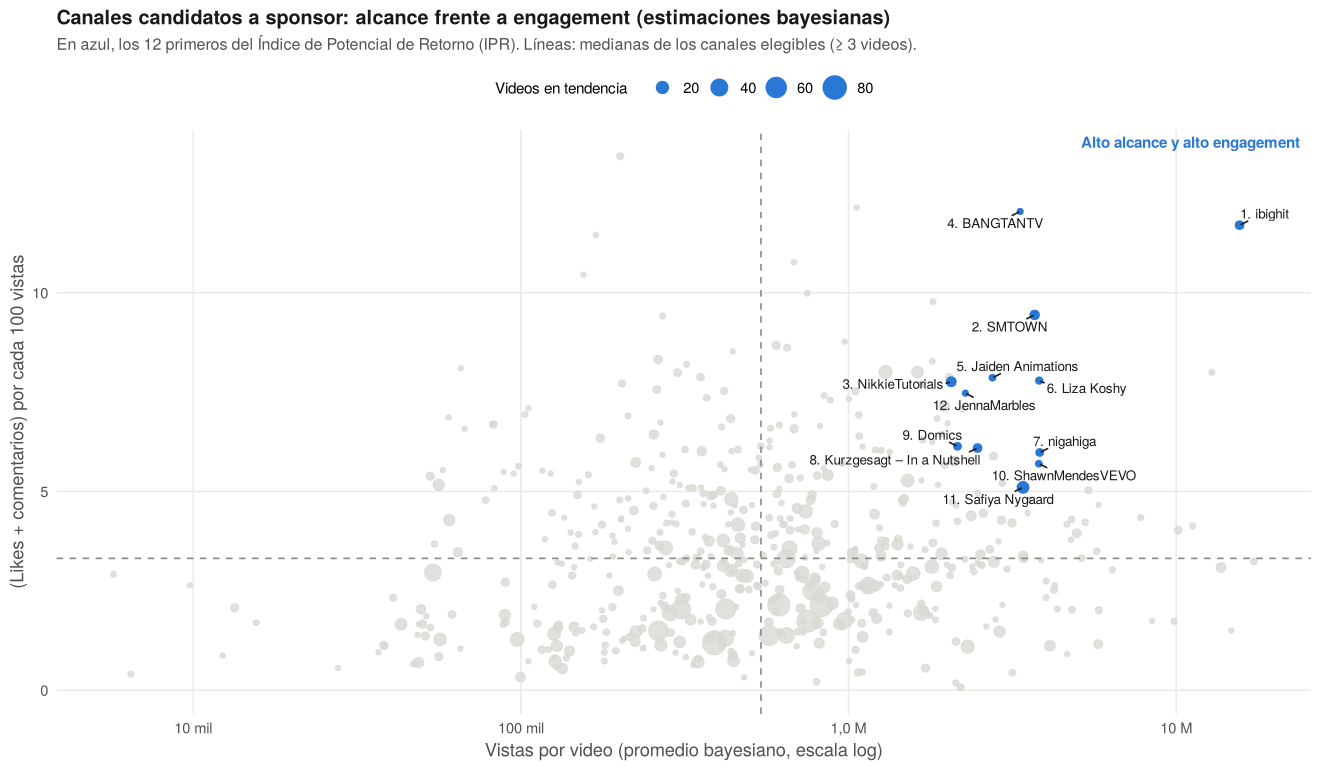

In [54]:
lab_top <- ipr %>% slice_head(n = 12)
p_ipr <- ggplot(ipr, aes(10^alcance, 100 * plogis(engagement))) +
  geom_point(aes(size = videos), colour = GRIS_CLARO, alpha = 0.8) +
  geom_point(data = lab_top, aes(size = videos), colour = AZUL) +
  geom_text_repel(data = lab_top, aes(label = paste0(puesto, ". ", canal)), size = 3.1, colour = "#191919", seed = SEMILLA, max.overlaps = 30, min.segment.length = 0) +
  geom_hline(yintercept = 100 * plogis(median(ipr$engagement)), colour = GRIS, linetype = "dashed") +
  geom_vline(xintercept = 10^median(ipr$alcance), colour = GRIS, linetype = "dashed") +
  scale_x_log10(labels = lab_corta) + scale_size_area(max_size = 7, name = "Videos en tendencia") +
  annotate("text", x = Inf, y = Inf, hjust = 1.05, vjust = 1.5, label = "Alto alcance y alto engagement", colour = AZUL, size = 3.5, fontface = "bold") +
  labs(title = "Canales candidatos a sponsor: alcance frente a engagement (estimaciones bayesianas)",
       subtitle = "En azul, los 12 primeros del Índice de Potencial de Retorno (IPR). Líneas: medianas de los canales elegibles (≥ 3 videos).",
       x = "Vistas por video (promedio bayesiano, escala log)", y = "(Likes + comentarios) por cada 100 vistas")
options(repr.plot.width = 12, repr.plot.height = 7); p_ipr
guardar(p_ipr, "20_sponsors_ipr", 12, 7)

**Lectura.** Los 12 primeros canales están en el cuadrante superior derecho: tienen **más de 2 millones de vistas por video y entre 5 y 12 interacciones por cada 100 vistas, el doble o más de la mediana de los canales elegibles (3,3)**. Muchos canales de gran alcance (a la derecha, en gris) tienen un *engagement* inferior a la mediana: son buenos para la notoriedad de marca, pero menos para generar clics hacia el sitio web.

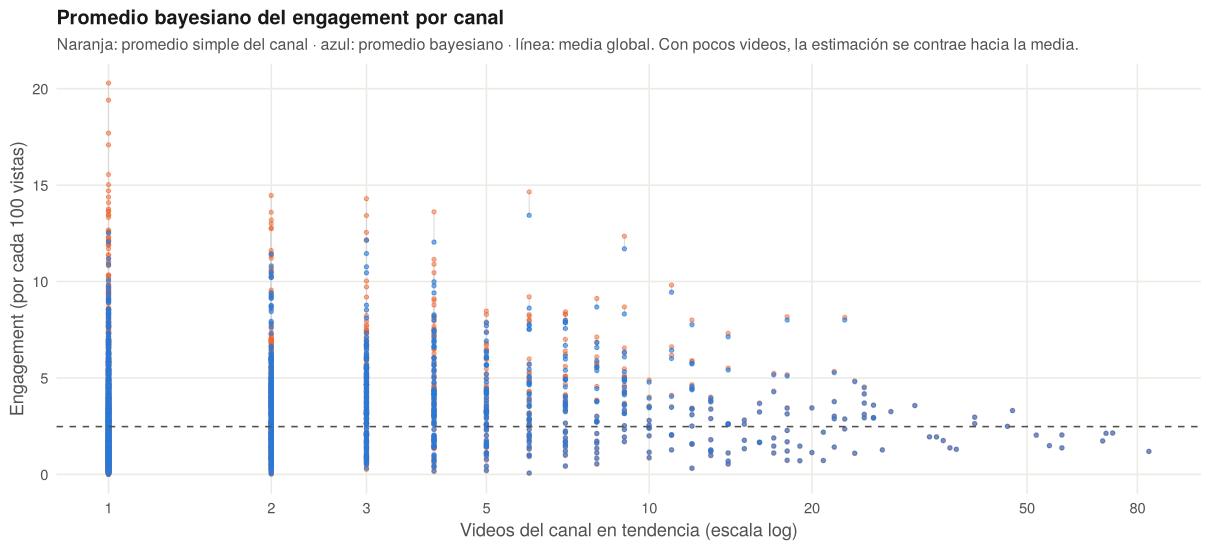

In [55]:
# Promedio simple frente a promedio bayesiano del engagement por canal
d_shr <- c_eng %>% filter(n >= 1) %>% mutate(bruto = 100 * plogis(media), bayes = 100 * plogis(contraida))
p_shr <- ggplot(d_shr, aes(n, bruto)) +
  geom_segment(aes(xend = n, yend = bayes), colour = GRIS_CLARO, linewidth = 0.3) +
  geom_point(colour = NARANJA, size = 1, alpha = 0.5) + geom_point(aes(y = bayes), colour = AZUL, size = 1, alpha = 0.6) +
  geom_hline(yintercept = 100 * plogis(attr(c_eng, "mu")), linetype = "dashed", colour = TINTA) +
  scale_x_log10(breaks = c(1, 2, 3, 5, 10, 20, 50, 80)) +
  labs(title = "Promedio bayesiano del engagement por canal", subtitle = "Naranja: promedio simple del canal · azul: promedio bayesiano · línea: media global. Con pocos videos, la estimación se contrae hacia la media.",
       x = "Videos del canal en tendencia (escala log)", y = "Engagement (por cada 100 vistas)")
options(repr.plot.width = 11, repr.plot.height = 5); p_shr
guardar(p_shr, "21_contraccion_bayes", 11, 5)
write_csv(ipr %>% transmute(puesto, canal, categoria, videos, vistas_por_video_bayes = round(10^alcance), engagement_bayes = plogis(engagement),
                            aprobacion_bayes = plogis(aprobacion), dias_tendencia_bayes = persistencia, grupo_predominante = grupo_pred,
                            pct_videos_con_sponsor = pct_sponsor, IPR = round(IPR, 2)), "out/ranking_sponsors_IPR.csv")

**¿Pierde *engagement* un video patrocinado?** Antes de recomendar *sponsors* conviene verificar que la audiencia no castigue el contenido patrocinado. Se compara la tasa de *likes* y la aprobación de los videos cuya descripción menciona patrocinio o enlaces de afiliados con la de los demás. Como la mención de *sponsor* es más común en unas categorías que en otras, se ajusta una regresión que controla la categoría y el alcance.

In [56]:
cmp_sp <- videos %>% filter(!is.na(tasa_likes), tasa_likes > 0) %>% group_by(Mención = if_else(menciona_sponsor, "Con mención de sponsor/afiliado", "Sin mención")) %>%
  summarise(Videos = n(), `Likes / 100 vistas` = 100 * median(tasa_likes), `Coment. / 100 vistas` = 100 * median(tasa_coment, na.rm = TRUE),
            `Aprobación` = median(aprobacion, na.rm = TRUE), `Mediana vistas` = median(vistas))
cmp_sp %>% mutate(across(c(`Likes / 100 vistas`, `Coment. / 100 vistas`), ~ num(.x, 2)), `Aprobación` = pct(`Aprobación`), `Mediana vistas` = num(`Mediana vistas`))
m_sp <- lm(log(tasa_likes) ~ menciona_sponsor + categoria + log10(vistas), data = videos %>% filter(!is.na(tasa_likes), tasa_likes > 0))
m_sp_a <- lm(qlogis(pmin(aprobacion, 0.999)) ~ menciona_sponsor + categoria + log10(vistas), data = videos %>% filter(!is.na(aprobacion), aprobacion > 0))
ef <- coef(summary(m_sp))["menciona_sponsorTRUE", ]; ci <- confint(m_sp)["menciona_sponsorTRUE", ]
ef_a <- coef(summary(m_sp_a))["menciona_sponsorTRUE", ]
cat("Efecto ajustado de mencionar sponsor sobre la tasa de likes:", paste0(ifelse(ef[1] > 0, "+", ""), pct(exp(ef[1]) - 1)),
    "[IC 95 %:", pct(exp(ci[1]) - 1), "a", pct(exp(ci[2]) - 1), "],", p_txt(ef[4]),
    "\nEfecto ajustado sobre la aprobación (logit):", num(ef_a[1], 3), "|", p_txt(ef_a[4]), "\n")

Mención,Videos,Likes / 100 vistas,Coment. / 100 vistas,Aprobación,Mediana vistas
<chr>,<int>,<chr>,<chr>,<chr>,<chr>
Con mención de sponsor/afiliado,676,"4,20","0,42","97,4 %",591.250
Sin mención,5638,"2,24","0,26","96,3 %",507.756


Efecto ajustado de mencionar sponsor sobre la tasa de likes: +68,8 % [IC 95 %: 56,8 % a 81,7 % ], p < 0,001 
Efecto ajustado sobre la aprobación (logit): 0,247 | p < 0,001 


**Lectura.** Los videos que mencionan patrocinio o enlaces de afiliados tienen **más** interacción, no menos: 4,2 frente a 2,2 *likes* por cada 100 vistas. Controlando la categoría y el alcance, la tasa de *likes* es un **69 % mayor** (IC 95 %: 57 % a 82 %) y la aprobación también es mayor. **No es un efecto causal**: los creadores que trabajan con marcas suelen ser *influencers* con comunidades leales. Pero sí descarta el temor de que la audiencia rechace el contenido patrocinado y respalda la estrategia de *sponsors*.

**Lista accionable.** Varios de los primeros puestos son sellos discográficos o canales oficiales de artistas (por ejemplo, ibighit, SMTOWN o los canales VEVO), que rara vez aceptan menciones de marcas externas. Como indicador de **receptividad**, se filtran los canales que ya incluyeron al menos una mención de patrocinio o afiliados en sus descripciones: ya trabajan con marcas y la negociación es más viable.

In [57]:
ipr %>% filter(pct_sponsor > 0) %>% slice_head(n = 15) %>%
  transmute(`# IPR` = puesto, Canal = canal, Categoría = categoria, Videos = videos, `Vistas/video (bayes)` = num(10^alcance),
            `Engagement (bayes)` = pct(plogis(engagement), 2), `Aprobación (bayes)` = pct(plogis(aprobacion)),
            `% videos con mención sponsor` = pct(pct_sponsor, 0), `Grupo predominante` = grupo_pred, IPR = num(IPR, 1))

# IPR,Canal,Categoría,Videos,Vistas/video (bayes),Engagement (bayes),Aprobación (bayes),% videos con mención sponsor,Grupo predominante,IPR
<int>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>
3,NikkieTutorials,Howto & Style,12,2.057.815,"7,76 %","98,6 %",100 %,Virales masivos,"88,7"
6,Liza Koshy,Comedy,6,3.819.104,"7,79 %","98,7 %",17 %,Virales masivos,"87,1"
7,nigahiga,Entertainment,7,3.831.671,"5,98 %","98,1 %",14 %,Virales masivos,"87,0"
9,Domics,Comedy,7,2.149.400,"6,14 %","98,5 %",29 %,Virales masivos,"86,4"
11,Safiya Nygaard,People & Blogs,18,3.408.214,"5,10 %","98,6 %",56 %,Virales masivos,"85,3"
12,JennaMarbles,Comedy,4,2.273.305,"7,47 %","98,4 %",25 %,Virales masivos,"85,0"
14,Rudy Mancuso,Comedy,8,2.769.693,"5,88 %","97,8 %",12 %,Virales masivos,"83,5"
15,JunsKitchen,Howto & Style,5,1.684.771,"6,30 %","98,9 %",100 %,Virales masivos,"83,4"
17,IISuperwomanII,Comedy,18,1.623.401,"8,00 %","98,7 %",6 %,Comunidad comprometida,"82,4"


## 9. Conclusiones y recomendaciones (CRISP-DM fase 6: despliegue)

### Respuestas a las preguntas

| Pregunta | Respuesta corta | Evidencia |
|---|---|---|
| **P1.** ¿Qué categorías reciben más vistas y *likes*? | *Music* domina el volumen (39 % de las vistas y 43 % de los *likes* con el 13 % de los videos). *Howto & Style*, *Music* y *Education* tienen el mayor *engagement*. *News & Politics* y *Sports* tienen audiencia, pero poca interacción. | Estadística descriptiva, Kruskal-Wallis (ε² = 0,07), elasticidad *likes*-vistas = 1,09 |
| **P2.** ¿Hay agrupaciones? | Sí, pero sobre un continuo. Hay dos ejes (volumen e interacción) y cuatro perfiles accionables: *Virales masivos*, *Comunidad comprometida*, *Alcance sin conexión* y *Bajo alcance*. Los perfiles **no** coinciden con las categorías (ARI = 0,03). | ACP (75 % con 3 CP), K-means con 5 criterios (estabilidad ARI = 0,87), ACM (79 % de inercia corregida en el eje 1), RF supervisado |
| **P3.** ¿Qué hace que un video sea tendencia y se sostenga? | La **señal temprana** (vistas al entrar y velocidad de llegada) pesa más que cualquier atributo del título o del horario. Los canales de actualidad diaria se sostienen menos; los lanzamientos "official", más. | RF con índice de Gini y permutación (AUC = 0,77), regresión logística (razones de momios) y árbol de reglas |
| **P4.** ¿Influye la fecha u hora? | Poco. Se publica sobre todo entre las 9 y las 14 h ET entre semana (Rayleigh, p < 0,001), pero el día explica menos del 1 % de las vistas. Hay un ciclo semanal en la lista (SARIMA). El aparente efecto del mes es un cambio en la rotación de la lista, no estacionalidad. | Estadística circular, Kruskal-Wallis, STL, SARIMA frente a ARIMA |
| **P5.** ¿Se pueden predecir vistas y *likes*? | **Antes de publicar, solo de forma aproximada** (R² = 0,31; útil para ordenar opciones). **Con la señal del primer día, sí** (R² = 0,93 en vistas y 0,97 en *likes*, en canales nuevos). | Seis modelos con validación agrupada por canal; XGBoost y MLP son los mejores; intervalos con *random forest* de cuantiles |
| **Sponsors** | El Índice de Potencial de Retorno (IPR), con promedios bayesianos, ordena 517 canales de forma robusta (ρ ≥ 0,93 ante cambios de pesos). El contenido patrocinado **no** pierde *engagement* (+69 % de *likes* por vista, ajustado). | Bayes empírico, análisis de sensibilidad, regresión ajustada |

### Recomendaciones para la empresa

**1. Posicionamiento del canal propio**
* **Formato:** contenido tipo *Howto & Style* o *Education* (tutoriales y explicaciones relacionados con el producto). Son las categorías con mayor *engagement* y la mayor proporción de videos en el grupo *Comunidad comprometida*, y en ellas un enlace al sitio web encaja de forma natural. Conviene evitar el formato de noticias o polémica: tiene baja interacción y la aprobación más baja.
* **Constancia más que viralidad:** el historial del canal es el principal predictor del alcance antes de publicar. Hay que construirlo con una frecuencia de publicación sostenida.
* **Lanzamiento:** publicar entre semana al inicio de la tarde (ET) y **concentrar toda la promoción propia (correo, redes y sitio web) en las primeras 24 a 48 horas**. Entrar a tendencia rápido y con 143.000 vistas o más eleva del 23 % al 59 % la probabilidad de mantenerse una semana.
* **Seguimiento:** usar el modelo del escenario B el día 1 para estimar el alcance final y decidir si se invierte en pauta para amplificar el video.

**2. Uso de *sponsors***
* **Sí conviene evaluarlos:** la evidencia no muestra rechazo de la audiencia al contenido patrocinado.
* **Cómo elegirlos:** priorizar con el IPR y, dentro del top, empezar por canales **receptivos** (que ya tienen menciones de marcas) y afines al producto. El ranking completo de los 517 canales elegibles incluye su puntaje y sus componentes.
* **Cómo decidir el pago:** el IPR ordena a los candidatos, pero el retorno depende del precio. Con la cotización de cada canal, calcular el **costo por interacción esperada** = precio / (vistas esperadas × *engagement* bayesiano) y elegir el menor.

**3. Medición del retorno real (siguiente paso).** Este análisis mide la interacción en YouTube, no los clics ni los negocios abiertos. Para cerrar el ciclo se propone un **diseño experimental**: enlaces con parámetros UTM únicos por *sponsor* y por video propio, una prueba piloto con 3 a 5 canales del top del IPR y una comparación del costo por sesión y por oportunidad comercial (*lead*) frente a la pauta tradicional. Con esos datos, el IPR se puede recalibrar para que sus pesos reflejen el retorno observado.

### Limitaciones
* Solo se observan los videos que **ya fueron tendencia** (sesgo de selección): los resultados describen qué distingue a los exitosos entre sí, no qué lleva a un video cualquiera a tendencia.
* El periodo es de 7 meses (noviembre de 2017 a junio de 2018): no permite estimar la estacionalidad anual, y los algoritmos de YouTube cambiaron desde entonces, así que los niveles deben actualizarse con datos recientes.
* No hay datos de clics, retención, ingresos ni precios de *sponsors*: el *engagement* es un indicador indirecto del retorno.
* El sentimiento se midió con un léxico en inglés; no capta sarcasmo ni contexto.

In [58]:
sessionInfo()$otherPkgs %>% names() %>% sort() %>% paste(collapse = ", ") %>% cat("Paquetes cargados:", ., "\n")
cat("Figuras guardadas:", length(list.files("fig")), "\n")

Paquetes cargados: circular, cluster, DBI, dplyr, FactoMineR, forcats, forecast, ggplot2, ggrepel, glmnet, jsonlite, lubridate, Matrix, mclust, nnet, patchwork, purrr, ranger, readr, RSQLite, scales, stringr, tibble, tidyr, tidytext, tidyverse, xgboost 


Figuras guardadas: 25 
